### Histogram gradient boost

In [1]:
# HGB — Step 1: inspect existing data, helpers, and saved image splits
# Read-only: no model training and no artifact changes.

from pathlib import Path
import inspect
import joblib
import numpy as np

hgb_project_path = Path(
    r"C:\Users\hadid\Ramen\ds-ml-project-template"
)

hgb_rf_checkpoint_path = (
    hgb_project_path / "artifacts" / "random_forest" / "checkpoints"
)

hgb_split_file = (
    hgb_rf_checkpoint_path
    / "final_development_selection"
    / "validated_splits.joblib"
)

# Take a snapshot before inspecting the notebook namespace.
hgb_namespace_snapshot = dict(globals())


def hgb_describe_structure(obj, name="object", depth=0, max_depth=3):
    """Print structure without dumping full arrays or image-ID lists."""
    indent = "  " * depth

    if isinstance(obj, dict):
        print(f"{indent}{name}: dict, {len(obj)} keys")
        if depth < max_depth:
            for key, value in obj.items():
                hgb_describe_structure(
                    value, str(key), depth + 1, max_depth
                )

    elif isinstance(obj, np.ndarray):
        print(
            f"{indent}{name}: ndarray, "
            f"shape={obj.shape}, dtype={obj.dtype}"
        )

    elif isinstance(obj, (list, tuple)):
        print(f"{indent}{name}: {type(obj).__name__}, length={len(obj)}")
        if depth < max_depth:
            for index, value in enumerate(obj[:3]):
                hgb_describe_structure(
                    value, f"[{index}]", depth + 1, max_depth
                )
            if len(obj) > 3:
                print(f"{indent}  ...")

    elif hasattr(obj, "shape"):
        print(
            f"{indent}{name}: {type(obj).__name__}, "
            f"shape={obj.shape}"
        )

    elif isinstance(obj, (str, int, float, bool, type(None), Path)):
        value_text = str(obj)
        print(f"{indent}{name}: {value_text[:200]}")

    else:
        print(f"{indent}{name}: {type(obj).__name__}")


print("1. PROJECT AND SAVED SPLITS")
print("Project exists:", hgb_project_path.is_dir())
print("Split file:", hgb_split_file)
print("Split file exists:", hgb_split_file.is_file())

if hgb_split_file.is_file():
    # Load only the trusted split artifact from this project.
    hgb_saved_split_inspection = joblib.load(hgb_split_file)
    hgb_describe_structure(
        hgb_saved_split_inspection,
        name="saved_splits"
    )
else:
    print("Saved splits were not loaded. No replacement splits were created.")


print("\n2. ARRAYS / TABLES ALREADY IN MEMORY")

hgb_found_data = False

for hgb_name, hgb_obj in sorted(hgb_namespace_snapshot.items()):
    if hgb_name.startswith("_"):
        continue

    if isinstance(hgb_obj, np.ndarray) or (
        hasattr(hgb_obj, "shape")
        and hasattr(hgb_obj, "columns")
    ):
        hgb_found_data = True
        print(
            f"{hgb_name}: "
            f"type={type(hgb_obj).__name__}, "
            f"shape={hgb_obj.shape}, "
            f"dtype={getattr(hgb_obj, 'dtype', 'table')}"
        )

if not hgb_found_data:
    print("No arrays or tables found in the current kernel.")


print("\n3. EXISTING PROJECT HELPER SIGNATURES")

hgb_helper_keywords = (
    "load", "sample", "split", "image", "pixel",
    "feature", "evaluate", "metric", "threshold"
)

hgb_found_helpers = False

for hgb_name, hgb_obj in sorted(hgb_namespace_snapshot.items()):
    if hgb_name.startswith("_"):
        continue

    if (
        inspect.isfunction(hgb_obj)
        and getattr(hgb_obj, "__module__", None) == "__main__"
        and any(word in hgb_name.lower() for word in hgb_helper_keywords)
    ):
        hgb_found_helpers = True
        try:
            print(f"{hgb_name}{inspect.signature(hgb_obj)}")
        except (TypeError, ValueError):
            print(f"{hgb_name}: signature unavailable")

if not hgb_found_helpers:
    print("No matching notebook helper functions found.")

1. PROJECT AND SAVED SPLITS
Project exists: True
Split file: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\final_development_selection\validated_splits.joblib
Split file exists: True
saved_splits: dict, 5 keys
  inner_splits: list, length=3
    [0]: dict, 2 keys
      train_ids: ndarray, shape=(2026,), dtype=<U4
      validation_ids: ndarray, shape=(1013,), dtype=<U4
    [1]: dict, 2 keys
      train_ids: ndarray, shape=(2026,), dtype=<U4
      validation_ids: ndarray, shape=(1013,), dtype=<U4
    [2]: dict, 2 keys
      train_ids: ndarray, shape=(2026,), dtype=<U4
      validation_ids: ndarray, shape=(1013,), dtype=<U4
  calibration_splits: list, length=3
    [0]: dict, 5 keys
      inner_fold: 1
      train_ids: ndarray, shape=(2026,), dtype=<U4
      fit_ids: ndarray, shape=(1620,), dtype=<U4
      calibration_ids: ndarray, shape=(406,), dtype=<U4
      validation_ids: ndarray, shape=(1013,), dtype=<U4
    [1]: dict, 5 keys
      inner_fold: 2
     

In [3]:
# HGB — Step 2: validate saved image splits and locate data files.
# Read-only: no training, no new splits, no file changes.

import os
from pathlib import Path
from collections import defaultdict

import numpy as np


# ------------------------------------------------------------
# 1. Inspect all top-level entries safely
# ------------------------------------------------------------
print("1. SAVED SPLIT CONTENTS")

if "hgb_saved_split_inspection" not in globals():
    raise RuntimeError(
        "Run the successful Step 1 cell first to load the saved splits."
    )

if not isinstance(hgb_saved_split_inspection, dict):
    raise TypeError("Expected the saved split artifact to be a dictionary.")

for key, value in hgb_saved_split_inspection.items():
    if isinstance(value, dict):
        print(f"{key}: dict; keys={list(value.keys())}")

    elif isinstance(value, (list, tuple)):
        print(
            f"{key}: {type(value).__name__}; "
            f"length={len(value)}"
        )

    elif hasattr(value, "columns") and hasattr(value, "shape"):
        print(
            f"{key}: {type(value).__name__}; "
            f"shape={value.shape}; columns={list(value.columns)}"
        )

    elif hasattr(value, "shape"):
        print(
            f"{key}: {type(value).__name__}; "
            f"shape={value.shape}; "
            f"dtype={getattr(value, 'dtype', 'unavailable')}"
        )

    else:
        print(f"{key}: {str(value)[:250]}")


# ------------------------------------------------------------
# 2. Validate development/test image IDs and inner splits
# ------------------------------------------------------------
print("\n2. IMAGE-LEVEL SPLIT VALIDATION")


def hgb_checked_id_list(values, description):
    array = np.asarray(values)

    if array.ndim != 1:
        raise ValueError(
            f"{description}: expected a 1D ID array, got {array.shape}."
        )

    ids = array.astype(str).tolist()

    if len(set(ids)) != len(ids):
        raise ValueError(f"{description}: duplicate image IDs found.")

    return ids


hgb_development_ids = hgb_checked_id_list(
    hgb_saved_split_inspection["development_ids"],
    "Development IDs"
)

hgb_secondary_test_ids = hgb_checked_id_list(
    hgb_saved_split_inspection["secondary_test_ids"],
    "Secondary-test IDs"
)

hgb_development_id_set = set(hgb_development_ids)
hgb_secondary_test_id_set = set(hgb_secondary_test_ids)

assert len(hgb_development_ids) == 3039, (
    "Expected 3,039 development images."
)
assert len(hgb_secondary_test_ids) == 760, (
    "Expected 760 secondary-test images."
)
assert hgb_development_id_set.isdisjoint(hgb_secondary_test_id_set), (
    "Development and secondary-test image IDs overlap."
)

print(f"Development images: {len(hgb_development_ids)}")
print(f"Secondary-test images: {len(hgb_secondary_test_ids)}")
print("Development/test overlap: 0")

hgb_inner_splits = hgb_saved_split_inspection["inner_splits"]

assert len(hgb_inner_splits) == 3, "Expected three inner splits."

hgb_validation_id_sets = []

for fold_number, split in enumerate(hgb_inner_splits, start=1):
    train_ids = hgb_checked_id_list(
        split["train_ids"],
        f"Inner fold {fold_number}: training IDs"
    )
    validation_ids = hgb_checked_id_list(
        split["validation_ids"],
        f"Inner fold {fold_number}: validation IDs"
    )

    train_set = set(train_ids)
    validation_set = set(validation_ids)

    assert train_set.isdisjoint(validation_set), (
        f"Inner fold {fold_number}: training/validation overlap."
    )
    assert train_set | validation_set == hgb_development_id_set, (
        f"Inner fold {fold_number}: development IDs do not match."
    )
    assert len(train_set) == 2026, (
        f"Inner fold {fold_number}: expected 2,026 training images."
    )
    assert len(validation_set) == 1013, (
        f"Inner fold {fold_number}: expected 1,013 validation images."
    )

    hgb_validation_id_sets.append(validation_set)

    print(
        f"Inner fold {fold_number}: "
        f"train={len(train_set)}, "
        f"validation={len(validation_set)}, overlap=0"
    )

for first in range(len(hgb_validation_id_sets)):
    for second in range(first + 1, len(hgb_validation_id_sets)):
        assert hgb_validation_id_sets[first].isdisjoint(
            hgb_validation_id_sets[second]
        ), "Validation folds overlap."

assert set.union(*hgb_validation_id_sets) == hgb_development_id_set, (
    "Validation folds do not cover all development images."
)

print(
    "PASSED: development/test separation and all three inner splits."
)
print("Each development image appears in validation exactly once.")


# ------------------------------------------------------------
# 3. Locate data files without loading their contents
# ------------------------------------------------------------
print("\n3. DATA FILE LOCATIONS")

hgb_project_path = Path(
    r"C:\Users\hadid\Ramen\ds-ml-project-template"
)

if not hgb_project_path.is_dir():
    raise FileNotFoundError(f"Project folder missing: {hgb_project_path}")

hgb_file_groups = defaultdict(
    lambda: {"count": 0, "examples": []}
)
hgb_split_candidates = []
hgb_scan_errors = []

hgb_skip_folders = {
    ".git", ".venv", "venv", "env", "node_modules",
    "__pycache__", ".ipynb_checkpoints"
}

hgb_data_extensions = {
    ".npy", ".npz", ".h5", ".hdf5", ".tif", ".tiff"
}

for directory, folder_names, file_names in os.walk(
    hgb_project_path,
    onerror=lambda error: hgb_scan_errors.append(str(error))
):
    folder_names[:] = sorted(
        folder for folder in folder_names
        if folder not in hgb_skip_folders
    )

    for file_name in sorted(file_names):
        file_path = Path(directory) / file_name
        relative_path = file_path.relative_to(hgb_project_path)
        suffix = file_path.suffix.lower()

        if suffix in hgb_data_extensions:
            group_key = (str(relative_path.parent), suffix)
            group = hgb_file_groups[group_key]
            group["count"] += 1

            if len(group["examples"]) < 2:
                group["examples"].append(file_name)

        if (
            suffix in {".joblib", ".json", ".csv", ".npz", ".pkl"}
            and any(
                word in file_name.lower()
                for word in (
                    "split", "manifest", "index", "oof_summary"
                )
            )
        ):
            hgb_split_candidates.append(str(relative_path))

hgb_group_items = sorted(hgb_file_groups.items())

for (folder, suffix), group in hgb_group_items[:35]:
    print(
        f"{folder} | {suffix} | count={group['count']} "
        f"| examples={group['examples']}"
    )

if len(hgb_group_items) > 35:
    print(f"... {len(hgb_group_items) - 35} additional groups.")

if not hgb_group_items:
    print("No matching data files found inside the project.")


# ------------------------------------------------------------
# 4. Locate saved split / manifest / OOF metadata
# ------------------------------------------------------------
print("\n4. SPLIT / MANIFEST / OOF FILES")

for relative_path in hgb_split_candidates[:35]:
    print(relative_path)

if len(hgb_split_candidates) > 35:
    print(f"... {len(hgb_split_candidates) - 35} additional files.")

if not hgb_split_candidates:
    print("No matching metadata files found.")

if hgb_scan_errors:
    print("\nFolder scan errors:")
    for error in hgb_scan_errors[:5]:
        print(error)

print("\nInspection complete. No models trained and no files changed.")

1. SAVED SPLIT CONTENTS
inner_splits: list; length=3
calibration_splits: list; length=3
development_ids: list; length=3039
secondary_test_ids: list; length=760
audit: DataFrame; shape=(3, 7); columns=['Inner_fold', 'Training_images', 'Fit_images', 'Calibration_images', 'Validation_images', 'Disjoint_groups', 'No_test_images']

2. IMAGE-LEVEL SPLIT VALIDATION
Development images: 3039
Secondary-test images: 760
Development/test overlap: 0
Inner fold 1: train=2026, validation=1013, overlap=0
Inner fold 2: train=2026, validation=1013, overlap=0
Inner fold 3: train=2026, validation=1013, overlap=0
PASSED: development/test separation and all three inner splits.
Each development image appears in validation exactly once.

3. DATA FILE LOCATIONS
artifacts\landslide_handoff_20261018_051428_848638\arrays | .npy | count=6 | examples=['X_patch_samples.npy', 'lr_interaction_secondary_test_probability.npy']
artifacts\random_forest\checkpoints\final_model\f7fd67bbaa0d795945632fa997ef7afbf7a4220cf914f1

In [4]:
# HGB — Step 3: inspect saved arrays, source files, and outer metadata.
# Read-only: no training and no file changes.

from pathlib import Path
import inspect
import joblib
import numpy as np
import h5py
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier

HGB_RANDOM_STATE = 43

print("1. HGB ENVIRONMENT")
print("random_state:", HGB_RANDOM_STATE)
print("scikit-learn version:", sklearn.__version__)
print(
    "HGB constructor:",
    inspect.signature(HistGradientBoostingClassifier)
)
print(
    "HGB fit:",
    inspect.signature(HistGradientBoostingClassifier.fit)
)


# ------------------------------------------------------------
# Inspect the saved handoff arrays without reading them in full.
# ------------------------------------------------------------
print("\n2. SAVED HANDOFF ARRAYS")

hgb_handoff_folders = sorted(
    (hgb_project_path / "artifacts").glob("landslide_handoff_*")
)

if not hgb_handoff_folders:
    print("No landslide_handoff_* folder found.")

for folder in hgb_handoff_folders:
    print("\nFolder:", folder.relative_to(hgb_project_path))

    for file_path in sorted(folder.rglob("*")):
        if not file_path.is_file():
            continue

        relative_path = file_path.relative_to(folder)

        if file_path.suffix.lower() == ".npy":
            try:
                array = np.load(
                    file_path,
                    mmap_mode="r",
                    allow_pickle=False
                )
                print(
                    f"  {relative_path}: "
                    f"shape={array.shape}, dtype={array.dtype}"
                )
                del array
            except (ValueError, OSError) as error:
                print(f"  {relative_path}: inspection skipped: {error}")

        elif file_path.suffix.lower() in {
            ".json", ".joblib", ".pkl", ".csv", ".txt"
        }:
            # Report metadata filenames; do not load unknown objects.
            print(f"  Metadata file: {relative_path}")


# ------------------------------------------------------------
# Inspect one source image and its corresponding mask.
# ------------------------------------------------------------
print("\n3. SOURCE IMAGE AND MASK STRUCTURE")

hgb_source_image_dir = (
    hgb_project_path / "data" / "archive" / "TrainData" / "img"
)
hgb_source_mask_dir = (
    hgb_project_path / "data" / "archive" / "TrainData" / "mask"
)

hgb_example_image_path = hgb_source_image_dir / "image_1.h5"
hgb_example_mask_path = hgb_source_mask_dir / "mask_1.h5"

for file_path in (hgb_example_image_path, hgb_example_mask_path):
    print("\nFile:", file_path.relative_to(hgb_project_path))

    if not file_path.is_file():
        print("File not found.")
        continue

    with h5py.File(file_path, "r") as handle:
        def hgb_show_h5_dataset(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(
                    f"  Dataset: {name}; "
                    f"shape={obj.shape}; dtype={obj.dtype}"
                )

                # Read only this single example, not the dataset collection.
                values = obj[()]
                print(
                    "  All values finite:",
                    bool(np.isfinite(values).all())
                )

                if file_path == hgb_example_mask_path:
                    labels, counts = np.unique(
                        values, return_counts=True
                    )
                    print(
                        "  Label counts:",
                        dict(zip(labels.tolist(), counts.tolist()))
                    )

        handle.visititems(hgb_show_h5_dataset)


# ------------------------------------------------------------
# Inspect outer-evaluation metadata with bounded output.
# ------------------------------------------------------------
print("\n4. SAVED OUTER-EVALUATION SUMMARY")

hgb_outer_summary_path = (
    hgb_project_path
    / "artifacts"
    / "random_forest"
    / "checkpoints"
    / "nested_cv_summary"
    / "complete_oof_summary.joblib"
)


def hgb_compact_structure(obj, name="root", depth=0):
    indent = "  " * depth

    if isinstance(obj, dict):
        print(f"{indent}{name}: dict; keys={list(obj.keys())}")

        if depth < 2:
            for key, value in obj.items():
                hgb_compact_structure(value, str(key), depth + 1)

    elif hasattr(obj, "columns") and hasattr(obj, "shape"):
        print(
            f"{indent}{name}: table; shape={obj.shape}; "
            f"columns={list(obj.columns)}"
        )

    elif isinstance(obj, np.ndarray):
        print(
            f"{indent}{name}: array; "
            f"shape={obj.shape}; dtype={obj.dtype}"
        )

    elif isinstance(obj, (list, tuple)):
        print(f"{indent}{name}: {type(obj).__name__}; length={len(obj)}")

        if depth < 2:
            for index, value in enumerate(obj[:2]):
                hgb_compact_structure(
                    value, f"[{index}]", depth + 1
                )

    else:
        print(f"{indent}{name}: {str(obj)[:180]}")


if hgb_outer_summary_path.is_file():
    hgb_outer_summary_inspection = joblib.load(
        hgb_outer_summary_path
    )
    hgb_compact_structure(hgb_outer_summary_inspection)
else:
    print("Outer summary file not found:", hgb_outer_summary_path)

print("\nInspection complete. No training performed.")

1. HGB ENVIRONMENT
random_state: 43
scikit-learn version: 1.9.0
HGB constructor: (loss='log_loss', *, learning_rate=0.1, max_iter=100, max_leaf_nodes=31, max_depth=None, min_samples_leaf=20, l2_regularization=0.0, max_features=1.0, max_bins=255, categorical_features='from_dtype', monotonic_cst=None, interaction_cst=None, warm_start=False, early_stopping='auto', scoring='loss', validation_fraction=0.1, n_iter_no_change=10, tol=1e-07, verbose=0, random_state=None, class_weight=None)
HGB fit: (self, X, y, sample_weight=None, *, X_val=None, y_val=None, sample_weight_val=None)

2. SAVED HANDOFF ARRAYS

Folder: artifacts\landslide_handoff_20261018_051428_848638
  arrays\lr_interaction_secondary_test_probability.npy: shape=(12451840,), dtype=float64
  arrays\lr_test_probability.npy: shape=(12451840,), dtype=float64
  arrays\lr_test_y.npy: shape=(12451840,), dtype=uint8
  arrays\sampled_patch_ids.npy: shape=(3039,), dtype=<U4
  arrays\X_patch_samples.npy: shape=(3039, 1024, 14), dtype=float32


In [5]:
# HGB — Step 4: restore sampled arrays and inspect split metadata.
# No training, no resampling, no file changes.

import json
import pandas as pd

HGB_RANDOM_STATE = 43

hgb_handoff_path = (
    hgb_project_path
    / "artifacts"
    / "landslide_handoff_20261018_051428_848638"
)
hgb_array_path = hgb_handoff_path / "arrays"

# Read directly from the saved files without loading full copies into RAM.
hgb_X_by_image = np.load(
    hgb_array_path / "X_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False
)
hgb_y_by_image = np.load(
    hgb_array_path / "y_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False
)
hgb_sampled_image_ids = hgb_checked_id_list(
    np.load(
        hgb_array_path / "sampled_patch_ids.npy",
        allow_pickle=False
    ),
    "Saved sampled-image IDs"
)

print("1. RESTORED TRAINING ARRAYS")
print("random_state:", HGB_RANDOM_STATE)
print("X:", hgb_X_by_image.shape, hgb_X_by_image.dtype)
print("y:", hgb_y_by_image.shape, hgb_y_by_image.dtype)

assert hgb_X_by_image.shape == (3039, 1024, 14)
assert hgb_y_by_image.shape == (3039, 1024)
assert len(hgb_sampled_image_ids) == 3039
assert set(hgb_sampled_image_ids) == hgb_development_id_set
assert set(hgb_sampled_image_ids).isdisjoint(hgb_secondary_test_id_set)

# Map saved image IDs to their actual array positions.
# Do not assume the saved array order matches the split-file order.
hgb_image_to_row = {
    image_id: row
    for row, image_id in enumerate(hgb_sampled_image_ids)
}

hgb_label_counts = {0: 0, 1: 0}

for start in range(0, len(hgb_sampled_image_ids), 128):
    stop = min(start + 128, len(hgb_sampled_image_ids))

    assert np.isfinite(hgb_X_by_image[start:stop]).all(), (
        f"Non-finite feature values in image rows {start}:{stop}."
    )

    block_labels, block_counts = np.unique(
        hgb_y_by_image[start:stop],
        return_counts=True
    )

    assert set(block_labels.tolist()).issubset({0, 1}), (
        "Unexpected target labels."
    )

    for label, count in zip(block_labels, block_counts):
        hgb_label_counts[int(label)] += int(count)

print("Total saved training pixels:", int(hgb_y_by_image.size))
print("Saved label counts:", hgb_label_counts)
print("PASSED: shapes, unique IDs, development membership, finite values, labels.")
print("Saved pixel samples reused; no new sampling performed.")


def hgb_brief_fields(obj, title):
    """Print only one level to keep the output readable."""
    print(f"\n{title}")

    if not isinstance(obj, dict):
        print("Object type:", type(obj).__name__)
        return

    for key, value in obj.items():
        if isinstance(value, dict):
            print(f"{key}: dict; keys={list(value.keys())[:12]}")
        elif isinstance(value, (list, tuple)):
            detail = ""
            if len(value) and isinstance(value[0], dict):
                detail = f"; first-item keys={list(value[0].keys())}"
            print(
                f"{key}: {type(value).__name__}; "
                f"length={len(value)}{detail}"
            )
        elif hasattr(value, "shape"):
            print(
                f"{key}: {type(value).__name__}; shape={value.shape}"
            )
        elif isinstance(value, (str, int, float, bool, type(None), Path)):
            print(f"{key}: {str(value)[:130]}")
        else:
            print(f"{key}: {type(value).__name__}")


# Inspect the handoff's saved state for the original outer splits.
hgb_state_file = hgb_handoff_path / "project_state.joblib"

if hgb_state_file.is_file():
    hgb_saved_project_state = joblib.load(hgb_state_file)
    hgb_brief_fields(
        hgb_saved_project_state,
        "2. SAVED PROJECT STATE"
    )
else:
    print("\n2. Project-state file not found.")


# Inspect metadata describing the saved sample generation.
hgb_metadata_file = hgb_handoff_path / "metadata.json"

if hgb_metadata_file.is_file():
    with hgb_metadata_file.open("r", encoding="utf-8-sig") as handle:
        hgb_saved_metadata = json.load(handle)

    hgb_brief_fields(hgb_saved_metadata, "3. HANDOFF METADATA")
else:
    print("\n3. Metadata file not found.")


# A manifest may hold fold assignments or original source paths.
hgb_manifest_file = (
    hgb_handoff_path / "tables" / "dev_manifest.csv"
)

print("\n4. DEVELOPMENT MANIFEST")

if hgb_manifest_file.is_file():
    hgb_development_manifest = pd.read_csv(hgb_manifest_file)
    print("Shape:", hgb_development_manifest.shape)
    print("Columns:", hgb_development_manifest.columns.tolist())
    print(hgb_development_manifest.head(2).to_string(index=False))
else:
    print("Development manifest not found.")


print("\n5. OUTER-SUMMARY FIELD NAMES")

if isinstance(
    globals().get("hgb_outer_summary_inspection"), dict
):
    print(list(hgb_outer_summary_inspection.keys()))
else:
    print("Outer-summary dictionary is not available.")

print("\nRestoration and inspection complete. No model trained.")

1. RESTORED TRAINING ARRAYS
random_state: 43
X: (3039, 1024, 14) float32
y: (3039, 1024) uint8
Total saved training pixels: 3111936
Saved label counts: {0: 3038406, 1: 73530}
PASSED: shapes, unique IDs, development membership, finite values, labels.
Saved pixel samples reused; no new sampling performed.

2. SAVED PROJECT STATE
variables: dict; keys=['RANDOM_STATE', 'FEATURE_NAMES', 'BETA', 'THRESHOLDS', 'CALIBRATION_FRACTION', 'PLATT_C', 'dev_ids', 'test_ids', 'nested_splits', 'presence_by_id', 'lr_final_inner_splits', 'lr_final_settings']
models: dict; keys=['lr_final_base_model', 'lr_final_calibrator', 'lr_interaction_final_base_model']

3. HANDOFF METADATA
created_at: 2026-10-18T05:14:29.934361
project_directory: C:\Users\hadid\Ramen\ds-ml-project-template
data_directory: C:\Users\hadid\Ramen\ds-ml-project-template\data\archive
export_directory: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\landslide_handoff_20261018_051428_848638
python_version: 3.13.15
numpy_version: 2.4.6

In [6]:
# HGB — Step 5: inspect the original nested splits and fixed settings.
# No training, no new splits, no file changes.

hgb_original_variables = hgb_saved_project_state["variables"]

print("1. ORIGINAL FIXED SETTINGS")

for name in ("RANDOM_STATE", "FEATURE_NAMES", "BETA", "THRESHOLDS"):
    if name not in hgb_original_variables:
        print(f"{name}: not present")
        continue

    value = hgb_original_variables[name]

    if isinstance(value, np.ndarray):
        value = value.tolist()

    print(f"{name}: {value}")

assert hgb_original_variables["RANDOM_STATE"] == 43, (
    "Saved random seed differs from 43."
)
assert hgb_original_variables["BETA"] == 2, (
    "Saved beta differs from 2."
)

hgb_feature_names = list(hgb_original_variables["FEATURE_NAMES"])
assert len(hgb_feature_names) == hgb_X_by_image.shape[2], (
    "Feature-name count does not match the saved arrays."
)

hgb_original_nested_splits = hgb_original_variables["nested_splits"]


def hgb_inspect_split_structure(obj, name="nested_splits", depth=0):
    """Show keys and shapes, expanding only the first sequence item."""
    indent = "  " * depth

    if isinstance(obj, dict):
        print(f"{indent}{name}: dict; keys={list(obj.keys())}")

        if depth < 4:
            for key, value in obj.items():
                hgb_inspect_split_structure(
                    value, str(key), depth + 1
                )

    elif isinstance(obj, (list, tuple)):
        print(
            f"{indent}{name}: "
            f"{type(obj).__name__}; length={len(obj)}"
        )

        if len(obj) and depth < 4:
            first = obj[0]

            if isinstance(first, (dict, list, tuple, np.ndarray)):
                hgb_inspect_split_structure(
                    first, "first item", depth + 1
                )
            else:
                print(
                    f"{indent}  first values: "
                    f"{[str(value) for value in obj[:3]]}"
                )

    elif isinstance(obj, np.ndarray):
        print(
            f"{indent}{name}: array; "
            f"shape={obj.shape}; dtype={obj.dtype}"
        )

        if obj.ndim == 1:
            print(f"{indent}  first values: {obj[:3].tolist()}")

    elif hasattr(obj, "columns"):
        print(
            f"{indent}{name}: table; shape={obj.shape}; "
            f"columns={list(obj.columns)}"
        )

    else:
        print(f"{indent}{name}: {str(obj)[:120]}")


print("\n2. ORIGINAL NESTED-SPLIT STRUCTURE")
hgb_inspect_split_structure(hgb_original_nested_splits)

print("\n3. DEVELOPMENT MANIFEST COLUMNS")
if "hgb_development_manifest" in globals():
    print(hgb_development_manifest.columns.tolist())
else:
    print("Manifest not loaded.")

print("\nInspection complete. random_state=43; beta=2.")

1. ORIGINAL FIXED SETTINGS
RANDOM_STATE: 43
FEATURE_NAMES: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'Slope', 'Elevation']
BETA: 2
THRESHOLDS: [0.001, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3, 0.31, 0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4, 0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.7, 0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.8, 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]

2. ORIGINAL NESTED-SPLIT STRUCTURE
nested_splits: list; length=5
  first item: dict; keys=['outer_fold', 'train_ids', 'evaluation_ids', 'inner_splits']
    outer_fold: 1
    train_ids: array; shape=(2431,); dtype=object
  

In [7]:
# HGB — Step 6: validate every nested split and define a compact budget.
# No training and no new splits.

import pandas as pd

HGB_RANDOM_STATE = 43
HGB_BETA = 2

hgb_nested_splits = hgb_original_nested_splits
assert len(hgb_nested_splits) == 5, "Expected five outer folds."

hgb_outer_evaluation_sets = []
hgb_split_audit_rows = []

for outer_position, outer_split in enumerate(hgb_nested_splits, start=1):
    outer_number = outer_split["outer_fold"]

    outer_train = set(hgb_checked_id_list(
        outer_split["train_ids"],
        f"Outer {outer_number}: training"
    ))
    outer_evaluation = set(hgb_checked_id_list(
        outer_split["evaluation_ids"],
        f"Outer {outer_number}: evaluation"
    ))

    assert outer_train.isdisjoint(outer_evaluation), (
        f"Outer {outer_number}: training/evaluation overlap."
    )
    assert outer_train | outer_evaluation == hgb_development_id_set, (
        f"Outer {outer_number}: development membership mismatch."
    )

    inner_splits = outer_split["inner_splits"]
    assert len(inner_splits) == 3, (
        f"Outer {outer_number}: expected three inner folds."
    )

    inner_validation_sets = []

    for inner_number, inner_split in enumerate(inner_splits, start=1):
        inner_train = set(hgb_checked_id_list(
            inner_split["train_ids"],
            f"Outer {outer_number}, inner {inner_number}: training"
        ))
        inner_validation = set(hgb_checked_id_list(
            inner_split["validation_ids"],
            f"Outer {outer_number}, inner {inner_number}: validation"
        ))

        assert inner_train.isdisjoint(inner_validation), (
            f"Outer {outer_number}, inner {inner_number}: overlap."
        )
        assert inner_train | inner_validation == outer_train, (
            f"Outer {outer_number}, inner {inner_number}: "
            "inner images do not match outer-training images."
        )

        inner_validation_sets.append(inner_validation)

    for first in range(3):
        for second in range(first + 1, 3):
            assert inner_validation_sets[first].isdisjoint(
                inner_validation_sets[second]
            ), "Inner validation folds overlap."

    assert set.union(*inner_validation_sets) == outer_train

    hgb_outer_evaluation_sets.append(outer_evaluation)

    hgb_split_audit_rows.append({
        "Outer_fold": outer_number,
        "Training_images": len(outer_train),
        "Evaluation_images": len(outer_evaluation),
        "Inner_folds": len(inner_splits),
        "Checks": "PASS"
    })

for first in range(5):
    for second in range(first + 1, 5):
        assert hgb_outer_evaluation_sets[first].isdisjoint(
            hgb_outer_evaluation_sets[second]
        ), "Outer evaluation folds overlap."

assert set.union(*hgb_outer_evaluation_sets) == hgb_development_id_set

hgb_split_audit = pd.DataFrame(hgb_split_audit_rows)

print("1. NESTED-SPLIT AUDIT")
print(hgb_split_audit.to_string(index=False))
print("PASSED: all inner/outer image separation checks.")
print("Each development image has exactly one outer evaluation fold.")


# Shared model settings: deliberately disable automatic early stopping.
hgb_common_parameters = {
    "loss": "log_loss",
    "learning_rate": 0.1,
    "max_iter": 150,
    "max_depth": None,
    "max_bins": 255,
    "max_features": 1.0,
    "categorical_features": None,
    "class_weight": None,
    "early_stopping": False,
    "random_state": HGB_RANDOM_STATE,
}

# Six manually defined candidates; no random parameter search.
hgb_candidate_parameters = [
    {"max_leaf_nodes": 15, "min_samples_leaf": 20,  "l2_regularization": 0.0},
    {"max_leaf_nodes": 15, "min_samples_leaf": 100, "l2_regularization": 1.0},
    {"max_leaf_nodes": 31, "min_samples_leaf": 20,  "l2_regularization": 0.0},
    {"max_leaf_nodes": 31, "min_samples_leaf": 100, "l2_regularization": 1.0},
    {"max_leaf_nodes": 63, "min_samples_leaf": 20,  "l2_regularization": 0.0},
    {"max_leaf_nodes": 63, "min_samples_leaf": 100, "l2_regularization": 1.0},
]

hgb_search_budget = pd.DataFrame(hgb_candidate_parameters)
hgb_search_budget.insert(
    0, "Candidate", range(1, len(hgb_candidate_parameters) + 1)
)

hgb_thresholds = np.asarray(
    hgb_original_variables["THRESHOLDS"],
    dtype=float
).copy()

assert hgb_thresholds.ndim == 1
assert len(hgb_thresholds) > 0
assert np.isfinite(hgb_thresholds).all()
assert np.all((hgb_thresholds >= 0) & (hgb_thresholds <= 1))
assert np.all(np.diff(hgb_thresholds) > 0), (
    "Expected a strictly increasing threshold grid."
)

print("\n2. SIX-CANDIDATE SEARCH BUDGET")
print(hgb_search_budget.to_string(index=False))

print("\n3. FIXED SETTINGS")
print(hgb_common_parameters)
print("Sampled training pixels per image:", hgb_X_by_image.shape[1])
print("Primary metric: F2; beta=2")
print("Specificity constraint: none")
print("Validation/evaluation: all pixels of the assigned images")
print("Threshold grid: reused from the saved project")
print("RF threshold 0.17 is not automatically assigned to HGB.")

print("\n4. PLANNED FIT COUNTS")
print("Nested candidate search: 5 × 3 × 6 = 90 fits")
print("Selected-model outer refits: 5 fits")
print("Final development candidate search: 3 × 6 = 18 fits")
print("Final development refit: 1 fit")
print("Total planned base-model fits: 114")
print("Calibration comparisons, if added later, would require extra fits.")
print("The timing run will use candidate 1, outer fold 1, inner fold 1.")

print("\nBudget defined. No model trained.")

1. NESTED-SPLIT AUDIT
 Outer_fold  Training_images  Evaluation_images  Inner_folds Checks
          1             2431                608            3   PASS
          2             2431                608            3   PASS
          3             2431                608            3   PASS
          4             2431                608            3   PASS
          5             2432                607            3   PASS
PASSED: all inner/outer image separation checks.
Each development image has exactly one outer evaluation fold.

2. SIX-CANDIDATE SEARCH BUDGET
 Candidate  max_leaf_nodes  min_samples_leaf  l2_regularization
         1              15                20                0.0
         2              15               100                1.0
         3              31                20                0.0
         4              31               100                1.0
         5              63                20                0.0
         6              63               10

In [8]:
# HGB — Step 7: one timed fit and full-image validation.
# Uses only outer-fold-1 / inner-fold-1 training and validation images.

import time
from datetime import datetime
from threadpoolctl import threadpool_limits

HGB_THREADS = 2

hgb_pilot_outer = hgb_nested_splits[0]
hgb_pilot_inner = hgb_pilot_outer["inner_splits"][0]

hgb_pilot_train_ids = hgb_checked_id_list(
    hgb_pilot_inner["train_ids"], "Pilot training IDs"
)
hgb_pilot_validation_ids = hgb_checked_id_list(
    hgb_pilot_inner["validation_ids"], "Pilot validation IDs"
)

hgb_pilot_parameters = {
    **hgb_common_parameters,
    **hgb_candidate_parameters[0]
}

hgb_image_dir = (
    hgb_project_path / "data" / "archive" / "TrainData" / "img"
)
hgb_mask_dir = (
    hgb_project_path / "data" / "archive" / "TrainData" / "mask"
)


def hgb_read_shaped_dataset(path, expected_shape):
    """Read the unique HDF5 dataset having the required shape."""
    with h5py.File(path, "r") as handle:
        matches = []

        def find_dataset(name, obj):
            if isinstance(obj, h5py.Dataset):
                if obj.shape == expected_shape:
                    matches.append(name)

        handle.visititems(find_dataset)

        if len(matches) != 1:
            raise ValueError(
                f"{path}: expected one dataset with shape "
                f"{expected_shape}, found {matches}."
            )

        return handle[matches[0]][()]


def hgb_load_source_pair(image_id):
    image_path = hgb_image_dir / f"image_{image_id}.h5"
    mask_path = hgb_mask_dir / f"mask_{image_id}.h5"

    image = hgb_read_shaped_dataset(
        image_path, (128, 128, 14)
    )
    mask = hgb_read_shaped_dataset(
        mask_path, (128, 128)
    )

    if not np.isfinite(image).all():
        raise ValueError(f"Image {image_id}: non-finite features.")

    if not np.isin(mask, [0, 1]).all():
        raise ValueError(f"Image {image_id}: non-binary mask.")

    return (
        np.asarray(image, dtype=np.float32).reshape(-1, 14),
        np.asarray(mask, dtype=np.uint8).reshape(-1)
    )


# Confirm that validation source files exist before starting training.
for image_id in hgb_pilot_validation_ids:
    for path in (
        hgb_image_dir / f"image_{image_id}.h5",
        hgb_mask_dir / f"mask_{image_id}.h5"
    ):
        if not path.is_file():
            raise FileNotFoundError(path)


# Check a sample of saved training pixels against their source image.
# This guards against using differently transformed source features.
hgb_check_id = hgb_pilot_train_ids[0]
hgb_check_X, hgb_check_y = hgb_load_source_pair(hgb_check_id)
hgb_check_row = hgb_image_to_row[hgb_check_id]

for sample_position in range(32):
    saved_X = hgb_X_by_image[hgb_check_row, sample_position]
    saved_y = hgb_y_by_image[hgb_check_row, sample_position]

    matches = np.all(hgb_check_X == saved_X, axis=1)
    assert np.any(matches & (hgb_check_y == saved_y)), (
        "Saved samples do not match the original source features/mask. "
        "Stop and inspect preprocessing."
    )

del hgb_check_X, hgb_check_y

print("Source/sample spot check: PASS")
print("Training images:", len(hgb_pilot_train_ids))
print("Validation images:", len(hgb_pilot_validation_ids))
print("Parameters:", hgb_pilot_parameters)
print("CPU thread limit:", HGB_THREADS)


# Create one new pilot directory; preserve existing artifacts.
if "hgb_pilot_directory" not in globals():
    hgb_pilot_directory = (
        hgb_project_path
        / "artifacts"
        / "hist_gradient_boosting"
        / "checkpoints"
        / f"pilot_{datetime.now():%Y%m%d_%H%M%S_%f}"
    )
    hgb_pilot_directory.mkdir(parents=True, exist_ok=False)

hgb_pilot_model_file = hgb_pilot_directory / "fitted_model.joblib"
hgb_pilot_evaluation_file = hgb_pilot_directory / "validation.joblib"

hgb_pilot_specification = {
    "parameters": hgb_pilot_parameters,
    "train_ids": hgb_pilot_train_ids,
    "validation_ids": hgb_pilot_validation_ids,
    "feature_names": hgb_feature_names,
    "pixels_per_image": 1024,
    "sklearn_version": sklearn.__version__,
}

# Reuse this pilot's checkpoint if this cell is run again.
if hgb_pilot_model_file.is_file():
    hgb_pilot_checkpoint = joblib.load(hgb_pilot_model_file)

    assert hgb_pilot_checkpoint["specification"] == hgb_pilot_specification, (
        "Existing pilot checkpoint has a different specification."
    )

    hgb_pilot_model = hgb_pilot_checkpoint["model"]
    hgb_pilot_fit_seconds = hgb_pilot_checkpoint["fit_seconds"]
    hgb_pilot_preparation_seconds = (
        hgb_pilot_checkpoint["preparation_seconds"]
    )
    print("\nSaved pilot model restored; training skipped.")

else:
    preparation_start = time.perf_counter()

    hgb_pilot_rows = np.asarray([
        hgb_image_to_row[image_id]
        for image_id in hgb_pilot_train_ids
    ])

    hgb_pilot_X_train = hgb_X_by_image[
        hgb_pilot_rows
    ].reshape(-1, 14)

    hgb_pilot_y_train = hgb_y_by_image[
        hgb_pilot_rows
    ].reshape(-1)

    hgb_pilot_preparation_seconds = (
        time.perf_counter() - preparation_start
    )

    hgb_pilot_model = HistGradientBoostingClassifier(
        **hgb_pilot_parameters
    )

    print("\nTraining started...", flush=True)
    fit_start = time.perf_counter()

    with threadpool_limits(limits=HGB_THREADS):
        hgb_pilot_model.fit(
            hgb_pilot_X_train,
            hgb_pilot_y_train
        )

    hgb_pilot_fit_seconds = time.perf_counter() - fit_start

    joblib.dump(
        {
            "specification": hgb_pilot_specification,
            "model": hgb_pilot_model,
            "fit_seconds": hgb_pilot_fit_seconds,
            "preparation_seconds": hgb_pilot_preparation_seconds,
        },
        hgb_pilot_model_file
    )

    del hgb_pilot_X_train, hgb_pilot_y_train

    print(
        f"Training finished: {hgb_pilot_fit_seconds:.1f} seconds.",
        flush=True
    )


# Aggregate exact threshold counts over every validation pixel.
if hgb_pilot_evaluation_file.is_file():
    hgb_pilot_result = joblib.load(hgb_pilot_evaluation_file)

    assert hgb_pilot_result["specification"] == hgb_pilot_specification
    assert np.array_equal(
        hgb_pilot_result["thresholds"], hgb_thresholds
    )

    print("Saved pilot validation restored; evaluation skipped.")

else:
    number_of_images = len(hgb_pilot_validation_ids)
    number_of_thresholds = len(hgb_thresholds)

    hgb_pilot_positive_histograms = np.zeros(
        (number_of_images, number_of_thresholds + 1),
        dtype=np.int64
    )
    hgb_pilot_negative_histograms = np.zeros_like(
        hgb_pilot_positive_histograms
    )

    evaluation_start = time.perf_counter()

    print("\nFull-image validation started...", flush=True)

    with threadpool_limits(limits=HGB_THREADS):
        for index, image_id in enumerate(hgb_pilot_validation_ids):
            image_X, image_y = hgb_load_source_pair(image_id)
            scores = hgb_pilot_model.predict_proba(image_X)[:, 1]

            assert np.isfinite(scores).all()
            assert np.all((scores >= 0) & (scores <= 1))

            # right-side insertion implements prediction: score >= threshold.
            score_bins = np.searchsorted(
                hgb_thresholds, scores, side="right"
            )

            hgb_pilot_positive_histograms[index] = np.bincount(
                score_bins[image_y == 1],
                minlength=number_of_thresholds + 1
            )
            hgb_pilot_negative_histograms[index] = np.bincount(
                score_bins[image_y == 0],
                minlength=number_of_thresholds + 1
            )

            if (index + 1) % 100 == 0 or index + 1 == number_of_images:
                elapsed = time.perf_counter() - evaluation_start
                print(
                    f"Validated {index + 1}/{number_of_images} images "
                    f"| {elapsed:.1f} seconds",
                    flush=True
                )

    hgb_pilot_evaluation_seconds = (
        time.perf_counter() - evaluation_start
    )

    positive_bins = hgb_pilot_positive_histograms.sum(axis=0)
    negative_bins = hgb_pilot_negative_histograms.sum(axis=0)

    FN = np.cumsum(positive_bins)[:-1]
    TN = np.cumsum(negative_bins)[:-1]
    TP = positive_bins.sum() - FN
    FP = negative_bins.sum() - TN

    def hgb_safe_divide(numerator, denominator):
        return np.divide(
            numerator,
            denominator,
            out=np.zeros_like(numerator, dtype=float),
            where=denominator != 0
        )

    hgb_pilot_threshold_table = pd.DataFrame({
        "Threshold": hgb_thresholds,
        "F2": hgb_safe_divide(5 * TP, 5 * TP + 4 * FN + FP),
        "Precision": hgb_safe_divide(TP, TP + FP),
        "Recall": hgb_safe_divide(TP, TP + FN),
        "Specificity": hgb_safe_divide(TN, TN + FP),
        "IoU": hgb_safe_divide(TP, TP + FP + FN),
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
    })

    assert np.all(
        TN + FP + FN + TP == number_of_images * 128 * 128
    ), "Validation pixel count mismatch."

    hgb_pilot_result = {
        "specification": hgb_pilot_specification,
        "thresholds": hgb_thresholds.copy(),
        "threshold_table": hgb_pilot_threshold_table,
        "positive_histograms": hgb_pilot_positive_histograms,
        "negative_histograms": hgb_pilot_negative_histograms,
        "fit_seconds": hgb_pilot_fit_seconds,
        "preparation_seconds": hgb_pilot_preparation_seconds,
        "evaluation_seconds": hgb_pilot_evaluation_seconds,
    }

    joblib.dump(hgb_pilot_result, hgb_pilot_evaluation_file)


hgb_pilot_threshold_table = hgb_pilot_result["threshold_table"]
hgb_pilot_best_row = hgb_pilot_threshold_table.loc[
    hgb_pilot_threshold_table["F2"].idxmax()
]

print("\nPILOT TIMING")
print(f"Array preparation: {hgb_pilot_result['preparation_seconds']:.1f} s")
print(f"Model fitting: {hgb_pilot_result['fit_seconds']:.1f} s")
print(f"Full validation: {hgb_pilot_result['evaluation_seconds']:.1f} s")
print("Completed boosting iterations:", hgb_pilot_model.n_iter_)

print("\nBEST THRESHOLD ON THIS INNER VALIDATION FOLD ONLY")
print(hgb_pilot_best_row.to_string())

print("\nSaved pilot directory:")
print(hgb_pilot_directory)

Source/sample spot check: PASS
Training images: 1620
Validation images: 811
Parameters: {'loss': 'log_loss', 'learning_rate': 0.1, 'max_iter': 150, 'max_depth': None, 'max_bins': 255, 'max_features': 1.0, 'categorical_features': None, 'class_weight': None, 'early_stopping': False, 'random_state': 43, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 0.0}
CPU thread limit: 2

Training started...
Training finished: 14.2 seconds.

Full-image validation started...
Validated 100/811 images | 10.8 seconds
Validated 200/811 images | 20.9 seconds
Validated 300/811 images | 31.0 seconds
Validated 400/811 images | 60.5 seconds
Validated 500/811 images | 91.1 seconds
Validated 600/811 images | 126.6 seconds
Validated 700/811 images | 161.9 seconds
Validated 800/811 images | 190.9 seconds
Validated 811/811 images | 194.9 seconds

PILOT TIMING
Array preparation: 0.0 s
Model fitting: 14.2 s
Full validation: 194.9 s
Completed boosting iterations: 150

BEST THRESHOLD ON THIS INNER VAL

In [9]:
# Display the saved pilot result only; no training or evaluation.

columns = [
    "Threshold", "F2", "Precision",
    "Recall", "Specificity", "IoU"
]

print(
    hgb_pilot_threshold_table.loc[
        [hgb_pilot_threshold_table["F2"].idxmax()],
        columns
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

 Threshold       F2  Precision   Recall  Specificity      IoU
  0.150000 0.757483   0.534167 0.845893     0.982686 0.486794


Result: The HGB pilot achieved F2 = 0.757483 at threshold 0.15, with recall = 84.59% and precision = 53.42%. These are tuning results from one inner fold, not the final HGB performance.

In [10]:
# HGB — Step 8: nested inner search, with resumable checkpoints.
# No outer-evaluation or secondary-test predictions in this cell.

import hashlib
import json
import os
import tempfile
import time

HGB_THREADS = 2
HGB_VALIDATION_BATCH = 8


def hgb_atomic_save(value, destination):
    """Replace only this run's checkpoint after a successful write."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    descriptor, temporary_path = tempfile.mkstemp(
        prefix="hgb_checkpoint_",
        suffix=".tmp",
        dir=destination.parent
    )
    os.close(descriptor)

    try:
        joblib.dump(value, temporary_path)
        os.replace(temporary_path, destination)
    finally:
        if os.path.exists(temporary_path):
            os.remove(temporary_path)


def hgb_signature(value):
    encoded = json.dumps(
        value, sort_keys=True, ensure_ascii=True
    ).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:20]


def hgb_file_stamp(path):
    path = Path(path)
    stat = path.stat()
    return [str(path), stat.st_size, stat.st_mtime_ns]


# Bind checkpoints to this protocol and these saved/source files.
hgb_search_protocol = {
    "version": "hgb_raw_scores_pooled_inner_f2_v1",
    "common_parameters": hgb_common_parameters,
    "candidates": hgb_candidate_parameters,
    "thresholds": hgb_thresholds.tolist(),
    "features": hgb_feature_names,
    "sklearn_version": sklearn.__version__,
    "sample_files": [
        hgb_file_stamp(hgb_array_path / name)
        for name in (
            "X_patch_samples.npy",
            "y_patch_samples.npy",
            "sampled_patch_ids.npy"
        )
    ],
    "source_files": [
        hgb_file_stamp(path)
        for image_id in sorted(hgb_development_id_set)
        for path in (
            hgb_image_dir / f"image_{image_id}.h5",
            hgb_mask_dir / f"mask_{image_id}.h5"
        )
    ],
}

hgb_search_root = (
    hgb_project_path
    / "artifacts"
    / "hist_gradient_boosting"
    / "checkpoints"
    / f"nested_search_{hgb_signature(hgb_search_protocol)}"
)
hgb_search_root.mkdir(parents=True, exist_ok=True)

hgb_protocol_file = hgb_search_root / "protocol.joblib"
if not hgb_protocol_file.is_file():
    hgb_atomic_save(hgb_search_protocol, hgb_protocol_file)


def hgb_threshold_counts(positive_bins, negative_bins):
    fn = np.cumsum(positive_bins)[:-1]
    tn = np.cumsum(negative_bins)[:-1]
    tp = positive_bins.sum() - fn
    fp = negative_bins.sum() - tn
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp}


def hgb_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)

    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0
    )


def hgb_metrics_from_counts(counts):
    tp, fp = counts["TP"], counts["FP"]
    fn, tn = counts["FN"], counts["TN"]

    return {
        "F2": hgb_ratio(5 * tp, 5 * tp + 4 * fn + fp),
        "Precision": hgb_ratio(tp, tp + fp),
        "Recall": hgb_ratio(tp, tp + fn),
        "Specificity": hgb_ratio(tn, tn + fp),
        "IoU": hgb_ratio(tp, tp + fp + fn),
    }


def hgb_fit_and_validate(train_ids, validation_ids, parameters, label):
    train_ids = hgb_checked_id_list(train_ids, f"{label}: train")
    validation_ids = hgb_checked_id_list(
        validation_ids, f"{label}: validation"
    )

    assert set(train_ids).isdisjoint(validation_ids)
    assert set(train_ids).issubset(hgb_development_id_set)
    assert set(validation_ids).issubset(hgb_development_id_set)

    specification = {
        "parameters": parameters,
        "train_ids": train_ids,
        "validation_ids": validation_ids,
        "feature_names": hgb_feature_names,
        "pixels_per_image": 1024,
        "sklearn_version": sklearn.__version__,
    }

    folder = hgb_search_root / "fits" / hgb_signature(specification)
    folder.mkdir(parents=True, exist_ok=True)

    model_file = folder / "model.joblib"
    result_file = folder / "validation_complete.joblib"
    progress_file = folder / "validation_progress.joblib"

    if result_file.is_file():
        result = joblib.load(result_file)
        assert result["specification"] == specification
        print(f"{label}: saved result restored.", flush=True)
        return result

    # Reuse the completed pilot when its full specification matches.
    pilot = globals().get("hgb_pilot_result")

    if (
        isinstance(pilot, dict)
        and pilot["specification"] == specification
        and np.array_equal(pilot["thresholds"], hgb_thresholds)
    ):
        counts = hgb_threshold_counts(
            pilot["positive_histograms"].sum(axis=0),
            pilot["negative_histograms"].sum(axis=0)
        )
        result = {
            "specification": specification,
            "thresholds": hgb_thresholds.copy(),
            "counts": counts,
            "fit_seconds": pilot["fit_seconds"],
            "evaluation_seconds": pilot["evaluation_seconds"],
            "reused_pilot": True,
        }
        hgb_atomic_save(result, result_file)
        print(f"{label}: completed pilot reused.", flush=True)
        return result

    if model_file.is_file():
        saved = joblib.load(model_file)
        assert saved["specification"] == specification
        model = saved["model"]
        fit_seconds = saved["fit_seconds"]
        print(f"{label}: saved model restored.", flush=True)

    else:
        rows = np.asarray([
            hgb_image_to_row[image_id] for image_id in train_ids
        ])

        X_train = hgb_X_by_image[rows].reshape(-1, 14)
        y_train = hgb_y_by_image[rows].reshape(-1)

        model = HistGradientBoostingClassifier(**parameters)

        print(f"{label}: training started.", flush=True)
        started = time.perf_counter()

        with threadpool_limits(limits=HGB_THREADS):
            model.fit(X_train, y_train)

        fit_seconds = time.perf_counter() - started
        del X_train, y_train

        hgb_atomic_save(
            {
                "specification": specification,
                "model": model,
                "fit_seconds": fit_seconds,
            },
            model_file
        )

        print(
            f"{label}: training finished in {fit_seconds:.1f} s.",
            flush=True
        )

    n_bins = len(hgb_thresholds) + 1

    if progress_file.is_file():
        progress = joblib.load(progress_file)
        assert progress["specification"] == specification
        positive_bins = progress["positive_bins"]
        negative_bins = progress["negative_bins"]
        completed = progress["completed_images"]
        previous_seconds = progress["evaluation_seconds"]
    else:
        positive_bins = np.zeros(n_bins, dtype=np.int64)
        negative_bins = np.zeros(n_bins, dtype=np.int64)
        completed = 0
        previous_seconds = 0.0

    started = time.perf_counter()
    n_images = len(validation_ids)

    with threadpool_limits(limits=HGB_THREADS):
        for start in range(completed, n_images, HGB_VALIDATION_BATCH):
            stop = min(start + HGB_VALIDATION_BATCH, n_images)
            batch_ids = validation_ids[start:stop]

            pairs = [
                hgb_load_source_pair(image_id)
                for image_id in batch_ids
            ]
            batch_X = np.concatenate([pair[0] for pair in pairs])
            batch_y = np.concatenate([pair[1] for pair in pairs])

            scores = model.predict_proba(batch_X)[:, 1]

            assert np.isfinite(scores).all()
            assert np.all((scores >= 0) & (scores <= 1))

            bins = np.searchsorted(
                hgb_thresholds, scores, side="right"
            )

            positive_bins += np.bincount(
                bins[batch_y == 1], minlength=n_bins
            )
            negative_bins += np.bincount(
                bins[batch_y == 0], minlength=n_bins
            )

            # Save and report every 64 images, plus the last batch.
            if stop % 64 == 0 or stop == n_images:
                elapsed = (
                    previous_seconds + time.perf_counter() - started
                )

                hgb_atomic_save(
                    {
                        "specification": specification,
                        "positive_bins": positive_bins,
                        "negative_bins": negative_bins,
                        "completed_images": stop,
                        "evaluation_seconds": elapsed,
                    },
                    progress_file
                )

                print(
                    f"{label}: validated {stop}/{n_images} images "
                    f"| cumulative validation {elapsed:.1f} s",
                    flush=True
                )

            del pairs, batch_X, batch_y, scores, bins

    evaluation_seconds = (
        previous_seconds + time.perf_counter() - started
    )

    counts = hgb_threshold_counts(positive_bins, negative_bins)

    assert np.all(
        counts["TN"] + counts["FP"] + counts["FN"] + counts["TP"]
        == n_images * 128 * 128
    )

    result = {
        "specification": specification,
        "thresholds": hgb_thresholds.copy(),
        "counts": counts,
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds,
        "reused_pilot": False,
    }

    hgb_atomic_save(result, result_file)
    return result


def hgb_select_for_outer_fold(outer_split):
    outer_number = outer_split["outer_fold"]

    partition_specification = {
        "outer_fold": int(outer_number),
        "train_ids": [
            str(value) for value in outer_split["train_ids"]
        ],
        "inner_splits": [
            {
                "train_ids": [str(value) for value in split["train_ids"]],
                "validation_ids": [
                    str(value) for value in split["validation_ids"]
                ],
            }
            for split in outer_split["inner_splits"]
        ],
    }

    selection_file = hgb_search_root / (
        f"outer_{outer_number}_selection_"
        f"{hgb_signature(partition_specification)}.joblib"
    )

    if selection_file.is_file():
        selection = joblib.load(selection_file)
        assert selection["partition_specification"] == partition_specification
        print(
            f"\nOuter {outer_number}: completed selection restored.",
            flush=True
        )
        return selection

    n_candidates = len(hgb_candidate_parameters)
    n_thresholds = len(hgb_thresholds)

    pooled = {
        name: np.zeros((n_candidates, n_thresholds), dtype=np.int64)
        for name in ("TN", "FP", "FN", "TP")
    }
    inner_f2 = np.zeros((n_candidates, 3, n_thresholds))

    for inner_index, split in enumerate(outer_split["inner_splits"]):
        for candidate_index, candidate in enumerate(hgb_candidate_parameters):
            parameters = {**hgb_common_parameters, **candidate}

            label = (
                f"Outer {outer_number} | inner {inner_index + 1}/3 "
                f"| candidate {candidate_index + 1}/{n_candidates}"
            )

            result = hgb_fit_and_validate(
                split["train_ids"],
                split["validation_ids"],
                parameters,
                label
            )

            for name in pooled:
                pooled[name][candidate_index] += result["counts"][name]

            inner_f2[candidate_index, inner_index] = (
                hgb_metrics_from_counts(result["counts"])["F2"]
            )

    metrics = hgb_metrics_from_counts(pooled)

    # Tie rule: earlier candidate, then lower threshold.
    best_candidate, best_threshold = np.unravel_index(
        np.argmax(metrics["F2"]),
        metrics["F2"].shape
    )

    rows = []

    for candidate_index in range(n_candidates):
        threshold_index = int(np.argmax(metrics["F2"][candidate_index]))

        row = {
            "Candidate": candidate_index + 1,
            "Threshold": float(hgb_thresholds[threshold_index]),
            **hgb_candidate_parameters[candidate_index],
            **{
                name: float(values[candidate_index, threshold_index])
                for name, values in metrics.items()
            },
            "Mean_inner_F2": float(
                inner_f2[candidate_index, :, threshold_index].mean()
            ),
        }
        rows.append(row)

    selection = {
        "partition_specification": partition_specification,
        "outer_fold": outer_number,
        "selected_candidate": int(best_candidate + 1),
        "selected_parameters": {
            **hgb_common_parameters,
            **hgb_candidate_parameters[best_candidate]
        },
        "selected_threshold": float(hgb_thresholds[best_threshold]),
        "selected_inner_pooled_F2": float(
            metrics["F2"][best_candidate, best_threshold]
        ),
        "candidate_summary": pd.DataFrame(rows),
        "pooled_counts": pooled,
        "thresholds": hgb_thresholds.copy(),
        "inner_f2": inner_f2,
    }

    hgb_atomic_save(selection, selection_file)

    print(
        f"\nOuter {outer_number}: INNER selection complete "
        f"| candidate={best_candidate + 1} "
        f"| threshold={selection['selected_threshold']:.3f} "
        f"| inner pooled F2={selection['selected_inner_pooled_F2']:.6f}",
        flush=True
    )

    return selection


print("Checkpoint directory:", hgb_search_root, flush=True)
print("Starting nested inner search. random_state=43.", flush=True)

hgb_outer_selections = []

for outer_split in hgb_nested_splits:
    hgb_outer_selections.append(
        hgb_select_for_outer_fold(outer_split)
    )

hgb_nested_selection_table = pd.DataFrame([
    {
        "Outer_fold": selection["outer_fold"],
        "Candidate": selection["selected_candidate"],
        "Threshold": selection["selected_threshold"],
        "Inner_pooled_F2": selection["selected_inner_pooled_F2"],
    }
    for selection in hgb_outer_selections
])

hgb_atomic_save(
    {
        "selections": hgb_outer_selections,
        "summary": hgb_nested_selection_table,
    },
    hgb_search_root / "all_outer_inner_selections.joblib"
)

print("\nNESTED INNER SEARCH COMPLETE")
print(hgb_nested_selection_table.to_string(index=False))
print("\nThese are inner tuning results, not outer evaluation results.")
print("Saved at:", hgb_search_root)

Checkpoint directory: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253
Starting nested inner search. random_state=43.
Outer 1 | inner 1/3 | candidate 1/6: completed pilot reused.
Outer 1 | inner 1/3 | candidate 2/6: training started.
Outer 1 | inner 1/3 | candidate 2/6: training finished in 25.0 s.
Outer 1 | inner 1/3 | candidate 2/6: validated 64/811 images | cumulative validation 20.2 s
Outer 1 | inner 1/3 | candidate 2/6: validated 128/811 images | cumulative validation 38.0 s
Outer 1 | inner 1/3 | candidate 2/6: validated 192/811 images | cumulative validation 43.2 s
Outer 1 | inner 1/3 | candidate 2/6: validated 256/811 images | cumulative validation 48.4 s
Outer 1 | inner 1/3 | candidate 2/6: validated 320/811 images | cumulative validation 53.5 s
Outer 1 | inner 1/3 | candidate 2/6: validated 384/811 images | cumulative validation 58.7 s
Outer 1 | inner 1/3 | candidate 2/6: validated 448/811 images | cumu

In [11]:
# Display completed selections only — no training or evaluation.

print(
    hgb_nested_selection_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)

 Outer_fold  Candidate  Threshold  Inner_pooled_F2
          1          6   0.130000         0.772708
          2          6   0.130000         0.771274
          3          6   0.130000         0.776174
          4          6   0.130000         0.766036
          5          6   0.130000         0.771341


In [12]:
# HGB — Step 9: selected-model outer evaluation.
# Fixed inner-selected parameters and thresholds.
# Saves models, full pixel scores, labels, and per-image counts.
# Resumes from checkpoints; no secondary-test evaluation.

from sklearn.metrics import roc_auc_score, average_precision_score

hgb_selection_by_fold = {
    int(selection["outer_fold"]): selection
    for selection in hgb_outer_selections
}


def hgb_evaluate_outer_fold(outer_split):
    fold = int(outer_split["outer_fold"])
    selection = hgb_selection_by_fold[fold]

    train_ids = hgb_checked_id_list(
        outer_split["train_ids"], f"Outer {fold}: training"
    )
    evaluation_ids = hgb_checked_id_list(
        outer_split["evaluation_ids"], f"Outer {fold}: evaluation"
    )

    assert set(train_ids).isdisjoint(evaluation_ids)
    assert set(train_ids) | set(evaluation_ids) == hgb_development_id_set

    parameters = selection["selected_parameters"]
    threshold = float(selection["selected_threshold"])

    specification = {
        "version": "hgb_outer_evaluation_v1",
        "fold": fold,
        "parameters": parameters,
        "threshold": threshold,
        "train_ids": train_ids,
        "evaluation_ids": evaluation_ids,
        "features": hgb_feature_names,
        "sklearn_version": sklearn.__version__,
    }

    folder = (
        hgb_search_root / "outer_evaluation"
        / f"fold_{fold}_{hgb_signature(specification)}"
    )
    folder.mkdir(parents=True, exist_ok=True)

    model_file = folder / "model.joblib"
    result_file = folder / "evaluation.joblib"
    progress_file = folder / "progress.joblib"
    scores_file = folder / "scores.npy"
    labels_file = folder / "labels.npy"

    if result_file.is_file():
        result = joblib.load(result_file)
        assert result["specification"] == specification
        print(f"Outer {fold}: completed evaluation restored.", flush=True)
        return result

    # Fit on all sampled pixels from this outer-training partition.
    if model_file.is_file():
        checkpoint = joblib.load(model_file)
        assert checkpoint["specification"] == specification
        model = checkpoint["model"]
        fit_seconds = checkpoint["fit_seconds"]
        print(f"Outer {fold}: saved model restored.", flush=True)

    else:
        rows = np.asarray([
            hgb_image_to_row[image_id] for image_id in train_ids
        ])
        X_train = hgb_X_by_image[rows].reshape(-1, 14)
        y_train = hgb_y_by_image[rows].reshape(-1)

        print(
            f"\nOuter {fold}: training on {len(train_ids)} images "
            f"({len(y_train):,} sampled pixels).",
            flush=True
        )

        model = HistGradientBoostingClassifier(**parameters)
        started = time.perf_counter()

        with threadpool_limits(limits=HGB_THREADS):
            model.fit(X_train, y_train)

        fit_seconds = time.perf_counter() - started
        del X_train, y_train

        hgb_atomic_save(
            {
                "specification": specification,
                "model": model,
                "fit_seconds": fit_seconds,
            },
            model_file
        )
        print(
            f"Outer {fold}: training finished in {fit_seconds:.1f} s.",
            flush=True
        )

    shape = (len(evaluation_ids), 128 * 128)

    if progress_file.is_file():
        progress = joblib.load(progress_file)
        assert progress["specification"] == specification

        completed = progress["completed_images"]
        image_rows = progress["image_rows"]
        previous_seconds = progress["evaluation_seconds"]

        scores_store = np.load(scores_file, mmap_mode="r+")
        labels_store = np.load(labels_file, mmap_mode="r+")

        assert scores_store.shape == labels_store.shape == shape
        assert len(image_rows) == completed

    else:
        completed = 0
        image_rows = []
        previous_seconds = 0.0

        scores_store = np.lib.format.open_memmap(
            scores_file, mode="w+", dtype=np.float64, shape=shape
        )
        labels_store = np.lib.format.open_memmap(
            labels_file, mode="w+", dtype=np.uint8, shape=shape
        )

    started = time.perf_counter()
    epsilon = np.finfo(np.float64).eps

    with threadpool_limits(limits=HGB_THREADS):
        for start in range(completed, len(evaluation_ids), 8):
            stop = min(start + 8, len(evaluation_ids))
            batch_ids = evaluation_ids[start:stop]

            pairs = [
                hgb_load_source_pair(image_id)
                for image_id in batch_ids
            ]
            batch_X = np.concatenate([pair[0] for pair in pairs])
            batch_y = np.stack([pair[1] for pair in pairs])

            batch_scores = model.predict_proba(batch_X)[:, 1].reshape(
                len(batch_ids), -1
            )

            assert np.isfinite(batch_scores).all()
            assert np.all((batch_scores >= 0) & (batch_scores <= 1))

            scores_store[start:stop] = batch_scores
            labels_store[start:stop] = batch_y

            for offset, image_id in enumerate(batch_ids):
                y_true = batch_y[offset]
                probability = batch_scores[offset]
                predicted = probability >= threshold

                positive = y_true == 1
                negative = ~positive

                tp = int(np.count_nonzero(predicted & positive))
                fp = int(np.count_nonzero(predicted & negative))
                fn = int(np.count_nonzero(~predicted & positive))
                tn = int(np.count_nonzero(~predicted & negative))

                clipped = np.clip(
                    probability, epsilon, 1.0 - epsilon
                )

                image_rows.append({
                    "image_id": image_id,
                    "outer_fold": fold,
                    "threshold": threshold,
                    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "n_pixels": int(y_true.size),
                    "brier_sum": float(np.sum(
                        (probability - y_true) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        y_true * np.log(clipped)
                        + (1 - y_true) * np.log1p(-clipped)
                    )),
                })

            if stop % 64 == 0 or stop == len(evaluation_ids):
                scores_store.flush()
                labels_store.flush()

                elapsed = (
                    previous_seconds + time.perf_counter() - started
                )
                hgb_atomic_save(
                    {
                        "specification": specification,
                        "completed_images": stop,
                        "image_rows": image_rows,
                        "evaluation_seconds": elapsed,
                    },
                    progress_file
                )
                print(
                    f"Outer {fold}: evaluated "
                    f"{stop}/{len(evaluation_ids)} images "
                    f"| {elapsed:.1f} s",
                    flush=True
                )

            del pairs, batch_X, batch_y, batch_scores

    evaluation_seconds = (
        previous_seconds + time.perf_counter() - started
    )
    scores_store.flush()
    labels_store.flush()

    per_image = pd.DataFrame(image_rows)

    assert per_image["image_id"].tolist() == evaluation_ids
    assert per_image["image_id"].is_unique
    assert np.all(
        per_image[["TN", "FP", "FN", "TP"]].sum(axis=1)
        == 128 * 128
    )

    counts = {
        name: int(per_image[name].sum())
        for name in ("TN", "FP", "FN", "TP")
    }
    n_pixels = int(per_image["n_pixels"].sum())

    metrics = {
        name: float(value)
        for name, value in hgb_metrics_from_counts(counts).items()
    }

    print(f"Outer {fold}: calculating ROC-AUC and AP...", flush=True)

    metrics["ROC_AUC"] = float(roc_auc_score(
        labels_store.reshape(-1), scores_store.reshape(-1)
    ))
    metrics["Average_precision"] = float(average_precision_score(
        labels_store.reshape(-1), scores_store.reshape(-1)
    ))
    metrics["Brier_score"] = float(
        per_image["brier_sum"].sum() / n_pixels
    )
    metrics["Log_loss"] = float(
        per_image["log_loss_sum"].sum() / n_pixels
    )

    result = {
        "specification": specification,
        "outer_fold": fold,
        "threshold": threshold,
        "parameters": parameters,
        "ordered_image_ids": evaluation_ids,
        "per_image": per_image,
        "counts": counts,
        "metrics": metrics,
        "n_pixels": n_pixels,
        "model_path": str(model_file),
        "scores_path": str(scores_file),
        "labels_path": str(labels_file),
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds,
    }

    hgb_atomic_save(result, result_file)
    del scores_store, labels_store, model

    print(
        f"Outer {fold}: COMPLETE | "
        f"F2={metrics['F2']:.6f} | "
        f"Recall={metrics['Recall']:.6f} | "
        f"Precision={metrics['Precision']:.6f}",
        flush=True
    )
    return result


hgb_outer_results = []

for outer_split in hgb_nested_splits:
    hgb_outer_results.append(
        hgb_evaluate_outer_fold(outer_split)
    )

hgb_outer_metrics_table = pd.DataFrame([
    {
        "Outer_fold": result["outer_fold"],
        "Threshold": result["threshold"],
        **result["metrics"],
    }
    for result in hgb_outer_results
])

hgb_outer_per_image = pd.concat(
    [result["per_image"] for result in hgb_outer_results],
    ignore_index=True
)

assert len(hgb_outer_per_image) == 3039
assert hgb_outer_per_image["image_id"].is_unique
assert set(hgb_outer_per_image["image_id"]) == hgb_development_id_set

hgb_atomic_save(
    {
        "fold_results": hgb_outer_results,
        "fold_metrics": hgb_outer_metrics_table,
        "per_image": hgb_outer_per_image,
    },
    hgb_search_root / "complete_outer_evaluation.joblib"
)

print("\nOUTER EVALUATION COMPLETE")
print(
    hgb_outer_metrics_table[
        ["Outer_fold", "Threshold", "F2", "Precision", "Recall", "IoU"]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)
print("\nAll 3,039 development images evaluated exactly once.")
print("Full scores and labels saved for subsequent diagnostics.")


Outer 1: training on 2431 images (2,489,344 sampled pixels).
Outer 1: training finished in 43.0 s.
Outer 1: evaluated 64/608 images | 35.8 s
Outer 1: evaluated 128/608 images | 45.8 s
Outer 1: evaluated 192/608 images | 55.9 s
Outer 1: evaluated 256/608 images | 66.1 s
Outer 1: evaluated 320/608 images | 76.8 s
Outer 1: evaluated 384/608 images | 87.1 s
Outer 1: evaluated 448/608 images | 97.0 s
Outer 1: evaluated 512/608 images | 107.5 s
Outer 1: evaluated 576/608 images | 118.0 s
Outer 1: evaluated 608/608 images | 123.5 s
Outer 1: calculating ROC-AUC and AP...
Outer 1: COMPLETE | F2=0.770129 | Recall=0.864079 | Precision=0.536709

Outer 2: training on 2431 images (2,489,344 sampled pixels).
Outer 2: training finished in 17.3 s.
Outer 2: evaluated 64/608 images | 13.3 s
Outer 2: evaluated 128/608 images | 23.1 s
Outer 2: evaluated 192/608 images | 33.0 s
Outer 2: evaluated 256/608 images | 42.9 s
Outer 2: evaluated 320/608 images | 52.9 s
Outer 2: evaluated 384/608 images | 63.3 s
O

In [13]:
# HGB — Step 10: pooled outer metrics and whole-image bootstrap.
# Uses saved predictions only. No fitting or new predictions.

hgb_pooled_specification = {
    "version": "pooled_outer_metrics_image_bootstrap_v1",
    "fold_specifications": [
        result["specification"] for result in hgb_outer_results
    ],
    "bootstrap_repetitions": 2000,
    "random_state": 43,
}

hgb_pooled_folder = (
    hgb_search_root / "pooled_outer"
    / hgb_signature(hgb_pooled_specification)
)
hgb_pooled_folder.mkdir(parents=True, exist_ok=True)

hgb_pooled_summary_file = hgb_pooled_folder / "summary.joblib"
hgb_pooled_scores_file = hgb_pooled_folder / "scores.npy"
hgb_pooled_labels_file = hgb_pooled_folder / "labels.npy"
hgb_pooled_ready_file = hgb_pooled_folder / "arrays_ready.joblib"

if hgb_pooled_summary_file.is_file():
    hgb_pooled_outer_summary = joblib.load(hgb_pooled_summary_file)
    assert (
        hgb_pooled_outer_summary["specification"]
        == hgb_pooled_specification
    )
    print("Saved pooled summary restored.")

else:
    # Preserve fold/image order when assembling the saved predictions.
    ordered_ids = [
        image_id
        for result in hgb_outer_results
        for image_id in result["ordered_image_ids"]
    ]

    assert len(ordered_ids) == 3039
    assert len(set(ordered_ids)) == 3039
    assert ordered_ids == hgb_outer_per_image["image_id"].tolist()

    pooled_shape = (3039, 128 * 128)

    if hgb_pooled_ready_file.is_file():
        ready = joblib.load(hgb_pooled_ready_file)
        assert ready["ordered_image_ids"] == ordered_ids

    else:
        print("Assembling saved outer predictions...", flush=True)

        target_scores = np.lib.format.open_memmap(
            hgb_pooled_scores_file,
            mode="w+",
            dtype=np.float64,
            shape=pooled_shape
        )
        target_labels = np.lib.format.open_memmap(
            hgb_pooled_labels_file,
            mode="w+",
            dtype=np.uint8,
            shape=pooled_shape
        )

        offset = 0

        for result in hgb_outer_results:
            source_scores = np.load(
                result["scores_path"], mmap_mode="r"
            )
            source_labels = np.load(
                result["labels_path"], mmap_mode="r"
            )

            n_images = len(result["ordered_image_ids"])
            assert source_scores.shape == source_labels.shape == (
                n_images, 128 * 128
            )

            for start in range(0, n_images, 64):
                stop = min(start + 64, n_images)
                target_scores[offset + start:offset + stop] = (
                    source_scores[start:stop]
                )
                target_labels[offset + start:offset + stop] = (
                    source_labels[start:stop]
                )

            offset += n_images
            del source_scores, source_labels

        assert offset == 3039

        target_scores.flush()
        target_labels.flush()
        del target_scores, target_labels

        hgb_atomic_save(
            {"ordered_image_ids": ordered_ids},
            hgb_pooled_ready_file
        )

    counts = {
        name: int(hgb_outer_per_image[name].sum())
        for name in ("TN", "FP", "FN", "TP")
    }
    n_pixels = int(hgb_outer_per_image["n_pixels"].sum())

    assert sum(counts.values()) == n_pixels == 3039 * 128 * 128

    metrics = {
        name: float(value)
        for name, value in hgb_metrics_from_counts(counts).items()
    }

    metrics["Brier_score"] = float(
        hgb_outer_per_image["brier_sum"].sum() / n_pixels
    )
    metrics["Log_loss"] = float(
        hgb_outer_per_image["log_loss_sum"].sum() / n_pixels
    )

    pooled_scores = np.load(hgb_pooled_scores_file, mmap_mode="r")
    pooled_labels = np.load(hgb_pooled_labels_file, mmap_mode="r")

    # Cache each ranking metric separately to avoid unnecessary reruns.
    for metric_name, metric_function in (
        ("ROC_AUC", roc_auc_score),
        ("Average_precision", average_precision_score),
    ):
        metric_file = hgb_pooled_folder / f"{metric_name}.joblib"

        if metric_file.is_file():
            metrics[metric_name] = float(joblib.load(metric_file))
        else:
            print(f"Calculating pooled {metric_name}...", flush=True)
            metrics[metric_name] = float(metric_function(
                pooled_labels.reshape(-1),
                pooled_scores.reshape(-1)
            ))
            hgb_atomic_save(metrics[metric_name], metric_file)

    del pooled_scores, pooled_labels

    # Resample complete images, keeping every pixel of each image together.
    print("Whole-image bootstrap: 2,000 repetitions...", flush=True)

    image_counts = hgb_outer_per_image[
        ["TN", "FP", "FN", "TP"]
    ].to_numpy(dtype=np.int64)

    rng = np.random.default_rng(43)
    bootstrap_f2 = np.empty(2000, dtype=float)

    for start in range(0, 2000, 100):
        stop = min(start + 100, 2000)

        sampled_rows = rng.integers(
            0, len(image_counts),
            size=(stop - start, len(image_counts))
        )
        sampled_counts = image_counts[sampled_rows].sum(axis=1)

        tn, fp, fn, tp = sampled_counts.T
        bootstrap_f2[start:stop] = hgb_ratio(
            5 * tp, 5 * tp + 4 * fn + fp
        )

    f2_interval = np.quantile(bootstrap_f2, [0.025, 0.975])

    hgb_pooled_outer_summary = {
        "specification": hgb_pooled_specification,
        "metrics": metrics,
        "counts": counts,
        "n_pixels": n_pixels,
        "ordered_image_ids": ordered_ids,
        "per_image": hgb_outer_per_image,
        "fold_metrics": hgb_outer_metrics_table,
        "F2_bootstrap_95_interval": f2_interval,
        "bootstrap_F2": bootstrap_f2,
        "scores_path": str(hgb_pooled_scores_file),
        "labels_path": str(hgb_pooled_labels_file),
    }

    hgb_atomic_save(
        hgb_pooled_outer_summary,
        hgb_pooled_summary_file
    )


print("\nOUTER-FOLD RESULTS")
print(
    hgb_outer_metrics_table[
        ["Outer_fold", "F2", "Precision", "Recall", "Specificity", "IoU"]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

print("\nPOOLED OUTER METRICS — ALL 3,039 IMAGES")

for name in (
    "F2", "Precision", "Recall", "Specificity", "IoU",
    "ROC_AUC", "Average_precision", "Brier_score", "Log_loss"
):
    print(f"{name}: {hgb_pooled_outer_summary['metrics'][name]:.6f}")

print("\nPOOLED CONFUSION COUNTS")
print(hgb_pooled_outer_summary["counts"])

lower, upper = hgb_pooled_outer_summary["F2_bootstrap_95_interval"]
print(f"\nF2 95% whole-image bootstrap interval: [{lower:.6f}, {upper:.6f}]")
print("Fixed fitted models; no retraining uncertainty included.")
print("Between-image dependence is not accounted for.")
print("\nSaved:", hgb_pooled_summary_file)

Assembling saved outer predictions...
Calculating pooled ROC_AUC...
Calculating pooled Average_precision...
Whole-image bootstrap: 2,000 repetitions...

OUTER-FOLD RESULTS
 Outer_fold       F2  Precision   Recall  Specificity      IoU
          1 0.770129   0.536709 0.864079     0.980766 0.494925
          2 0.773302   0.552789 0.858964     0.983679 0.506791
          3 0.755165   0.505633 0.861447     0.980539 0.467605
          4 0.795762   0.564680 0.886451     0.982805 0.526591
          5 0.773980   0.528873 0.875406     0.981627 0.491850

POOLED OUTER METRICS — ALL 3,039 IMAGES
F2: 0.773866
Precision: 0.537532
Recall: 0.869431
Specificity: 0.981883
IoU: 0.497381
ROC_AUC: 0.990489
Average_precision: 0.789153
Brier_score: 0.009562
Log_loss: 0.033055

POOLED CONFUSION COUNTS
{'TN': 47732844, 'FP': 880723, 'FN': 153733, 'TP': 1023676}

F2 95% whole-image bootstrap interval: [0.765223, 0.782637]
Fixed fitted models; no retraining uncertainty included.
Between-image dependence is not a

In [14]:
# HGB — Step 11: final development selection.
# Six candidates × three saved development inner folds.
# Outer-evaluation metrics and secondary-test data are not used.

lower, upper = hgb_pooled_outer_summary["F2_bootstrap_95_interval"]
print(
    f"Saved outer F2 95% image-bootstrap interval: "
    f"[{lower:.6f}, {upper:.6f}]",
    flush=True
)

hgb_final_selection_specification = {
    "stage": "final_development_selection_v1",
    "development_ids": hgb_development_ids,
    "inner_splits": [
        {
            "train_ids": [str(value) for value in split["train_ids"]],
            "validation_ids": [
                str(value) for value in split["validation_ids"]
            ],
        }
        for split in hgb_inner_splits
    ],
    "selection_rule": "maximum pooled inner F2",
    "tie_rule": "earlier candidate, then lower threshold",
}

hgb_final_selection_folder = (
    hgb_search_root / "final_development_selection"
)
hgb_final_selection_folder.mkdir(parents=True, exist_ok=True)

hgb_final_selection_file = hgb_final_selection_folder / (
    f"selection_{hgb_signature(hgb_final_selection_specification)}.joblib"
)

if hgb_final_selection_file.is_file():
    hgb_final_selection = joblib.load(hgb_final_selection_file)

    assert (
        hgb_final_selection["specification"]
        == hgb_final_selection_specification
    )
    print("Completed final development selection restored.")

else:
    n_candidates = len(hgb_candidate_parameters)
    n_thresholds = len(hgb_thresholds)

    final_counts = {
        name: np.zeros(
            (n_candidates, n_thresholds), dtype=np.int64
        )
        for name in ("TN", "FP", "FN", "TP")
    }
    final_inner_f2 = np.zeros((n_candidates, 3, n_thresholds))

    for inner_index, split in enumerate(hgb_inner_splits):
        for candidate_index, candidate in enumerate(
            hgb_candidate_parameters
        ):
            parameters = {
                **hgb_common_parameters,
                **candidate
            }

            result = hgb_fit_and_validate(
                split["train_ids"],
                split["validation_ids"],
                parameters,
                (
                    f"Final development | inner {inner_index + 1}/3 "
                    f"| candidate {candidate_index + 1}/6"
                )
            )

            for name in final_counts:
                final_counts[name][candidate_index] += (
                    result["counts"][name]
                )

            final_inner_f2[candidate_index, inner_index] = (
                hgb_metrics_from_counts(result["counts"])["F2"]
            )

    final_metrics = hgb_metrics_from_counts(final_counts)

    best_candidate, best_threshold = np.unravel_index(
        np.argmax(final_metrics["F2"]),
        final_metrics["F2"].shape
    )

    candidate_rows = []

    for candidate_index, candidate in enumerate(
        hgb_candidate_parameters
    ):
        threshold_index = int(
            np.argmax(final_metrics["F2"][candidate_index])
        )

        candidate_rows.append({
            "Candidate": candidate_index + 1,
            "Threshold": float(hgb_thresholds[threshold_index]),
            **candidate,
            **{
                name: float(values[candidate_index, threshold_index])
                for name, values in final_metrics.items()
            },
            "Mean_inner_F2": float(
                final_inner_f2[
                    candidate_index, :, threshold_index
                ].mean()
            ),
        })

    hgb_final_selection = {
        "specification": hgb_final_selection_specification,
        "selected_candidate": int(best_candidate + 1),
        "selected_parameters": {
            **hgb_common_parameters,
            **hgb_candidate_parameters[best_candidate]
        },
        "selected_threshold": float(hgb_thresholds[best_threshold]),
        "selected_inner_pooled_F2": float(
            final_metrics["F2"][best_candidate, best_threshold]
        ),
        "calibration": "none",
        "candidate_summary": pd.DataFrame(candidate_rows),
        "pooled_counts": final_counts,
        "thresholds": hgb_thresholds.copy(),
        "inner_f2": final_inner_f2,
    }

    hgb_atomic_save(
        hgb_final_selection,
        hgb_final_selection_file
    )

print("\nFINAL DEVELOPMENT SEARCH COMPLETE")
print(
    hgb_final_selection["candidate_summary"][
        ["Candidate", "Threshold", "F2", "Precision", "Recall", "IoU"]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

print("\nSELECTED CANDIDATE:", hgb_final_selection["selected_candidate"])
print("SELECTED THRESHOLD:", hgb_final_selection["selected_threshold"])
print("SELECTED PARAMETERS:", hgb_final_selection["selected_parameters"])
print("Additional calibration:", hgb_final_selection["calibration"])
print("\nSaved:", hgb_final_selection_file)
print("Final full-development model has not yet been fitted.")

Saved outer F2 95% image-bootstrap interval: [0.765223, 0.782637]
Final development | inner 1/3 | candidate 1/6: training started.
Final development | inner 1/3 | candidate 1/6: training finished in 25.1 s.
Final development | inner 1/3 | candidate 1/6: validated 64/1013 images | cumulative validation 22.4 s
Final development | inner 1/3 | candidate 1/6: validated 128/1013 images | cumulative validation 34.0 s
Final development | inner 1/3 | candidate 1/6: validated 192/1013 images | cumulative validation 51.9 s
Final development | inner 1/3 | candidate 1/6: validated 256/1013 images | cumulative validation 72.2 s
Final development | inner 1/3 | candidate 1/6: validated 320/1013 images | cumulative validation 92.7 s
Final development | inner 1/3 | candidate 1/6: validated 384/1013 images | cumulative validation 115.0 s
Final development | inner 1/3 | candidate 1/6: validated 448/1013 images | cumulative validation 136.2 s
Final development | inner 1/3 | candidate 1/6: validated 512/101

Result: Candidate 6 achieved the highest development cross-validation F2 (0.774254) at threshold 0.13, with precision 53.998% and recall 86.845%. These settings will be used to train the final model on all 3,039 development images. These are selection results, not secondary-test results.
Result: Across six candidates and three development inner folds, candidate 6 (max_leaf_nodes = 63, min_samples_leaf = 100, l2_regularization = 1.0) gave the highest pooled F2 (0.7743) at threshold 0.13, with precision 54.00% and recall 86.85%. This agrees with the nested search, where candidate 6 and threshold 0.13 were selected in all five outer folds. No extra calibration was applied. These are selection results, not test results.

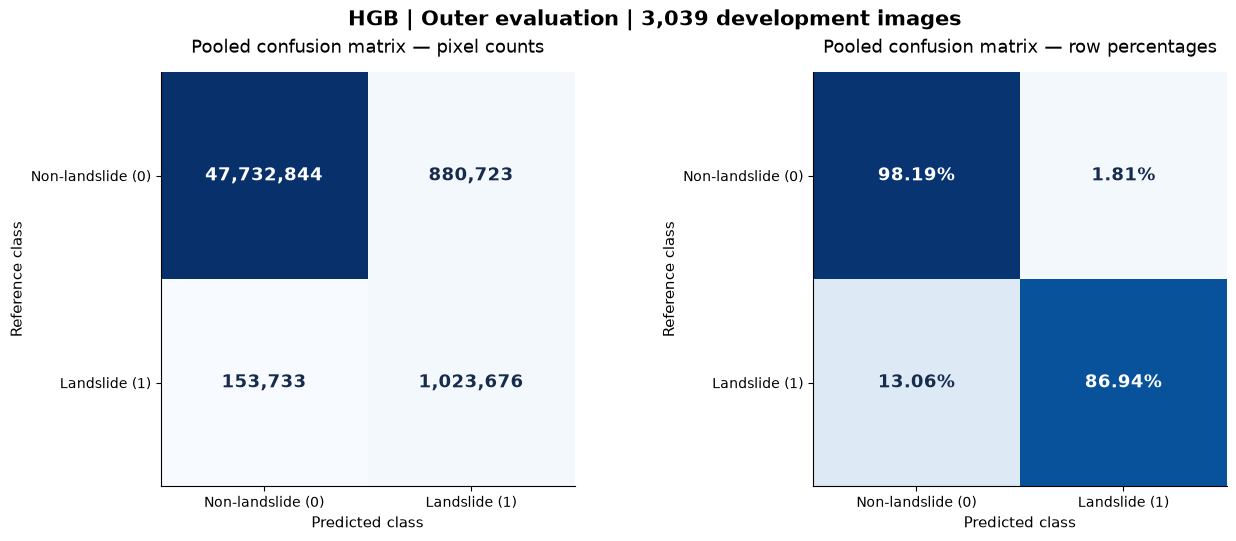

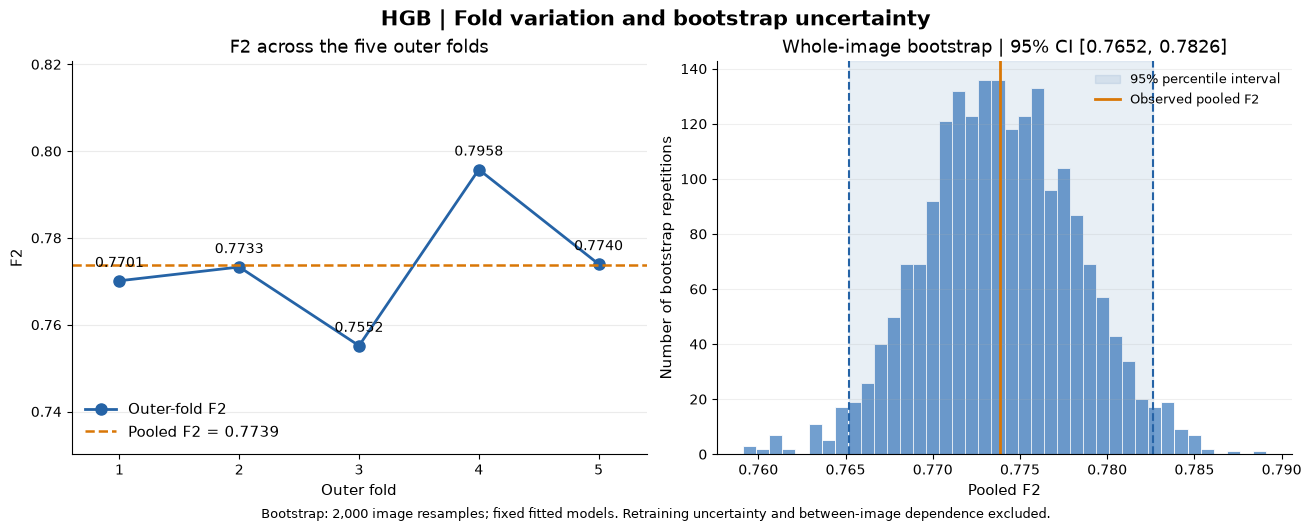

Figures saved as PNG and PDF:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\pooled_outer\1a573ca2f0263875d8ab\plots\outer_summary_v1


In [15]:
# HGB — Outer-evaluation figures from existing saved results.
# No training, predictions, or repeated bootstrap calculations.

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

summary = hgb_pooled_outer_summary
counts = summary["counts"]
pooled_f2 = summary["metrics"]["F2"]
lower, upper = summary["F2_bootstrap_95_interval"]

matrix = np.array([
    [counts["TN"], counts["FP"]],
    [counts["FN"], counts["TP"]]
], dtype=np.int64)

row_percent = (
    matrix / matrix.sum(axis=1, keepdims=True)
) * 100

plot_directory = hgb_pooled_folder / "plots" / "outer_summary_v1"
plot_directory.mkdir(parents=True, exist_ok=True)


def hgb_save_figure(fig, name):
    for extension in ("png", "pdf"):
        destination = plot_directory / f"{name}.{extension}"
        if not destination.exists():
            fig.savefig(
                destination,
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )


with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    # Figure 1: pooled confusion matrices.
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5.3), constrained_layout=True
    )

    class_labels = ["Non-landslide (0)", "Landslide (1)"]

    for ax, values, title, percentages in (
        (
            axes[0], matrix,
            "Pooled confusion matrix — pixel counts", False
        ),
        (
            axes[1], row_percent,
            "Pooled confusion matrix — row percentages", True
        ),
    ):
        maximum = 100 if percentages else float(matrix.max())

        ax.imshow(
            values, cmap="Blues",
            vmin=0, vmax=maximum
        )

        ax.set_xticks([0, 1], labels=class_labels)
        ax.set_yticks([0, 1], labels=class_labels)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Reference class")
        ax.set_title(title, pad=14)

        for row in range(2):
            for column in range(2):
                value = values[row, column]
                text = (
                    f"{value:.2f}%"
                    if percentages else f"{int(value):,}"
                )

                ax.text(
                    column, row, text,
                    ha="center", va="center",
                    fontsize=13, fontweight="bold",
                    color="white" if value > maximum / 2 else "#172B4D"
                )

        ax.set_ylim(1.5, -0.5)

    fig.suptitle(
        "HGB | Outer evaluation | 3,039 development images",
        fontsize=15, fontweight="bold"
    )
    hgb_save_figure(fig, "hgb_outer_confusion_matrices")
    plt.show()

    # Figure 2: fold stability and fixed-model image-bootstrap uncertainty.
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5.2), constrained_layout=True
    )

    fold_table = hgb_outer_metrics_table.sort_values("Outer_fold")
    folds = fold_table["Outer_fold"].to_numpy()
    fold_f2 = fold_table["F2"].to_numpy()

    axes[0].plot(
        folds, fold_f2,
        color="#2563A6", marker="o",
        markersize=8, linewidth=2,
        label="Outer-fold F2"
    )
    axes[0].axhline(
        pooled_f2, color="#D97706",
        linestyle="--", linewidth=1.8,
        label=f"Pooled F2 = {pooled_f2:.4f}"
    )

    for fold, value in zip(folds, fold_f2):
        axes[0].annotate(
            f"{value:.4f}",
            (fold, value),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center", fontsize=10
        )

    axes[0].set(
        title="F2 across the five outer folds",
        xlabel="Outer fold",
        ylabel="F2",
        xticks=folds,
        xlim=(0.6, 5.4)
    )
    axes[0].set_ylim(
        max(0, min(fold_f2.min(), pooled_f2) - 0.025),
        min(1, max(fold_f2.max(), pooled_f2) + 0.025)
    )
    axes[0].grid(axis="y", alpha=0.25)
    axes[0].legend(loc="lower left", frameon=False)

    bootstrap_values = summary["bootstrap_F2"]

    axes[1].hist(
        bootstrap_values,
        bins=40,
        color="#729FCF",
        edgecolor="white",
        linewidth=0.6
    )
    axes[1].axvspan(
        lower, upper,
        color="#2563A6", alpha=0.10,
        label="95% percentile interval"
    )
    axes[1].axvline(
        pooled_f2,
        color="#D97706", linewidth=2,
        label="Observed pooled F2"
    )
    axes[1].axvline(
        lower, color="#2563A6",
        linestyle="--", linewidth=1.5
    )
    axes[1].axvline(
        upper, color="#2563A6",
        linestyle="--", linewidth=1.5
    )

    axes[1].set(
        title=f"Whole-image bootstrap | 95% CI [{lower:.4f}, {upper:.4f}]",
        xlabel="Pooled F2",
        ylabel="Number of bootstrap repetitions"
    )
    axes[1].grid(axis="y", alpha=0.20)
    axes[1].legend(frameon=False, fontsize=9)

    fig.suptitle(
        "HGB | Fold variation and bootstrap uncertainty",
        fontsize=15, fontweight="bold"
    )
    fig.supxlabel(
        "Bootstrap: 2,000 image resamples; fixed fitted models. "
        "Retraining uncertainty and between-image dependence excluded.",
        fontsize=9
    )

    hgb_save_figure(fig, "hgb_outer_f2_stability_bootstrap")
    plt.show()

print("Figures saved as PNG and PDF:")
print(plot_directory)

Result: Across all 3,039 development images, the pooled outer F2 is 0.7739, with a 95% whole-image bootstrap interval of [0.7652, 0.7826]. The model detects 86.94% of landslide pixels and correctly rejects 98.19% of non-landslide pixels. However, 880,723 false-positive pixels against 1,023,676 true positives keep precision at 53.75%. F2 is stable across the outer folds, from 0.7552 (fold 3) to 0.7958 (fold 4). Overall performance is very close to the Random Forest (pooled F2 0.7761).

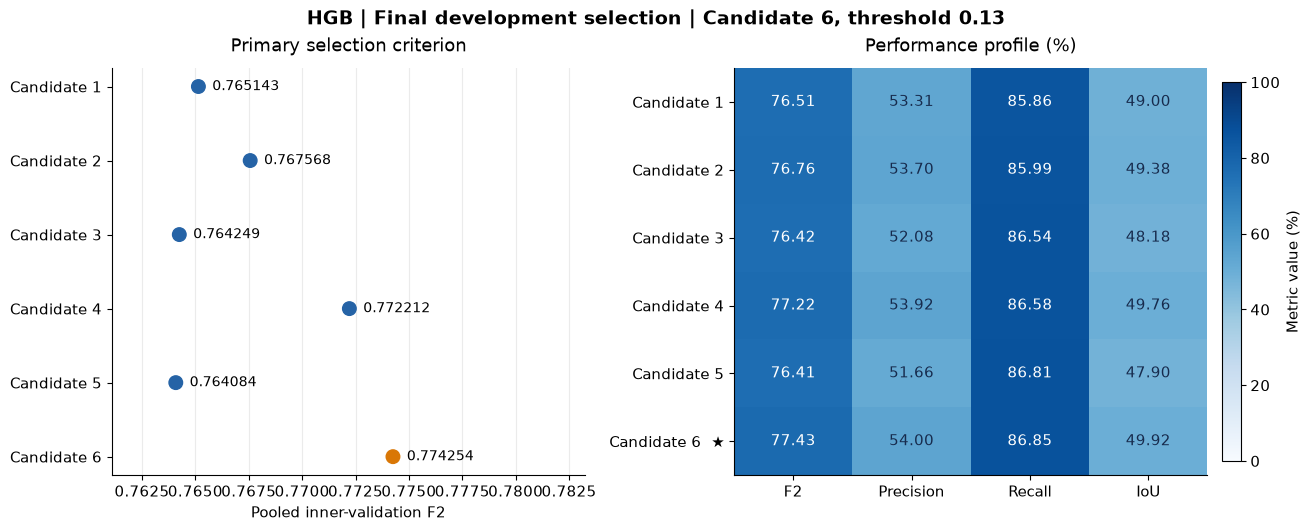

Final training: 3,039 images / 3,111,936 sampled pixels...

FINAL MODEL TRAINED AND SAVED
Training images: 3,039
Training pixels: 3,111,936
Locked threshold: 0.13
Additional calibration: none
Fit time: 62.6 seconds
Model: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\final_model\8dddd78f56454fa62513\model.joblib
Secondary test has not yet been evaluated.


In [16]:
# HGB — Step 12: visualize selection and fit/save the final model.
# One final fit only. No secondary-test evaluation.

import matplotlib.pyplot as plt

candidate_table = (
    hgb_final_selection["candidate_summary"]
    .sort_values("Candidate")
    .reset_index(drop=True)
)

selected_candidate = int(hgb_final_selection["selected_candidate"])
selected_threshold = float(hgb_final_selection["selected_threshold"])

# ------------------------------------------------------------
# 1. Visualize the completed candidate search.
# ------------------------------------------------------------
with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5.2), constrained_layout=True
    )

    positions = np.arange(len(candidate_table))
    selected_mask = (
        candidate_table["Candidate"].to_numpy() == selected_candidate
    )
    colors = [
        "#D97706" if selected else "#2563A6"
        for selected in selected_mask
    ]

    axes[0].scatter(
        candidate_table["F2"], positions,
        c=colors, s=95, zorder=3
    )

    for position, row in candidate_table.iterrows():
        axes[0].annotate(
            f"{row['F2']:.6f}",
            (row["F2"], position),
            xytext=(10, 0), textcoords="offset points",
            va="center", fontsize=10
        )

    axes[0].set_yticks(
        positions,
        [f"Candidate {int(c)}" for c in candidate_table["Candidate"]]
    )
    axes[0].invert_yaxis()
    axes[0].set_xlim(
        candidate_table["F2"].min() - 0.003,
        candidate_table["F2"].max() + 0.009
    )
    axes[0].set_xlabel("Pooled inner-validation F2")
    axes[0].set_title("Primary selection criterion", pad=12)
    axes[0].grid(axis="x", alpha=0.25)
    axes[0].set_axisbelow(True)

    metric_names = ["F2", "Precision", "Recall", "IoU"]
    values = candidate_table[metric_names].to_numpy() * 100

    heatmap = axes[1].imshow(
        values, cmap="Blues", vmin=0, vmax=100, aspect="auto"
    )
    axes[1].set_xticks(range(4), metric_names)
    axes[1].set_yticks(
        positions,
        [
            f"Candidate {int(c)}"
            + ("  ★" if int(c) == selected_candidate else "")
            for c in candidate_table["Candidate"]
        ]
    )
    axes[1].set_title("Performance profile (%)", pad=12)

    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values[row, column]
            axes[1].text(
                column, row, f"{value:.2f}",
                ha="center", va="center",
                color="white" if value >= 65 else "#172B4D"
            )

    fig.colorbar(
        heatmap, ax=axes[1], fraction=0.04, pad=0.03,
        label="Metric value (%)"
    )
    fig.suptitle(
        f"HGB | Final development selection | "
        f"Candidate {selected_candidate}, threshold {selected_threshold:.2f}",
        fontsize=14, fontweight="bold"
    )

    figure_folder = hgb_final_selection_folder / "plots"
    figure_folder.mkdir(parents=True, exist_ok=True)

    for extension in ("png", "pdf"):
        figure_path = figure_folder / (
            f"candidate_selection_v1.{extension}"
        )
        if not figure_path.exists():
            fig.savefig(
                figure_path, dpi=300,
                bbox_inches="tight", facecolor="white"
            )

    plt.show()


# ------------------------------------------------------------
# 2. Lock the specification and fit the final model once.
# ------------------------------------------------------------
hgb_final_specification = {
    "version": "hgb_final_model_v1",
    "parameters": hgb_final_selection["selected_parameters"],
    "threshold": selected_threshold,
    "calibration": hgb_final_selection["calibration"],
    "feature_names": hgb_feature_names,
    "development_ids": hgb_development_ids,
    "pixels_per_image": 1024,
    "training_pixels": 3039 * 1024,
    "sklearn_version": sklearn.__version__,
    "selection_file": str(hgb_final_selection_file),
}

assert hgb_final_specification["parameters"]["random_state"] == 43
assert hgb_final_specification["calibration"] == "none"

hgb_final_model_directory = (
    hgb_search_root / "final_model"
    / hgb_signature(hgb_final_specification)
)
hgb_final_model_directory.mkdir(parents=True, exist_ok=True)

hgb_final_model_file = hgb_final_model_directory / "model.joblib"

if hgb_final_model_file.is_file():
    final_checkpoint = joblib.load(hgb_final_model_file)
    assert final_checkpoint["specification"] == hgb_final_specification

    hgb_final_model = final_checkpoint["model"]
    final_fit_seconds = final_checkpoint["fit_seconds"]
    print("Saved final model restored; no retraining.")

else:
    final_rows = np.asarray([
        hgb_image_to_row[image_id]
        for image_id in hgb_development_ids
    ])

    X_final = hgb_X_by_image[final_rows].reshape(-1, 14)
    y_final = hgb_y_by_image[final_rows].reshape(-1)

    assert X_final.shape == (3111936, 14)
    assert y_final.shape == (3111936,)

    hgb_final_model = HistGradientBoostingClassifier(
        **hgb_final_specification["parameters"]
    )

    print(
        "Final training: 3,039 images / 3,111,936 sampled pixels...",
        flush=True
    )
    started = time.perf_counter()

    with threadpool_limits(limits=HGB_THREADS):
        hgb_final_model.fit(X_final, y_final)

    final_fit_seconds = time.perf_counter() - started
    del X_final, y_final

    hgb_atomic_save(
        {
            "specification": hgb_final_specification,
            "model": hgb_final_model,
            "fit_seconds": final_fit_seconds,
        },
        hgb_final_model_file
    )

# Registry is scoped to this exact final-model directory.
hgb_final_registry = {
    "model_path": str(hgb_final_model_file),
    "model_directory": str(hgb_final_model_directory),
    "locked_specification": hgb_final_specification,
}
hgb_atomic_save(
    hgb_final_registry,
    hgb_final_model_directory / "final_model_registry.joblib"
)

print("\nFINAL MODEL TRAINED AND SAVED")
print("Training images: 3,039")
print("Training pixels: 3,111,936")
print("Locked threshold:", selected_threshold)
print("Additional calibration:", hgb_final_specification["calibration"])
print(f"Fit time: {final_fit_seconds:.1f} seconds")
print("Model:", hgb_final_model_file)
print("Secondary test has not yet been evaluated.")

Result: The heatmap shows that all six candidates perform similarly (F2 0.764–0.774). Candidate 6 is best on F2, recall, and IoU, so the choice is consistent but the margin is small. The final model was trained once on all 3,039 development images (3,111,936 sampled pixels) in 62.6 s, with the threshold locked at 0.13 and no calibration. It was saved before any secondary-test evaluation.

Evaluating 760 secondary-test images...
Evaluated 64/760 images | 18.2 s
Evaluated 128/760 images | 44.9 s
Evaluated 192/760 images | 63.7 s
Evaluated 256/760 images | 99.6 s
Evaluated 320/760 images | 131.9 s
Evaluated 384/760 images | 161.4 s
Evaluated 448/760 images | 193.3 s
Evaluated 512/760 images | 225.7 s
Evaluated 576/760 images | 259.0 s
Evaluated 640/760 images | 281.5 s
Evaluated 704/760 images | 289.6 s
Evaluated 760/760 images | 300.1 s
Calculating ROC_AUC...
Calculating Average_precision...

HGB SECONDARY TEST — LOCKED THRESHOLD 0.13
F2: 0.766319
Precision: 0.527405
Recall: 0.864188
Specificity: 0.983137
IoU: 0.487037
ROC_AUC: 0.990712
Average_precision: 0.773601
Brier_score: 0.009017
Log_loss: 0.031065

Confusion counts: {'TN': 11980954, 'FP': 205505, 'FN': 36042, 'TP': 229339}
F2 95% whole-image bootstrap interval: [0.747130, 0.784481]
Secondary/exploratory evaluation; no tuning on these results.
CI excludes retraining uncertainty and between-image dependence.
Saved: C

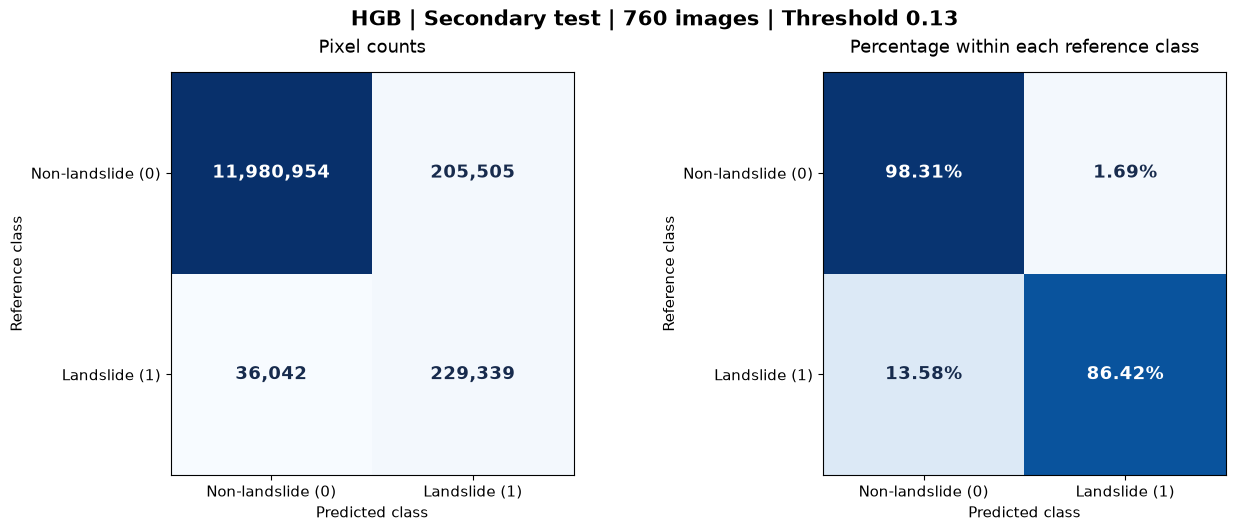

In [17]:
# HGB — Step 13: locked-model secondary-test evaluation.
# No training, tuning, calibration fitting, or threshold changes.

import matplotlib.pyplot as plt

hgb_test_ids = list(hgb_secondary_test_ids)
hgb_test_threshold = float(hgb_final_specification["threshold"])

assert len(hgb_test_ids) == len(set(hgb_test_ids)) == 760
assert set(hgb_test_ids).isdisjoint(hgb_development_id_set)
assert hgb_test_threshold == 0.13

hgb_test_specification = {
    "version": "hgb_secondary_test_v1",
    "locked_model": hgb_final_specification,
    "test_ids": hgb_test_ids,
    "bootstrap_repetitions": 2000,
    "random_state": 43,
    "source_files": [
        hgb_file_stamp(path)
        for image_id in hgb_test_ids
        for path in (
            hgb_image_dir / f"image_{image_id}.h5",
            hgb_mask_dir / f"mask_{image_id}.h5"
        )
    ],
}

hgb_test_directory = (
    hgb_final_model_directory / "secondary_test"
    / hgb_signature(hgb_test_specification)
)
hgb_test_directory.mkdir(parents=True, exist_ok=True)

hgb_test_result_file = hgb_test_directory / "evaluation.joblib"
hgb_test_progress_file = hgb_test_directory / "progress.joblib"
hgb_test_scores_file = hgb_test_directory / "scores.npy"
hgb_test_labels_file = hgb_test_directory / "labels.npy"

if hgb_test_result_file.is_file():
    hgb_secondary_result = joblib.load(hgb_test_result_file)
    assert (
        hgb_secondary_result["specification"]
        == hgb_test_specification
    )
    print("Completed secondary-test evaluation restored.")

else:
    test_shape = (760, 128 * 128)

    if hgb_test_progress_file.is_file():
        progress = joblib.load(hgb_test_progress_file)
        assert progress["specification"] == hgb_test_specification

        completed = progress["completed_images"]
        test_rows = progress["per_image_rows"]
        previous_seconds = progress["evaluation_seconds"]

        test_scores = np.load(hgb_test_scores_file, mmap_mode="r+")
        test_labels = np.load(hgb_test_labels_file, mmap_mode="r+")

        assert test_scores.shape == test_labels.shape == test_shape
        assert len(test_rows) == completed

    else:
        completed = 0
        test_rows = []
        previous_seconds = 0.0

        test_scores = np.lib.format.open_memmap(
            hgb_test_scores_file,
            mode="w+", dtype=np.float64, shape=test_shape
        )
        test_labels = np.lib.format.open_memmap(
            hgb_test_labels_file,
            mode="w+", dtype=np.uint8, shape=test_shape
        )

    started = time.perf_counter()
    epsilon = np.finfo(np.float64).eps

    print("Evaluating 760 secondary-test images...", flush=True)

    with threadpool_limits(limits=HGB_THREADS):
        for start in range(completed, 760, 8):
            stop = min(start + 8, 760)
            batch_ids = hgb_test_ids[start:stop]

            pairs = [
                hgb_load_source_pair(image_id)
                for image_id in batch_ids
            ]
            batch_X = np.concatenate([pair[0] for pair in pairs])
            batch_y = np.stack([pair[1] for pair in pairs])

            probabilities = hgb_final_model.predict_proba(
                batch_X
            )[:, 1].reshape(len(batch_ids), -1)

            assert np.isfinite(probabilities).all()
            assert np.all(
                (probabilities >= 0) & (probabilities <= 1)
            )

            test_scores[start:stop] = probabilities
            test_labels[start:stop] = batch_y

            for offset, image_id in enumerate(batch_ids):
                y_true = batch_y[offset]
                probability = probabilities[offset]
                positive = y_true == 1
                predicted = probability >= hgb_test_threshold

                clipped = np.clip(
                    probability, epsilon, 1 - epsilon
                )

                test_rows.append({
                    "image_id": image_id,
                    "TN": int(np.count_nonzero(~predicted & ~positive)),
                    "FP": int(np.count_nonzero(predicted & ~positive)),
                    "FN": int(np.count_nonzero(~predicted & positive)),
                    "TP": int(np.count_nonzero(predicted & positive)),
                    "n_pixels": int(y_true.size),
                    "brier_sum": float(np.sum(
                        (probability - y_true) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        y_true * np.log(clipped)
                        + (1 - y_true) * np.log1p(-clipped)
                    )),
                })

            if stop % 64 == 0 or stop == 760:
                test_scores.flush()
                test_labels.flush()

                elapsed = (
                    previous_seconds + time.perf_counter() - started
                )
                hgb_atomic_save(
                    {
                        "specification": hgb_test_specification,
                        "completed_images": stop,
                        "per_image_rows": test_rows,
                        "evaluation_seconds": elapsed,
                    },
                    hgb_test_progress_file
                )
                print(
                    f"Evaluated {stop}/760 images | {elapsed:.1f} s",
                    flush=True
                )

            del pairs, batch_X, batch_y, probabilities

    evaluation_seconds = (
        previous_seconds + time.perf_counter() - started
    )

    test_per_image = pd.DataFrame(test_rows)
    assert test_per_image["image_id"].tolist() == hgb_test_ids
    assert np.all(
        test_per_image[["TN", "FP", "FN", "TP"]].sum(axis=1)
        == 128 * 128
    )

    test_counts = {
        name: int(test_per_image[name].sum())
        for name in ("TN", "FP", "FN", "TP")
    }
    n_test_pixels = int(test_per_image["n_pixels"].sum())
    assert n_test_pixels == 12_451_840

    test_metrics = {
        name: float(value)
        for name, value in hgb_metrics_from_counts(test_counts).items()
    }

    # Cache ranking metrics separately.
    for name, function in (
        ("ROC_AUC", roc_auc_score),
        ("Average_precision", average_precision_score),
    ):
        metric_file = hgb_test_directory / f"{name}.joblib"

        if metric_file.is_file():
            test_metrics[name] = float(joblib.load(metric_file))
        else:
            print(f"Calculating {name}...", flush=True)
            test_metrics[name] = float(function(
                test_labels.reshape(-1),
                test_scores.reshape(-1)
            ))
            hgb_atomic_save(test_metrics[name], metric_file)

    test_metrics["Brier_score"] = float(
        test_per_image["brier_sum"].sum() / n_test_pixels
    )
    test_metrics["Log_loss"] = float(
        test_per_image["log_loss_sum"].sum() / n_test_pixels
    )

    # Whole-image bootstrap; fitted model and threshold stay fixed.
    image_counts = test_per_image[
        ["TN", "FP", "FN", "TP"]
    ].to_numpy(dtype=np.int64)

    rng = np.random.default_rng(43)
    test_bootstrap_f2 = np.empty(2000)

    for start in range(0, 2000, 100):
        stop = min(start + 100, 2000)
        indices = rng.integers(
            0, 760, size=(stop - start, 760)
        )
        tn, fp, fn, tp = image_counts[indices].sum(axis=1).T
        test_bootstrap_f2[start:stop] = hgb_ratio(
            5 * tp, 5 * tp + 4 * fn + fp
        )

    test_interval = np.quantile(
        test_bootstrap_f2, [0.025, 0.975]
    )

    hgb_secondary_result = {
        "specification": hgb_test_specification,
        "threshold": hgb_test_threshold,
        "ordered_image_ids": hgb_test_ids,
        "metrics": test_metrics,
        "counts": test_counts,
        "per_image": test_per_image,
        "n_pixels": n_test_pixels,
        "F2_bootstrap_95_interval": test_interval,
        "bootstrap_F2": test_bootstrap_f2,
        "scores_path": str(hgb_test_scores_file),
        "labels_path": str(hgb_test_labels_file),
        "evaluation_seconds": evaluation_seconds,
    }

    hgb_atomic_save(
        hgb_secondary_result, hgb_test_result_file
    )
    del test_scores, test_labels


# ------------------------------------------------------------
# Display all results compactly.
# ------------------------------------------------------------
print("\nHGB SECONDARY TEST — LOCKED THRESHOLD 0.13")

for name in (
    "F2", "Precision", "Recall", "Specificity", "IoU",
    "ROC_AUC", "Average_precision", "Brier_score", "Log_loss"
):
    print(f"{name}: {hgb_secondary_result['metrics'][name]:.6f}")

print("\nConfusion counts:", hgb_secondary_result["counts"])

lower, upper = hgb_secondary_result["F2_bootstrap_95_interval"]
print(f"F2 95% whole-image bootstrap interval: [{lower:.6f}, {upper:.6f}]")
print("Secondary/exploratory evaluation; no tuning on these results.")
print("CI excludes retraining uncertainty and between-image dependence.")
print("Saved:", hgb_test_result_file)


# ------------------------------------------------------------
# Visualizations: counts and class-specific percentages.
# ------------------------------------------------------------
counts = hgb_secondary_result["counts"]
matrix = np.array([
    [counts["TN"], counts["FP"]],
    [counts["FN"], counts["TP"]]
])
percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100

with plt.rc_context({"font.size": 11}):
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5.2), constrained_layout=True
    )

    for ax, values, title, is_percent in (
        (axes[0], matrix, "Pixel counts", False),
        (axes[1], percentages, "Percentage within each reference class", True),
    ):
        maximum = 100 if is_percent else matrix.max()
        ax.imshow(values, cmap="Blues", vmin=0, vmax=maximum)

        ax.set_xticks([0, 1], ["Non-landslide (0)", "Landslide (1)"])
        ax.set_yticks([0, 1], ["Non-landslide (0)", "Landslide (1)"])
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Reference class")
        ax.set_title(title, pad=14)

        for row in range(2):
            for column in range(2):
                value = values[row, column]
                label = (
                    f"{value:.2f}%"
                    if is_percent else f"{int(value):,}"
                )
                ax.text(
                    column, row, label,
                    ha="center", va="center",
                    fontsize=13, fontweight="bold",
                    color="white" if value > maximum / 2 else "#172B4D"
                )

    fig.suptitle(
        "HGB | Secondary test | 760 images | Threshold 0.13",
        fontsize=15, fontweight="bold"
    )

    figure_directory = hgb_test_directory / "plots"
    figure_directory.mkdir(parents=True, exist_ok=True)

    for extension in ("png", "pdf"):
        path = figure_directory / f"secondary_confusion_v1.{extension}"
        if not path.exists():
            fig.savefig(
                path, dpi=300, bbox_inches="tight", facecolor="white"
            )

    plt.show()

Result: On the 760 held-out test images, the locked model reached F2 = 0.7663 (95% bootstrap interval [0.7471, 0.7845]), with recall 86.42%, precision 52.74%, specificity 98.31%, and IoU 0.4870. Ranking quality is high (ROC-AUC 0.9907, AP 0.7736), and probabilities are well calibrated overall (Brier 0.0090). The test F2 lies within the development bootstrap interval, so performance generalizes without a meaningful drop. As in development, the main weakness is false positives: about 1 in 2 predicted landslide pixels is incorrect. This is a secondary, exploratory evaluation, and nothing was tuned on these results.

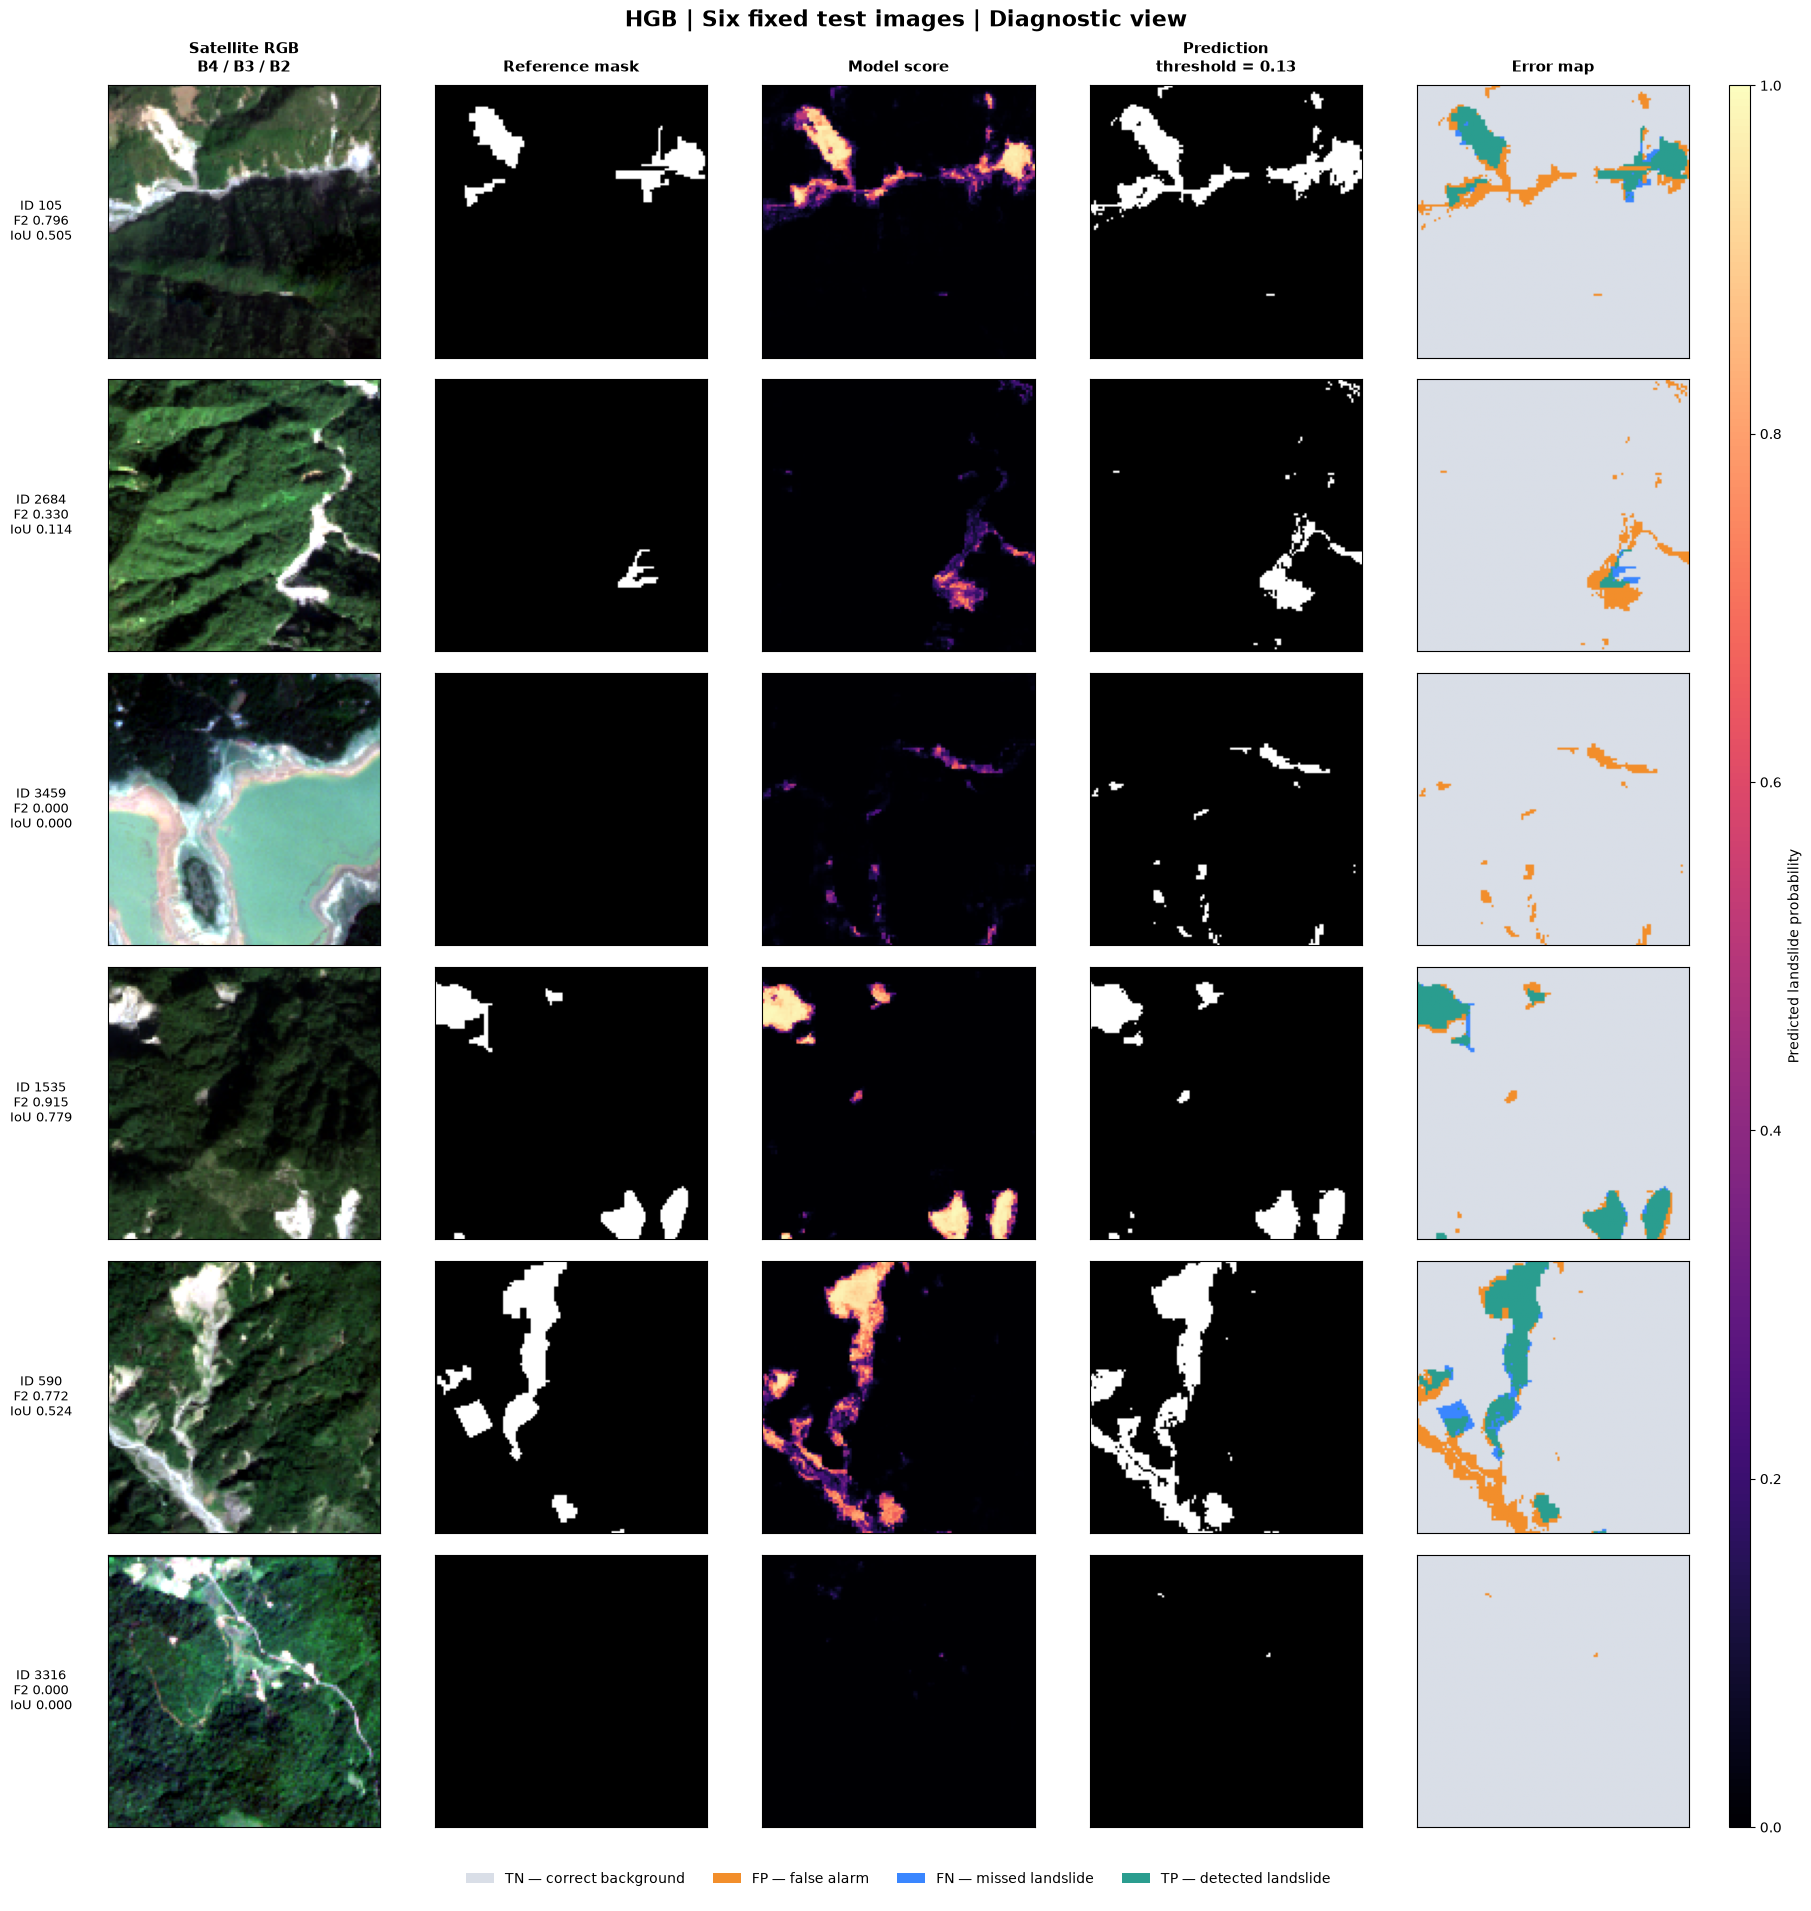

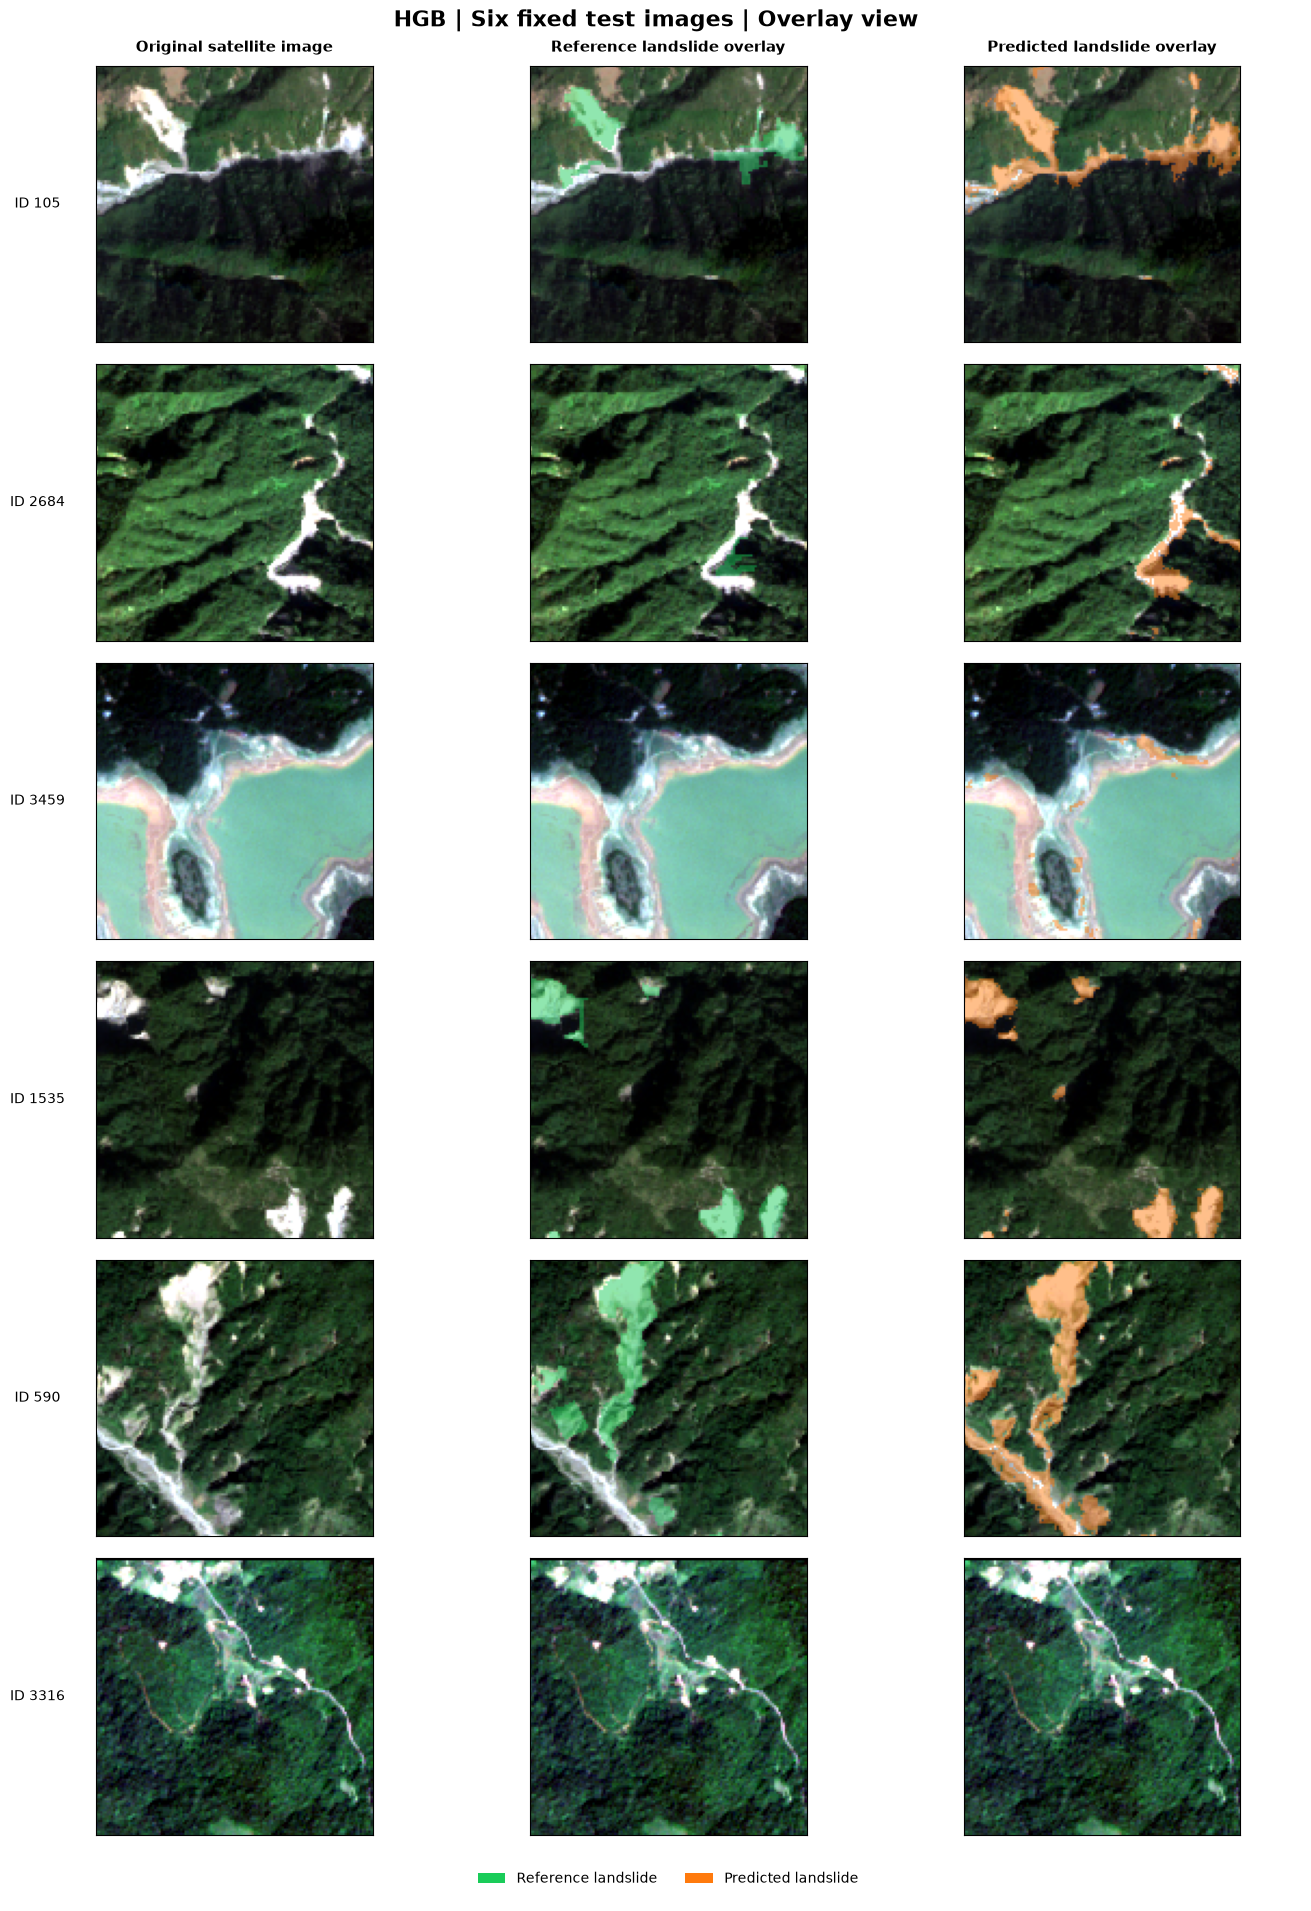

Image order: ['105', '2684', '3459', '1535', '590', '3316']
Corrected figures saved in: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\final_model\8dddd78f56454fa62513\secondary_test\d73d65ca6143672e1b4e\plots\six_fixed_images


In [19]:
# HGB — Six fixed spatial examples.
# Complete cell: load saved predictions, verify masks, and create both figures.
# No model training or new predictions.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from pathlib import Path

HGB_FIXED_IMAGE_IDS = ["105", "2684", "3459", "1535", "590", "3316"]
HGB_THRESHOLD = 0.13

assert "hgb_secondary_result" in globals(), (
    "Run the secondary-test evaluation cell first."
)
assert "hgb_load_source_pair" in globals(), (
    "Run the cell that defines the source image and mask loader first."
)

test_ids = [
    str(value)
    for value in hgb_secondary_result["ordered_image_ids"]
]
test_id_to_row = {
    image_id: row
    for row, image_id in enumerate(test_ids)
}

missing_ids = [
    image_id for image_id in HGB_FIXED_IMAGE_IDS
    if image_id not in test_id_to_row
]
assert not missing_ids, (
    f"Fixed image IDs absent from the secondary-test set: {missing_ids}"
)

scores = np.load(
    hgb_secondary_result["scores_path"],
    mmap_mode="r",
    allow_pickle=False
)
saved_labels = np.load(
    hgb_secondary_result["labels_path"],
    mmap_mode="r",
    allow_pickle=False
)

feature_index = {
    name: index for index, name in enumerate(hgb_feature_names)
}
rgb_channels = [
    feature_index["B4"],
    feature_index["B3"],
    feature_index["B2"],
]

examples = []

for image_id in HGB_FIXED_IMAGE_IDS:
    row = test_id_to_row[image_id]

    image_features, reference_flat = hgb_load_source_pair(image_id)
    reference = reference_flat.reshape(128, 128).astype(bool)

    # Verify that saved test labels match the original source mask.
    saved_reference = saved_labels[row].reshape(128, 128).astype(bool)
    assert np.array_equal(saved_reference, reference), (
        f"Saved labels do not match the source mask for image {image_id}."
    )

    probability = np.asarray(scores[row]).reshape(128, 128)
    prediction = probability >= HGB_THRESHOLD

    # RGB uses B4/B3/B2 with per-channel 2nd–98th percentile stretching.
    rgb_raw = image_features[:, rgb_channels].reshape(128, 128, 3)
    rgb = np.zeros_like(rgb_raw, dtype=np.float32)

    for channel in range(3):
        low, high = np.percentile(rgb_raw[:, :, channel], [2, 98])
        if high > low:
            rgb[:, :, channel] = np.clip(
                (rgb_raw[:, :, channel] - low) / (high - low),
                0,
                1
            )

    tp = int(np.count_nonzero(prediction & reference))
    fp = int(np.count_nonzero(prediction & ~reference))
    fn = int(np.count_nonzero(~prediction & reference))

    f2_denominator = 5 * tp + 4 * fn + fp
    iou_denominator = tp + fp + fn

    image_f2 = (
        5 * tp / f2_denominator
        if f2_denominator else 0.0
    )
    image_iou = (
        tp / iou_denominator
        if iou_denominator else 0.0
    )

    # Error classes: TN=0, FP=1, FN=2, TP=3.
    error_map = np.zeros((128, 128), dtype=np.uint8)
    error_map[prediction & ~reference] = 1
    error_map[~prediction & reference] = 2
    error_map[prediction & reference] = 3

    examples.append({
        "image_id": image_id,
        "rgb": rgb,
        "reference": reference,
        "probability": probability,
        "prediction": prediction,
        "error_map": error_map,
        "f2": image_f2,
        "iou": image_iou,
    })

del scores, saved_labels

plot_directory = (
    Path(hgb_test_directory) / "plots" / "six_fixed_images"
)
plot_directory.mkdir(parents=True, exist_ok=True)

# Error-map meanings are the same in every row.
error_cmap = ListedColormap([
    "#D9DEE7",  # TN: correct background
    "#F28E2B",  # FP: false alarm
    "#3A86FF",  # FN: missed landslide
    "#2A9D8F",  # TP: detected landslide
])
error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    error_cmap.N
)

with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 11,
}):
    # --------------------------------------------------------
    # Figure 1: five diagnostic panels per image.
    # The colorbar has a dedicated column outside all images.
    # The error legend has a dedicated row below the images.
    # --------------------------------------------------------
    fig = plt.figure(figsize=(18, 19), layout="constrained")
    grid = fig.add_gridspec(
        7, 6,
        width_ratios=[1, 1, 1, 1, 1, 0.07],
        height_ratios=[1, 1, 1, 1, 1, 1, 0.16],
        wspace=0.08,
        hspace=0.08,
    )

    axes = np.array([
        [fig.add_subplot(grid[row, column]) for column in range(5)]
        for row in range(6)
    ])
    colorbar_axis = fig.add_subplot(grid[:6, 5])
    legend_axis = fig.add_subplot(grid[6, :5])
    legend_axis.axis("off")

    diagnostic_titles = [
        "Satellite RGB\nB4 / B3 / B2",
        "Reference mask",
        "Model score",
        "Prediction\nthreshold = 0.13",
        "Error map",
    ]

    for column, title in enumerate(diagnostic_titles):
        axes[0, column].set_title(
            title, pad=10, fontweight="bold"
        )

    for row, item in enumerate(examples):
        axes[row, 0].imshow(item["rgb"], origin="upper")
        axes[row, 1].imshow(
            item["reference"], cmap="gray",
            vmin=0, vmax=1, origin="upper"
        )
        score_artist = axes[row, 2].imshow(
            item["probability"], cmap="magma",
            vmin=0, vmax=1, origin="upper"
        )
        axes[row, 3].imshow(
            item["prediction"], cmap="gray",
            vmin=0, vmax=1, origin="upper"
        )
        axes[row, 4].imshow(
            item["error_map"], cmap=error_cmap,
            norm=error_norm, origin="upper"
        )

        axes[row, 0].set_ylabel(
            f"ID {item['image_id']}\n"
            f"F2 {item['f2']:.3f}\n"
            f"IoU {item['iou']:.3f}",
            rotation=0,
            labelpad=48,
            va="center",
            fontsize=9,
        )

        for axis in axes[row]:
            axis.set_xticks([])
            axis.set_yticks([])
            axis.set_aspect("equal")

    colorbar = fig.colorbar(score_artist, cax=colorbar_axis)
    colorbar.set_label("Predicted landslide probability")

    error_legend = [
        Patch(facecolor="#D9DEE7", label="TN — correct background"),
        Patch(facecolor="#F28E2B", label="FP — false alarm"),
        Patch(facecolor="#3A86FF", label="FN — missed landslide"),
        Patch(facecolor="#2A9D8F", label="TP — detected landslide"),
    ]
    legend_axis.legend(
        handles=error_legend,
        loc="center",
        ncol=4,
        frameon=False,
        fontsize=10,
    )

    fig.suptitle(
        "HGB | Six fixed test images | Diagnostic view",
        fontsize=16,
        fontweight="bold",
    )

    for extension in ("png", "pdf"):
        fig.savefig(
            plot_directory / (
                f"hgb_six_image_diagnostics_corrected.{extension}"
            ),
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()

    # --------------------------------------------------------
    # Figure 2: original RGB and reference/prediction overlays.
    # The legend is in its own row, below all image panels.
    # --------------------------------------------------------
    fig = plt.figure(figsize=(13, 19), layout="constrained")
    grid = fig.add_gridspec(
        7, 3,
        height_ratios=[1, 1, 1, 1, 1, 1, 0.16],
        wspace=0.08,
        hspace=0.08,
    )

    overlay_axes = np.array([
        [fig.add_subplot(grid[row, column]) for column in range(3)]
        for row in range(6)
    ])
    overlay_legend_axis = fig.add_subplot(grid[6, :])
    overlay_legend_axis.axis("off")

    overlay_titles = [
        "Original satellite image",
        "Reference landslide overlay",
        "Predicted landslide overlay",
    ]

    for column, title in enumerate(overlay_titles):
        overlay_axes[0, column].set_title(
            title, pad=10, fontweight="bold"
        )

    green = np.array([0.10, 0.80, 0.35], dtype=np.float32)
    orange = np.array([1.00, 0.48, 0.05], dtype=np.float32)
    alpha = 0.48

    for row, item in enumerate(examples):
        reference_overlay = item["rgb"].copy()
        reference_overlay[item["reference"]] = (
            (1 - alpha) * reference_overlay[item["reference"]]
            + alpha * green
        )

        prediction_overlay = item["rgb"].copy()
        prediction_overlay[item["prediction"]] = (
            (1 - alpha) * prediction_overlay[item["prediction"]]
            + alpha * orange
        )

        for column, visual in enumerate((
            item["rgb"],
            reference_overlay,
            prediction_overlay,
        )):
            overlay_axes[row, column].imshow(
                visual, origin="upper"
            )
            overlay_axes[row, column].set_xticks([])
            overlay_axes[row, column].set_yticks([])
            overlay_axes[row, column].set_aspect("equal")

        overlay_axes[row, 0].set_ylabel(
            f"ID {item['image_id']}",
            rotation=0,
            labelpad=42,
            va="center",
            fontsize=10,
        )

    overlay_legend = [
        Patch(facecolor=green, label="Reference landslide"),
        Patch(facecolor=orange, label="Predicted landslide"),
    ]
    overlay_legend_axis.legend(
        handles=overlay_legend,
        loc="center",
        ncol=2,
        frameon=False,
        fontsize=10,
    )

    fig.suptitle(
        "HGB | Six fixed test images | Overlay view",
        fontsize=16,
        fontweight="bold",
    )

    for extension in ("png", "pdf"):
        fig.savefig(
            plot_directory / (
                f"hgb_six_image_overlays_corrected.{extension}"
            ),
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()

print("Image order:", HGB_FIXED_IMAGE_IDS)
print("Corrected figures saved in:", plot_directory)

Summarizing saved test predictions...
Locked-threshold count check: PASS
Calibration ECE, 15 uniform bins: 0.001834
Calibration MCE, 15 uniform bins: 0.086526
Exact saved ROC-AUC: 0.990712
Exact saved Average Precision: 0.773601


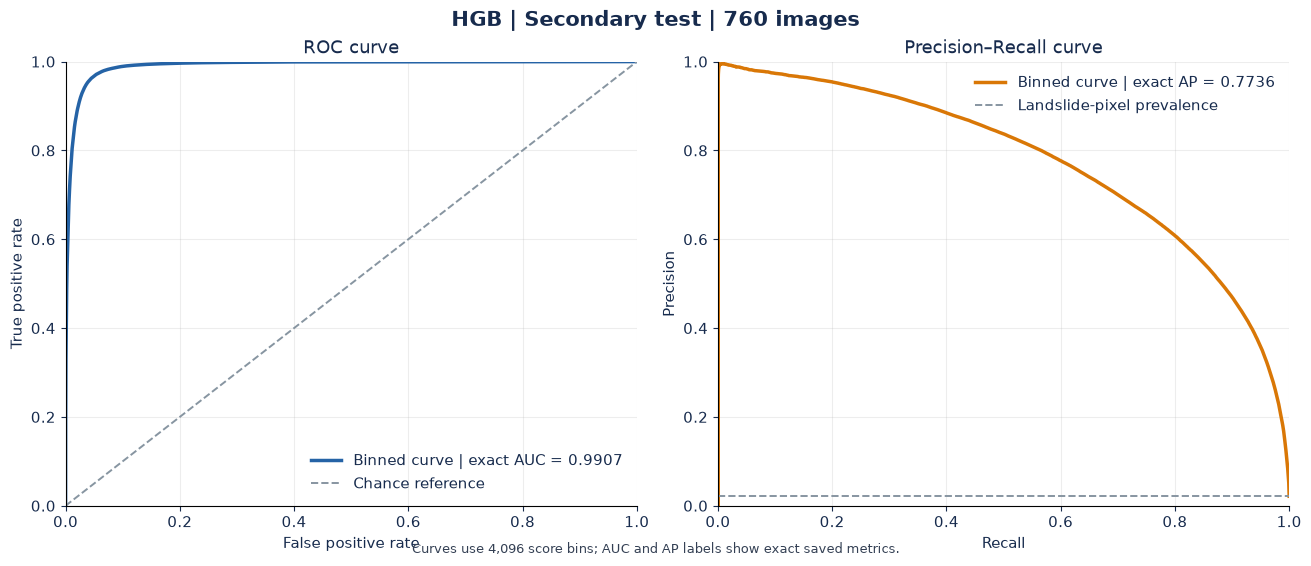

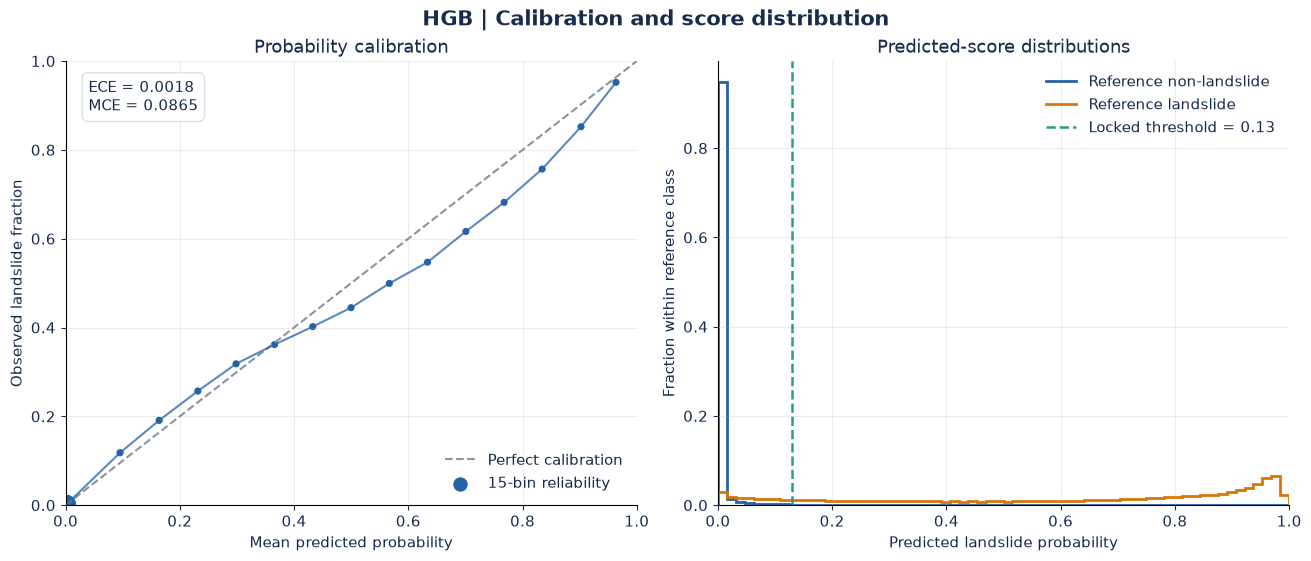

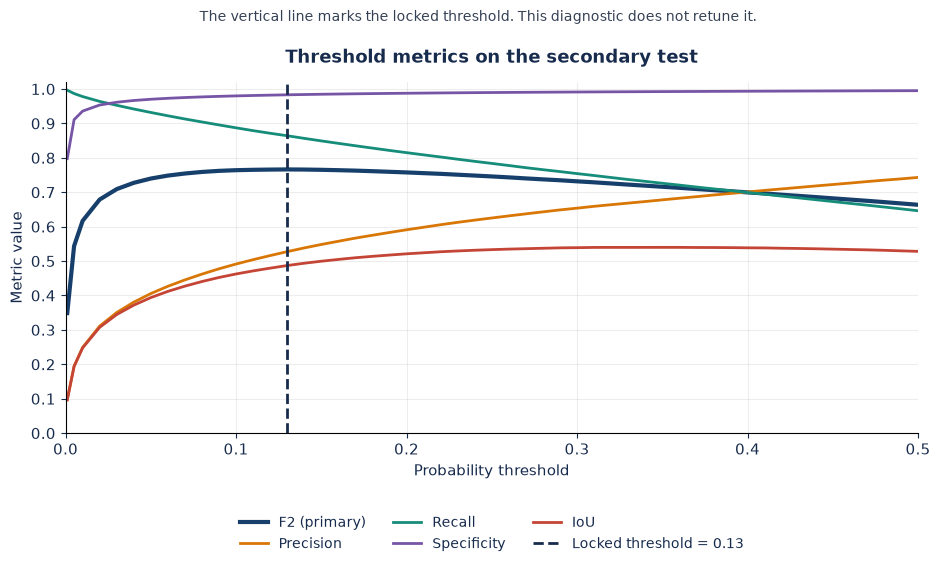


Diagnostic figures saved in: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\final_model\8dddd78f56454fa62513\secondary_test\d73d65ca6143672e1b4e\plots\test_diagnostics_v2


In [21]:
# HGB — Step 15: ROC, PR, calibration, and threshold diagnostics.
# Uses saved secondary-test scores and labels only.
# Does not train, predict, or change the locked threshold.

from pathlib import Path
import joblib
import numpy as np
import matplotlib.pyplot as plt

# Restore the saved test result if it is not already in memory.
if "hgb_secondary_result" not in globals():
    if "hgb_test_result_file" in globals():
        result_path = Path(hgb_test_result_file)
        if result_path.is_file():
            hgb_secondary_result = joblib.load(result_path)

    if "hgb_secondary_result" not in globals():
        if "hgb_final_model_directory" not in globals():
            raise RuntimeError(
                "Saved secondary-test results are not loaded. "
                "Run the test-evaluation cell first."
            )

        candidates = list(
            Path(hgb_final_model_directory)
            .glob("secondary_test/*/evaluation.joblib")
        )
        if not candidates:
            raise FileNotFoundError(
                "No saved secondary-test evaluation was found."
            )

        result_path = max(
            candidates,
            key=lambda path: path.stat().st_mtime
        )
        hgb_secondary_result = joblib.load(result_path)

test_result = hgb_secondary_result
locked_threshold = float(test_result["threshold"])

assert np.isclose(locked_threshold, 0.13), (
    f"Expected locked threshold 0.13, found {locked_threshold}."
)

scores = np.load(
    test_result["scores_path"],
    mmap_mode="r",
    allow_pickle=False
)
labels = np.load(
    test_result["labels_path"],
    mmap_mode="r",
    allow_pickle=False
)

assert scores.shape == labels.shape == (760, 128 * 128)

# Histograms for score curves and calibration.
score_bin_count = 4096
positive_score_hist = np.zeros(score_bin_count, dtype=np.int64)
negative_score_hist = np.zeros(score_bin_count, dtype=np.int64)

calibration_bin_count = 15
calibration_count = np.zeros(calibration_bin_count, dtype=np.int64)
calibration_score_sum = np.zeros(calibration_bin_count, dtype=np.float64)
calibration_positive_sum = np.zeros(calibration_bin_count, dtype=np.float64)

# Use the saved development threshold grid if it is available.
if "hgb_thresholds" in globals():
    thresholds = np.asarray(hgb_thresholds, dtype=float)
else:
    thresholds = np.unique(
        np.r_[np.arange(0.001, 0.501, 0.005), locked_threshold]
    )

thresholds = np.unique(np.r_[thresholds, locked_threshold])
positive_threshold_hist = np.zeros(len(thresholds) + 1, dtype=np.int64)
negative_threshold_hist = np.zeros(len(thresholds) + 1, dtype=np.int64)

print("Summarizing saved test predictions...", flush=True)

# Process 32 images per block to keep memory use bounded.
for start in range(0, scores.shape[0], 32):
    stop = min(start + 32, scores.shape[0])

    probability = np.asarray(scores[start:stop]).reshape(-1)
    y_true = np.asarray(labels[start:stop]).reshape(-1)

    assert np.isfinite(probability).all()
    assert np.isin(y_true, [0, 1]).all()

    positive = y_true == 1
    negative = ~positive

    # Score histograms for the binned ROC and PR curves.
    score_bins = np.minimum(
        (probability * score_bin_count).astype(np.int32),
        score_bin_count - 1
    )
    positive_score_hist += np.bincount(
        score_bins[positive], minlength=score_bin_count
    )
    negative_score_hist += np.bincount(
        score_bins[negative], minlength=score_bin_count
    )

    # Uniform-width calibration bins.
    calibration_bins = np.minimum(
        (probability * calibration_bin_count).astype(np.int32),
        calibration_bin_count - 1
    )
    calibration_count += np.bincount(
        calibration_bins, minlength=calibration_bin_count
    )
    calibration_score_sum += np.bincount(
        calibration_bins,
        weights=probability,
        minlength=calibration_bin_count
    )
    calibration_positive_sum += np.bincount(
        calibration_bins,
        weights=y_true,
        minlength=calibration_bin_count
    )

    # Exact counts at each threshold in the saved grid.
    threshold_bins = np.searchsorted(
        thresholds, probability, side="right"
    )
    positive_threshold_hist += np.bincount(
        threshold_bins[positive], minlength=len(thresholds) + 1
    )
    negative_threshold_hist += np.bincount(
        threshold_bins[negative], minlength=len(thresholds) + 1
    )

del probability, y_true, positive, negative
del score_bins, calibration_bins, threshold_bins

# ROC and PR coordinates, approximated using 4,096 score bins.
total_positive = int(positive_score_hist.sum())
total_negative = int(negative_score_hist.sum())

assert total_positive > 0 and total_negative > 0

tp_curve = np.r_[0, np.cumsum(positive_score_hist[::-1])]
fp_curve = np.r_[0, np.cumsum(negative_score_hist[::-1])]

recall_curve = tp_curve / total_positive
fpr_curve = fp_curve / total_negative
precision_curve = np.divide(
    tp_curve,
    tp_curve + fp_curve,
    out=np.ones_like(tp_curve, dtype=float),
    where=(tp_curve + fp_curve) != 0
)

# Calibration statistics.
nonempty = calibration_count > 0
mean_predicted = np.divide(
    calibration_score_sum,
    calibration_count,
    out=np.zeros_like(calibration_score_sum),
    where=nonempty
)
observed_fraction = np.divide(
    calibration_positive_sum,
    calibration_count,
    out=np.zeros_like(calibration_positive_sum),
    where=nonempty
)

calibration_gap = np.abs(mean_predicted - observed_fraction)
ece = float(np.sum(
    calibration_count[nonempty] / calibration_count.sum()
    * calibration_gap[nonempty]
))
mce = float(calibration_gap[nonempty].max())

# Exact confusion metrics at every fixed threshold.
fn = np.cumsum(positive_threshold_hist)[:-1]
tn = np.cumsum(negative_threshold_hist)[:-1]
tp = total_positive - fn
fp = total_negative - tn


def safe_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator)
    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0
    )


f2_curve = safe_ratio(5 * tp, 5 * tp + 4 * fn + fp)
precision_threshold_curve = safe_ratio(tp, tp + fp)
recall_threshold_curve = safe_ratio(tp, tp + fn)
specificity_threshold_curve = safe_ratio(tn, tn + fp)
iou_threshold_curve = safe_ratio(tp, tp + fp + fn)

# Confirm the locked-threshold counts reproduce the saved test result.
locked_index = int(np.flatnonzero(
    np.isclose(thresholds, locked_threshold)
)[0])

counts_from_scores = {
    "TN": int(tn[locked_index]),
    "FP": int(fp[locked_index]),
    "FN": int(fn[locked_index]),
    "TP": int(tp[locked_index]),
}
assert counts_from_scores == test_result["counts"], (
    "Threshold counts do not match the saved test evaluation."
)

print("Locked-threshold count check: PASS")
print(f"Calibration ECE, 15 uniform bins: {ece:.6f}")
print(f"Calibration MCE, 15 uniform bins: {mce:.6f}")
print(
    f"Exact saved ROC-AUC: "
    f"{test_result['metrics']['ROC_AUC']:.6f}"
)
print(
    f"Exact saved Average Precision: "
    f"{test_result['metrics']['Average_precision']:.6f}"
)

plot_directory = (
    Path(test_result["scores_path"]).parent
    / "plots"
    / "test_diagnostics_v2"
)
plot_directory.mkdir(parents=True, exist_ok=True)

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelcolor": "#172B4D",
    "text.color": "#172B4D",
    "xtick.color": "#172B4D",
    "ytick.color": "#172B4D",
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    # Figure 1: ROC and Precision–Recall curves.
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5.5), constrained_layout=True
    )

    exact_auc = test_result["metrics"]["ROC_AUC"]
    exact_ap = test_result["metrics"]["Average_precision"]

    axes[0].plot(
        fpr_curve, recall_curve,
        color="#2563A6", linewidth=2.5,
        label=f"Binned curve | exact AUC = {exact_auc:.4f}"
    )
    axes[0].plot(
        [0, 1], [0, 1],
        color="#8795A1", linestyle="--",
        linewidth=1.4, label="Chance reference"
    )
    axes[0].set(
        title="ROC curve",
        xlabel="False positive rate",
        ylabel="True positive rate",
        xlim=(0, 1), ylim=(0, 1)
    )
    axes[0].grid(alpha=0.22)
    axes[0].legend(frameon=False, loc="lower right")

    prevalence = total_positive / (total_positive + total_negative)
    axes[1].plot(
        recall_curve, precision_curve,
        color="#D97706", linewidth=2.5,
        label=f"Binned curve | exact AP = {exact_ap:.4f}"
    )
    axes[1].axhline(
        prevalence,
        color="#8795A1", linestyle="--", linewidth=1.4,
        label="Landslide-pixel prevalence"
    )
    axes[1].set(
        title="Precision–Recall curve",
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1), ylim=(0, 1)
    )
    axes[1].grid(alpha=0.22)
    axes[1].legend(frameon=False, loc="upper right")

    fig.suptitle(
        "HGB | Secondary test | 760 images",
        fontsize=15, fontweight="bold", color="#172B4D"
    )
    fig.text(
        0.5, 0.005,
        "Curves use 4,096 score bins; AUC and AP labels show exact saved metrics.",
        ha="center", fontsize=9, color="#344054"
    )

    for extension in ("png", "pdf"):
        path = plot_directory / f"hgb_roc_pr.{extension}"
        if not path.exists():
            fig.savefig(
                path, dpi=300, bbox_inches="tight",
                facecolor="white"
            )

    plt.show()

    # Figure 2: calibration and score distributions.
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5.5), constrained_layout=True
    )

    axes[0].plot(
        [0, 1], [0, 1],
        color="#8795A1", linestyle="--", linewidth=1.5,
        label="Perfect calibration"
    )

    population = calibration_count[nonempty]
    marker_sizes = 35 + 180 * population / population.max()

    axes[0].plot(
        mean_predicted[nonempty],
        observed_fraction[nonempty],
        color="#2563A6", linewidth=1.5, alpha=0.75
    )
    axes[0].scatter(
        mean_predicted[nonempty],
        observed_fraction[nonempty],
        s=marker_sizes, color="#2563A6",
        edgecolor="white", linewidth=0.8,
        label="15-bin reliability"
    )
    axes[0].text(
        0.04, 0.96,
        f"ECE = {ece:.4f}\nMCE = {mce:.4f}",
        transform=axes[0].transAxes,
        va="top", ha="left", color="#172B4D",
        bbox={
            "boxstyle": "round,pad=0.4",
            "facecolor": "white",
            "edgecolor": "#D9DEE7",
            "alpha": 0.96
        }
    )
    axes[0].set(
        title="Probability calibration",
        xlabel="Mean predicted probability",
        ylabel="Observed landslide fraction",
        xlim=(0, 1), ylim=(0, 1)
    )
    axes[0].grid(alpha=0.22)
    axes[0].legend(frameon=False, loc="lower right")

    # Convert 4,096 score bins into 64 readable histogram bins.
    positive_hist_64 = positive_score_hist.reshape(64, 64).sum(axis=1)
    negative_hist_64 = negative_score_hist.reshape(64, 64).sum(axis=1)
    histogram_edges = np.linspace(0, 1, 65)

    axes[1].stairs(
        negative_hist_64 / total_negative,
        histogram_edges,
        color="#2563A6", linewidth=2,
        label="Reference non-landslide"
    )
    axes[1].stairs(
        positive_hist_64 / total_positive,
        histogram_edges,
        color="#D97706", linewidth=2,
        label="Reference landslide"
    )
    axes[1].axvline(
        locked_threshold, color="#2A9D8F",
        linestyle="--", linewidth=1.8,
        label="Locked threshold = 0.13"
    )
    axes[1].set(
        title="Predicted-score distributions",
        xlabel="Predicted landslide probability",
        ylabel="Fraction within reference class",
        xlim=(0, 1)
    )
    axes[1].grid(alpha=0.22)
    axes[1].legend(frameon=False, loc="upper right")

    fig.suptitle(
        "HGB | Calibration and score distribution",
        fontsize=15, fontweight="bold", color="#172B4D"
    )

    for extension in ("png", "pdf"):
        path = plot_directory / f"hgb_calibration_scores.{extension}"
        if not path.exists():
            fig.savefig(
                path, dpi=300, bbox_inches="tight",
                facecolor="white"
            )

    plt.show()

    # Figure 3: threshold metrics.
    # The threshold remains locked; this plot is diagnostic only.
    display = thresholds <= 0.50

    fig, ax = plt.subplots(figsize=(11, 6.5))
    fig.subplots_adjust(top=0.84, bottom=0.30)

    ax.plot(
        thresholds[display], f2_curve[display],
        color="#173F6B", linewidth=3.0,
        label="F2 (primary)"
    )
    ax.plot(
        thresholds[display], precision_threshold_curve[display],
        color="#D97706", linewidth=2.0, label="Precision"
    )
    ax.plot(
        thresholds[display], recall_threshold_curve[display],
        color="#168C7A", linewidth=2.0, label="Recall"
    )
    ax.plot(
        thresholds[display], specificity_threshold_curve[display],
        color="#7655A6", linewidth=2.0, label="Specificity"
    )
    ax.plot(
        thresholds[display], iou_threshold_curve[display],
        color="#C44536", linewidth=2.0, label="IoU"
    )
    ax.axvline(
        locked_threshold,
        color="#172B4D", linestyle="--", linewidth=2.0,
        label="Locked threshold = 0.13"
    )

    ax.set_title(
        "Threshold metrics on the secondary test",
        pad=14, fontweight="bold", color="#172B4D"
    )
    ax.set_xlabel("Probability threshold")
    ax.set_ylabel("Metric value")
    ax.set_xlim(0, 0.50)
    ax.set_ylim(0, 1.02)
    ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.grid(alpha=0.22)
    ax.set_axisbelow(True)

    # Place the legend below the axes, outside the plotted lines.
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=3,
        frameon=False,
        fontsize=10
    )

    # Put the explanatory note above the axes, not over the lines.
    fig.text(
        0.5, 0.94,
        "The vertical line marks the locked threshold. "
        "This diagnostic does not retune it.",
        ha="center", va="center",
        fontsize=10, color="#344054"
    )

    for extension in ("png", "pdf"):
        path = plot_directory / f"hgb_threshold_diagnostic_v2.{extension}"
        if not path.exists():
            fig.savefig(
                path, dpi=300, bbox_inches="tight",
                facecolor="white"
            )

    plt.show()

print("\nDiagnostic figures saved in:", plot_directory)

Secondary-test diagnostics

Result: The confusion-count check passed, so the diagnostics match the saved test results. The ROC curve rises steeply (AUC = 0.9907), meaning the model ranks landslide pixels above non-landslide pixels very well. The precision–recall curve (AP = 0.7736) sits far above the landslide prevalence baseline (about 2%). Precision stays above 0.9 up to roughly 40% recall, then drops as recall approaches 1, which reflects the difficulty of the rare landslide class.

The calibration error is low overall (ECE = 0.0018), but this is driven by the many non-landslide pixels with scores near zero. The reliability curve shows a mild pattern: scores between about 0.1 and 0.35 slightly underestimate the true landslide fraction, and scores between about 0.4 and 0.9 slightly overestimate it (MCE = 0.0865). The probabilities are therefore usable, but mid-range values should not be read as exact probabilities.

The score distributions show that almost all non-landslide pixels receive scores near 0, while landslide pixels are spread across the full range with a peak near 0.9–1.0. The landslide pixels with scores below 0.13 are the missed detections.

The threshold diagnostic shows that F2 has a broad, flat peak around 0.10–0.15, so the locked threshold of 0.13 is close to the best possible F2 on the test set even though it was chosen only on development data. Higher thresholds would raise precision and IoU (IoU peaks at about 0.54 near 0.3) but reduce recall, which the F2 objective penalizes. This plot is diagnostic only; the threshold was not changed.

Loaded saved evaluation: c:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\final_model\8dddd78f56454fa62513\secondary_test\d73d65ca6143672e1b4e\evaluation.joblib


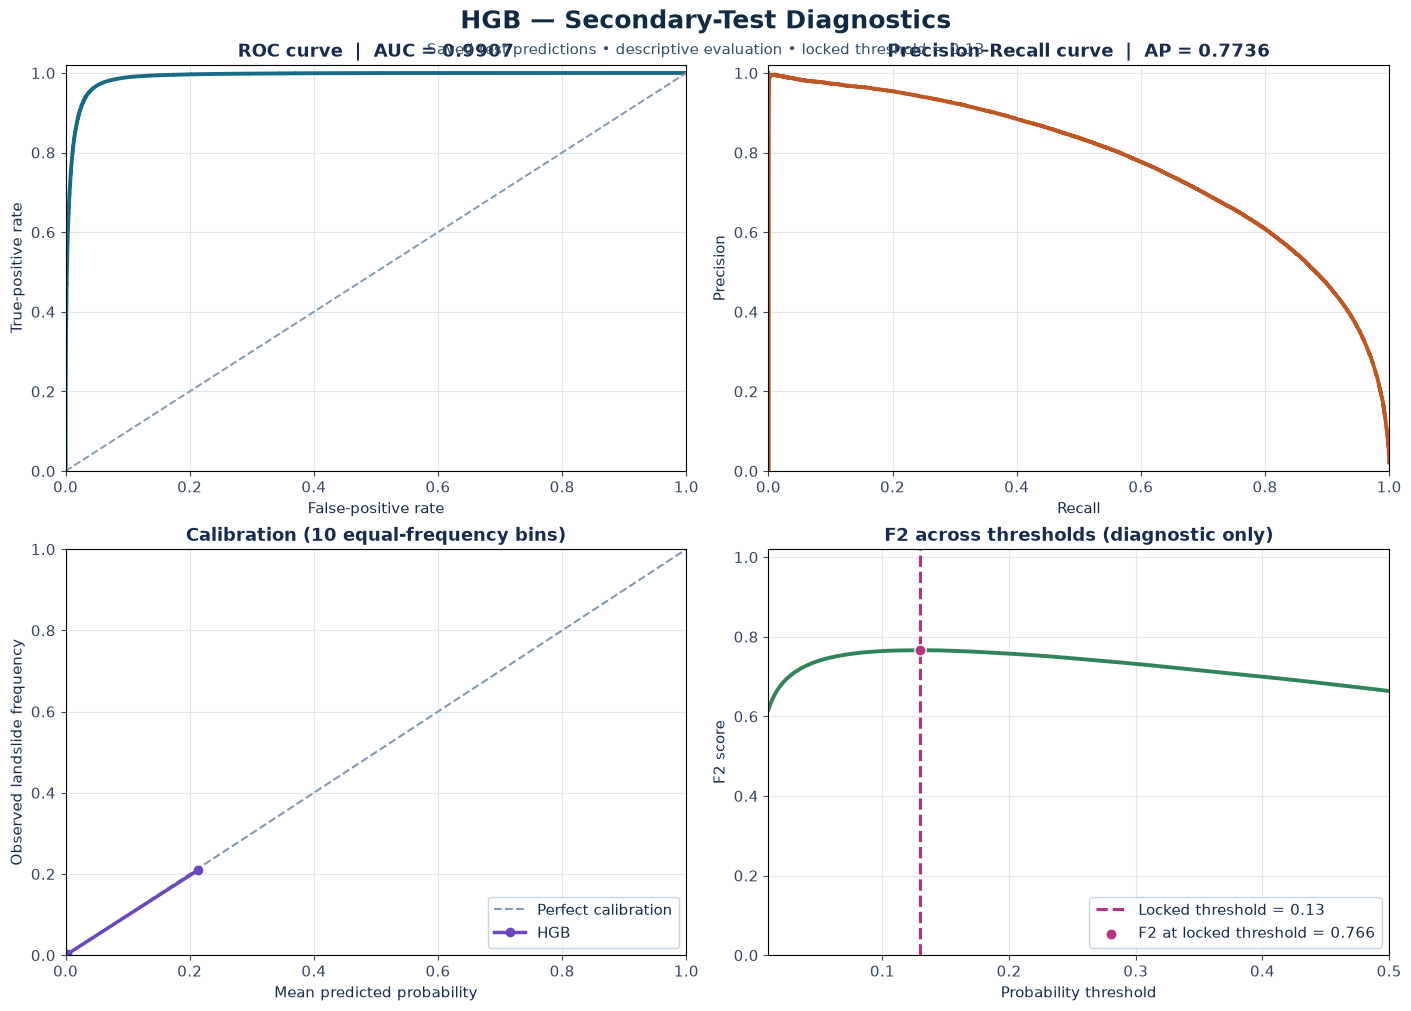

Evaluation pixels: 12,451,840
ROC-AUC: 0.990712
Average precision: 0.773601
F2 at locked threshold 0.13: 0.766319
The threshold curve is descriptive; the threshold was not changed.


In [22]:
# HGB secondary-test diagnostics — plotting only
# Uses the saved evaluation; does not retrain HGB or select a new threshold.

from pathlib import Path
from collections.abc import Mapping
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)
from sklearn.calibration import calibration_curve

LOCKED_THRESHOLD = 0.13
RANDOM_STATE = 43

# ---------- Find the saved evaluation ----------
project_dir = Path.cwd()
evaluation_files = list(
    (project_dir / "artifacts" / "hist_gradient_boosting" / "checkpoints")
    .rglob("evaluation.joblib")
)

if not evaluation_files:
    raise FileNotFoundError(
        "Could not find HGB evaluation.joblib. "
        "Run this cell from the project folder, or check the saved HGB artifact path."
    )

# Use the most recently modified saved evaluation.
evaluation_path = max(evaluation_files, key=lambda p: p.stat().st_mtime)
evaluation = joblib.load(evaluation_path)
evaluation_dir = evaluation_path.parent

print(f"Loaded saved evaluation: {evaluation_path}")

# ---------- Locate labels and probabilities inside the saved evaluation ----------
def walk_items(obj, parent_key=""):
    """Yield nested keys and values from dictionaries, lists, and simple objects."""
    if isinstance(obj, Mapping):
        for key, value in obj.items():
            key_text = str(key).lower()
            yield key_text, value
            yield from walk_items(value, key_text)
    elif isinstance(obj, (list, tuple)):
        for value in obj:
            yield parent_key, value
            yield from walk_items(value, parent_key)
    elif hasattr(obj, "__dict__") and not isinstance(obj, np.ndarray):
        yield from walk_items(vars(obj), parent_key)


def load_array_value(value, base_dir):
    """Load an array directly or from a saved .npy path."""
    if isinstance(value, np.ndarray):
        return value

    if isinstance(value, (str, Path)):
        path = Path(value)
        possibilities = [path] if path.is_absolute() else [base_dir / path, path]
        for candidate in possibilities:
            if candidate.is_file() and candidate.suffix.lower() == ".npy":
                return np.load(candidate, mmap_mode="r")

    return None


items = list(walk_items(evaluation))

label_candidates = []
score_candidates = []

for key, value in items:
    array = load_array_value(value, evaluation_dir)
    if array is None:
        continue

    key_lower = key.lower()

    if any(word in key_lower for word in ("label", "y_true", "target", "ground_truth")):
        label_candidates.append((key_lower, array))

    if any(word in key_lower for word in ("score", "prob", "y_pred", "probability")):
        score_candidates.append((key_lower, array))


def choose_candidate(candidates, preferred_words):
    if not candidates:
        return None
    for preferred in preferred_words:
        for key, array in candidates:
            if preferred in key:
                return array
    return candidates[0][1]


y_true_raw = choose_candidate(
    label_candidates,
    ("labels.npy", "y_true", "label"),
)
y_score_raw = choose_candidate(
    score_candidates,
    ("scores.npy", "y_score", "prob"),
)

# If the evaluation object stores file paths indirectly, use the standard saved filenames.
if y_true_raw is None:
    label_path = evaluation_dir / "labels.npy"
    if label_path.exists():
        y_true_raw = np.load(label_path, mmap_mode="r")

if y_score_raw is None:
    score_path = evaluation_dir / "scores.npy"
    if score_path.exists():
        y_score_raw = np.load(score_path, mmap_mode="r")

if y_true_raw is None or y_score_raw is None:
    raise KeyError(
        "Could not locate saved labels and scores in evaluation.joblib or beside it. "
        f"Evaluation folder: {evaluation_dir}"
    )

y_true = np.asarray(y_true_raw).reshape(-1).astype(np.uint8)
y_score = np.asarray(y_score_raw)

# If scores have two columns, use the probability for class 1 (landslide).
if y_score.ndim == 2 and y_score.shape[1] == 2:
    y_score = y_score[:, 1]

y_score = y_score.reshape(-1).astype(np.float64)

if len(y_true) != len(y_score):
    raise ValueError(
        f"Labels and scores have different lengths: {len(y_true):,} vs {len(y_score):,}"
    )

if not np.isfinite(y_score).all():
    raise ValueError("Saved scores contain NaN or infinite values.")

if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Saved labels must contain only 0 and 1.")

# ---------- Calculate diagnostic curves ----------
fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = roc_auc_score(y_true, y_score)

precision, recall, _ = precision_recall_curve(y_true, y_score)
average_precision = average_precision_score(y_true, y_score)

fraction_positive, mean_predicted = calibration_curve(
    y_true,
    y_score,
    n_bins=10,
    strategy="quantile",
)

# Threshold curve is descriptive only. The locked threshold remains 0.13.
# A score histogram avoids repeatedly scanning millions of pixels.
n_bins = 2000
hist_edges = np.linspace(0.0, 1.0, n_bins + 1)
positive_hist, _ = np.histogram(
    y_score[y_true == 1], bins=hist_edges
)
negative_hist, _ = np.histogram(
    y_score[y_true == 0], bins=hist_edges
)

tp_at_bin = np.cumsum(positive_hist[::-1])[::-1]
fp_at_bin = np.cumsum(negative_hist[::-1])[::-1]
total_positive = int(np.sum(y_true == 1))
fn_at_bin = total_positive - tp_at_bin

thresholds = hist_edges[:-1]
precision_by_threshold = tp_at_bin / np.maximum(tp_at_bin + fp_at_bin, 1)
recall_by_threshold = tp_at_bin / max(total_positive, 1)
f2_by_threshold = (
    5 * precision_by_threshold * recall_by_threshold
    / np.maximum(4 * precision_by_threshold + recall_by_threshold, 1e-12)
)

locked_bin = np.searchsorted(hist_edges, LOCKED_THRESHOLD, side="right") - 1
locked_bin = int(np.clip(locked_bin, 0, n_bins - 1))
locked_f2 = float(f2_by_threshold[locked_bin])

# ---------- Draw a clean, readable 2×2 figure ----------
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "text.color": "#172B4D",
    "axes.labelcolor": "#172B4D",
    "xtick.color": "#344563",
    "ytick.color": "#344563",
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    constrained_layout=True,
)

fig.suptitle(
    "HGB — Secondary-Test Diagnostics",
    fontsize=18,
    fontweight="bold",
    color="#102A43",
)

fig.text(
    0.5, 0.955,
    "Saved test predictions • descriptive evaluation • locked threshold = 0.13",
    ha="center",
    va="center",
    fontsize=11,
    color="#334E68",
)

# ROC
ax = axes[0, 0]
ax.plot(fpr, tpr, color="#176B87", linewidth=2.8)
ax.plot([0, 1], [0, 1], color="#829AB1", linewidth=1.4, linestyle="--")
ax.set(
    title=f"ROC curve  |  AUC = {roc_auc:.4f}",
    xlabel="False-positive rate",
    ylabel="True-positive rate",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.grid(True, color="#D9E2EC", linewidth=0.8, alpha=0.8)

# Precision–Recall
ax = axes[0, 1]
ax.plot(recall, precision, color="#C05621", linewidth=2.8)
ax.set(
    title=f"Precision–Recall curve  |  AP = {average_precision:.4f}",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.grid(True, color="#D9E2EC", linewidth=0.8, alpha=0.8)

# Calibration
ax = axes[1, 0]
ax.plot(
    [0, 1], [0, 1],
    color="#829AB1",
    linewidth=1.5,
    linestyle="--",
    label="Perfect calibration",
)
ax.plot(
    mean_predicted,
    fraction_positive,
    color="#6B46C1",
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="HGB",
)
ax.set(
    title="Calibration (10 equal-frequency bins)",
    xlabel="Mean predicted probability",
    ylabel="Observed landslide frequency",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#BCCCDC",
    labelcolor="#172B4D",
)
ax.grid(True, color="#D9E2EC", linewidth=0.8, alpha=0.8)

# F2 by threshold — diagnostic display; threshold is not reselected here.
ax = axes[1, 1]
display_mask = (thresholds >= 0.01) & (thresholds <= 0.50)
ax.plot(
    thresholds[display_mask],
    f2_by_threshold[display_mask],
    color="#2F855A",
    linewidth=2.8,
)
ax.axvline(
    LOCKED_THRESHOLD,
    color="#B83280",
    linewidth=2.2,
    linestyle="--",
    label=f"Locked threshold = {LOCKED_THRESHOLD:.2f}",
)
ax.scatter(
    [LOCKED_THRESHOLD],
    [locked_f2],
    color="#B83280",
    s=65,
    zorder=5,
    edgecolor="white",
    linewidth=1,
    label=f"F2 at locked threshold = {locked_f2:.3f}",
)
ax.set(
    title="F2 across thresholds (diagnostic only)",
    xlabel="Probability threshold",
    ylabel="F2 score",
    xlim=(0.01, 0.50),
    ylim=(0, 1.02),
)
ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#BCCCDC",
    labelcolor="#172B4D",
)
ax.grid(True, color="#D9E2EC", linewidth=0.8, alpha=0.8)

# Keep text and legends inside their own clear areas.
fig.savefig(
    evaluation_dir / "hgb_secondary_test_diagnostics_v3.png",
    dpi=220,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

print(f"Evaluation pixels: {len(y_true):,}")
print(f"ROC-AUC: {roc_auc:.6f}")
print(f"Average precision: {average_precision:.6f}")
print(f"F2 at locked threshold {LOCKED_THRESHOLD:.2f}: {locked_f2:.6f}")
print("The threshold curve is descriptive; the threshold was not changed.")

Secondary-test diagnostics (2 × 2 panel)

Result: Using 12,451,840 test pixels, the locked model shows excellent ranking ability (ROC-AUC = 0.9907) and good precision–recall performance (AP = 0.7736). The F2 curve is flat around its peak, and the locked threshold of 0.13 gives F2 = 0.766, at or very near the maximum. This confirms that the threshold chosen on development data transfers well to the test set. The threshold curve is descriptive only; the threshold was not changed.

Two problems with this figure you may want to fix before using it:

The calibration panel is not informative. It shows only two points, because about 98% of pixels have scores near 0. With equal-frequency bins, most bin edges collapse into the same value and get merged, leaving almost nothing to plot. The earlier figure, with 15 uniform bins (ECE = 0.0018, MCE = 0.0865), shows calibration properly. I’d either keep that version or replace this panel with the uniform-bin one.

,image_id,reference_landslide_pixels,predicted_landslide_pixels,TP,FP,FN,TN,F2,Precision,Recall,IoU,reference_coverage_percent,false_positive_rate_percent
0,523,8,29,0,29,8,16347,0.0,0.0,0.0,0.0,0.0488,0.1771
1,3713,59,23,0,23,59,16302,0.0,0.0,0.0,0.0,0.3601,0.1409
2,2322,2,190,0,190,2,16192,0.0,0.0,0.0,0.0,0.0122,1.1598
3,68,81,52,0,52,81,16251,0.0,0.0,0.0,0.0,0.4944,0.3190
4,696,5,6,0,6,5,16373,0.0,0.0,0.0,0.0,0.0305,0.0366
...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,3201,0,0,0,0,0,16384,NaN,NaN,NaN,NaN,0.0000,0.0000
756,3668,0,0,0,0,0,16384,NaN,NaN,NaN,NaN,0.0000,0.0000
757,1626,0,23,0,23,0,16361,NaN,0.0,NaN,NaN,0.0000,0.1404
758,2377,0,0,0,0,0,16384,NaN,NaN,NaN,NaN,0.0000,0.0000


Test images: 760
Images with reference landslides: 446
Images without reference landslides: 314
Mean F2 on images with reference landslides: 0.6542
Median F2 on images with reference landslides: 0.7011
Median false-positive pixels on images without reference landslides: 5
Images without landslides and with zero false positives: 105


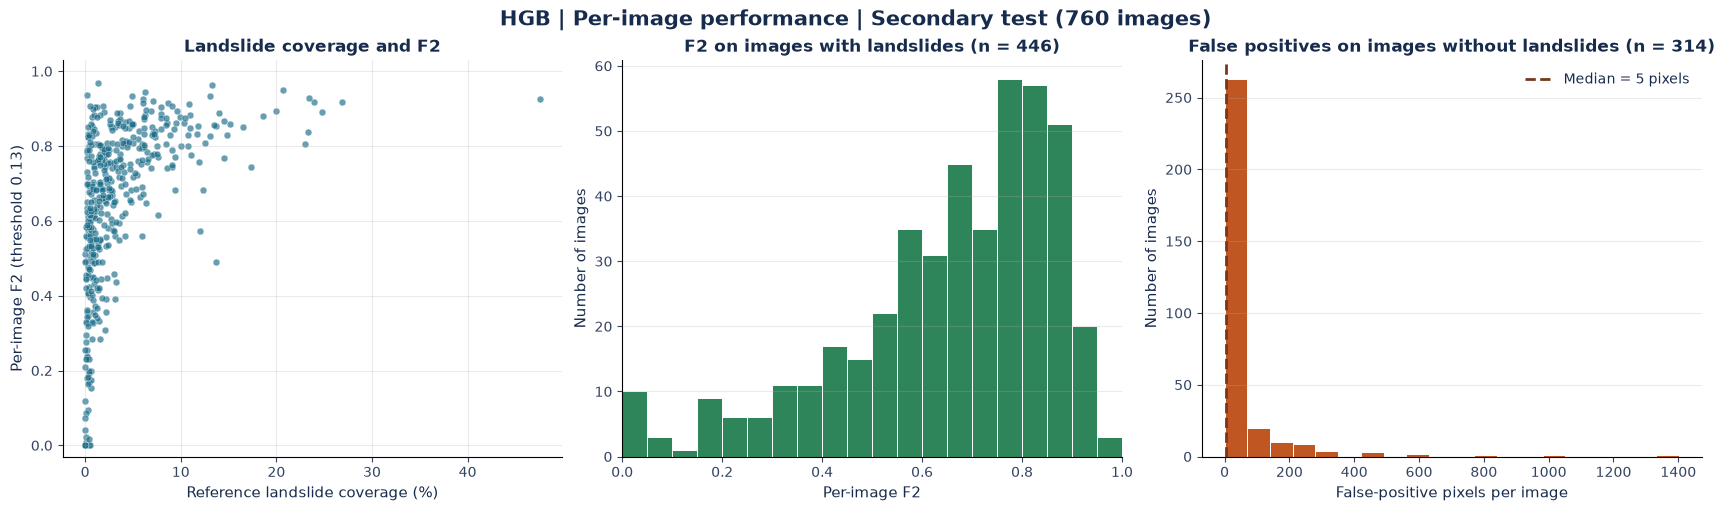

Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\final_model\8dddd78f56454fa62513\secondary_test\d73d65ca6143672e1b4e\per_image


In [30]:
# HGB — Step 16: per-image secondary-test analysis (replaces the two earlier per-image/2×2 cells).
# Uses the saved per-image confusion counts only. No prediction, no threshold change.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as show_table


def hgb_per_image_metrics(counts_table):
    """Per-image metrics with undefined values set to NaN, not 0."""
    table = counts_table.copy()
    table["image_id"] = table["image_id"].astype(str)

    tp = table["TP"].to_numpy(dtype=float)
    fp = table["FP"].to_numpy(dtype=float)
    fn = table["FN"].to_numpy(dtype=float)
    tn = table["TN"].to_numpy(dtype=float)

    reference = tp + fn
    predicted = tp + fp
    negatives = tn + fp
    has_reference = reference > 0

    with np.errstate(divide="ignore", invalid="ignore"):
        table["reference_landslide_pixels"] = reference.astype(np.int64)
        table["predicted_landslide_pixels"] = predicted.astype(np.int64)
        table["has_reference_landslide"] = has_reference
        table["F2"] = np.where(
            has_reference, 5 * tp / (5 * tp + 4 * fn + fp), np.nan
        )
        table["Precision"] = np.where(predicted > 0, tp / predicted, np.nan)
        table["Recall"] = np.where(has_reference, tp / reference, np.nan)
        table["IoU"] = np.where(
            has_reference, tp / (tp + fp + fn), np.nan
        )
        table["reference_coverage_percent"] = (
            100 * reference / table["n_pixels"].to_numpy(dtype=float)
        )
        table["false_positive_rate_percent"] = np.where(
            negatives > 0, 100 * fp / negatives, np.nan
        )

    return table


hgb_test_per_image = hgb_per_image_metrics(hgb_secondary_result["per_image"])

# Consistency with the saved pooled test result.
assert hgb_test_per_image["image_id"].tolist() == [
    str(value) for value in hgb_secondary_result["ordered_image_ids"]
]
for name in ("TN", "FP", "FN", "TP"):
    assert int(hgb_test_per_image[name].sum()) == hgb_secondary_result["counts"][name]
assert int(hgb_test_per_image["n_pixels"].sum()) == hgb_secondary_result["n_pixels"]

positive_images = hgb_test_per_image["has_reference_landslide"].to_numpy()
negative_images = ~positive_images

display_columns = [
    "image_id", "reference_landslide_pixels", "predicted_landslide_pixels",
    "TP", "FP", "FN", "TN", "F2", "Precision", "Recall", "IoU",
    "reference_coverage_percent", "false_positive_rate_percent",
]
show_table(
    hgb_test_per_image[display_columns]
    .sort_values("F2", na_position="last")
    .reset_index(drop=True)
    .round(4)
)

print(f"Test images: {len(hgb_test_per_image)}")
print(f"Images with reference landslides: {positive_images.sum()}")
print(f"Images without reference landslides: {negative_images.sum()}")
print(
    "Mean F2 on images with reference landslides: "
    f"{hgb_test_per_image.loc[positive_images, 'F2'].mean():.4f}"
)
print(
    "Median F2 on images with reference landslides: "
    f"{hgb_test_per_image.loc[positive_images, 'F2'].median():.4f}"
)
print(
    "Median false-positive pixels on images without reference landslides: "
    f"{hgb_test_per_image.loc[negative_images, 'FP'].median():,.0f}"
)
print(
    "Images without landslides and with zero false positives: "
    f"{int((hgb_test_per_image.loc[negative_images, 'FP'] == 0).sum())}"
)

hgb_per_image_folder = hgb_test_directory / "per_image"
hgb_per_image_folder.mkdir(parents=True, exist_ok=True)
hgb_test_per_image.to_csv(
    hgb_per_image_folder / "hgb_test_per_image.csv", index=False
)

with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

    ax = axes[0]
    ax.scatter(
        hgb_test_per_image.loc[positive_images, "reference_coverage_percent"],
        hgb_test_per_image.loc[positive_images, "F2"],
        s=24, alpha=0.65, color="#176B87",
        edgecolor="white", linewidth=0.35,
    )
    ax.set_title("Landslide coverage and F2")
    ax.set_xlabel("Reference landslide coverage (%)")
    ax.set_ylabel("Per-image F2 (threshold 0.13)")
    ax.set_ylim(-0.03, 1.03)
    ax.grid(True, alpha=0.25)

    ax = axes[1]
    ax.hist(
        hgb_test_per_image.loc[positive_images, "F2"],
        bins=np.linspace(0, 1, 21),
        color="#2F855A", edgecolor="white", linewidth=0.7,
    )
    ax.set_title(f"F2 on images with landslides (n = {positive_images.sum()})")
    ax.set_xlabel("Per-image F2")
    ax.set_ylabel("Number of images")
    ax.set_xlim(0, 1)
    ax.grid(axis="y", alpha=0.25)

    ax = axes[2]
    negative_fp = hgb_test_per_image.loc[negative_images, "FP"]
    ax.hist(negative_fp, bins=20, color="#C05621", edgecolor="white", linewidth=0.7)
    ax.axvline(
        negative_fp.median(), color="#7B341E", linewidth=2, linestyle="--",
        label=f"Median = {negative_fp.median():,.0f} pixels",
    )
    ax.set_title(f"False positives on images without landslides (n = {negative_images.sum()})")
    ax.set_xlabel("False-positive pixels per image")
    ax.set_ylabel("Number of images")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.25)

    fig.suptitle(
        "HGB | Per-image performance | Secondary test (760 images)",
        fontsize=15, fontweight="bold",
    )

    for extension in ("png", "pdf"):
        fig.savefig(
            hgb_per_image_folder / f"hgb_test_per_image.{extension}",
            dpi=300, bbox_inches="tight", facecolor="white",
        )
    plt.show()

print("Saved:", hgb_per_image_folder)

Per-image performance on the secondary test

Result: Of the 760 test images, 446 contain reference landslides and 314 do not. On images with landslides, the mean per-image F2 is 0.654. This is lower than the pooled pixel-level F2 (0.766) because each image counts equally here, including images with very small landslides.

Performance depends strongly on landslide size. Images with more than about 5% landslide coverage mostly reach F2 between 0.7 and 0.95. Images with very small coverage (below about 2%) vary widely, from complete misses (F2 = 0) to very good detection. The F2 distribution is skewed toward high values, with most images between 0.6 and 0.9. About 10 images have F2 near 0; these are mainly very small landslides of only a few to a few dozen pixels.

On images without landslides, false alarms are generally small: the median is 5 false-positive pixels per image, and most images have fewer than about 50. Only a few images contain several hundred to about 1,400 false-positive pixels.

In [27]:
import numpy as np

print("Possible image or feature arrays:")
for name, obj in list(globals().items()):
    if isinstance(obj, np.ndarray) and obj.ndim >= 2:
        shape = obj.shape
        if (
            (len(shape) >= 3 and shape[-1] == 14)
            or (len(shape) == 2 and shape[-1] == 14)
        ):
            print(f"  {name}: shape={shape}, dtype={obj.dtype}")

print("\nPossible fitted models:")
for name, obj in list(globals().items()):
    if callable(getattr(obj, "predict_proba", None)):
        print(f"  {name}: {type(obj).__name__}")

print("\nEvaluation metadata:")
if "evaluation" in globals():
    if isinstance(evaluation, dict):
        print("  keys:", list(evaluation.keys()))
    else:
        print("  type:", type(evaluation).__name__)
else:
    print("  evaluation variable is not loaded")

Possible image or feature arrays:
  hgb_X_by_image: shape=(3039, 1024, 14), dtype=float32
  image_X: shape=(16384, 14), dtype=float32
  image_features: shape=(16384, 14), dtype=float32

Possible fitted models:
  HistGradientBoostingClassifier: ABCMeta
  hgb_pilot_model: HistGradientBoostingClassifier
  hgb_final_model: HistGradientBoostingClassifier

Evaluation metadata:
  keys: ['specification', 'threshold', 'ordered_image_ids', 'metrics', 'counts', 'per_image', 'n_pixels', 'F2_bootstrap_95_interval', 'bootstrap_F2', 'scores_path', 'labels_path', 'evaluation_seconds']


In [28]:
import numpy as np

print("Arrays that may contain sampled development labels or test data:")
for name, obj in list(globals().items()):
    if isinstance(obj, np.ndarray):
        shape = obj.shape
        name_lower = name.lower()

        relevant_name = any(
            word in name_lower
            for word in ("label", "target", "mask", "test", "y_", "hgb_y")
        )
        relevant_shape = (
            shape in ((3039, 1024), (3039, 1024, 1))
            or (len(shape) >= 3 and shape[0] == 760 and shape[-1] == 14)
            or (len(shape) == 2 and shape == (760 * 128 * 128, 14))
        )

        if relevant_name or relevant_shape:
            print(f"{name}: shape={shape}, dtype={obj.dtype}")

Arrays that may contain sampled development labels or test data:
hgb_X_by_image: shape=(3039, 1024, 14), dtype=float32
hgb_y_by_image: shape=(3039, 1024), dtype=uint8
block_labels: shape=(2,), dtype=uint8
selected_mask: shape=(6,), dtype=bool
test_bootstrap_f2: shape=(2000,), dtype=float64
test_interval: shape=(2,), dtype=float64
overlay_axes: shape=(6, 3), dtype=object
labels: shape=(760, 16384), dtype=uint8
fn_by_threshold: shape=(101,), dtype=int64
tn_by_threshold: shape=(101,), dtype=int64
tp_by_threshold: shape=(101,), dtype=int64
fp_by_threshold: shape=(101,), dtype=int64
f2_by_threshold: shape=(2000,), dtype=float64
precision_by_threshold: shape=(2000,), dtype=float64
recall_by_threshold: shape=(2000,), dtype=float64
specificity_by_threshold: shape=(101,), dtype=float64
iou_by_threshold: shape=(101,), dtype=float64
specificity_threshold_curve: shape=(101,), dtype=float64
y_true_raw: shape=(760, 16384), dtype=uint8
y_score_raw: shape=(760, 16384), dtype=float64
y_true: shape=(124

Sampling pixels from 760 test images...
  Loaded 100/760 images
  Loaded 200/760 images
  Loaded 300/760 images
  Loaded 400/760 images
  Loaded 500/760 images
  Loaded 600/760 images
  Loaded 700/760 images
  Loaded 760/760 images
Evaluation pixels: 1,556,480 | landslide pixels: 32,945 (2.12%)
Baseline prediction...
Baseline on sample | F2 = 0.7642 (full test: 0.7663) | AP = 0.7693
       B1 | repeat 1/3 | F2 = 0.5761 | AP = 0.5293 | 17 s
       B1 | repeat 2/3 | F2 = 0.5797 | AP = 0.5317 | 42 s
       B1 | repeat 3/3 | F2 = 0.5790 | AP = 0.5305 | 69 s
       B2 | repeat 1/3 | F2 = 0.7324 | AP = 0.7005 | 80 s
       B2 | repeat 2/3 | F2 = 0.7322 | AP = 0.7000 | 105 s
       B2 | repeat 3/3 | F2 = 0.7324 | AP = 0.7006 | 146 s
       B3 | repeat 1/3 | F2 = 0.7582 | AP = 0.7563 | 188 s
       B3 | repeat 2/3 | F2 = 0.7585 | AP = 0.7567 | 206 s
       B3 | repeat 3/3 | F2 = 0.7587 | AP = 0.7562 | 216 s
       B4 | repeat 1/3 | F2 = 0.3519 | AP = 0.2753 | 246 s
       B4 | repeat 2/3 | F2 

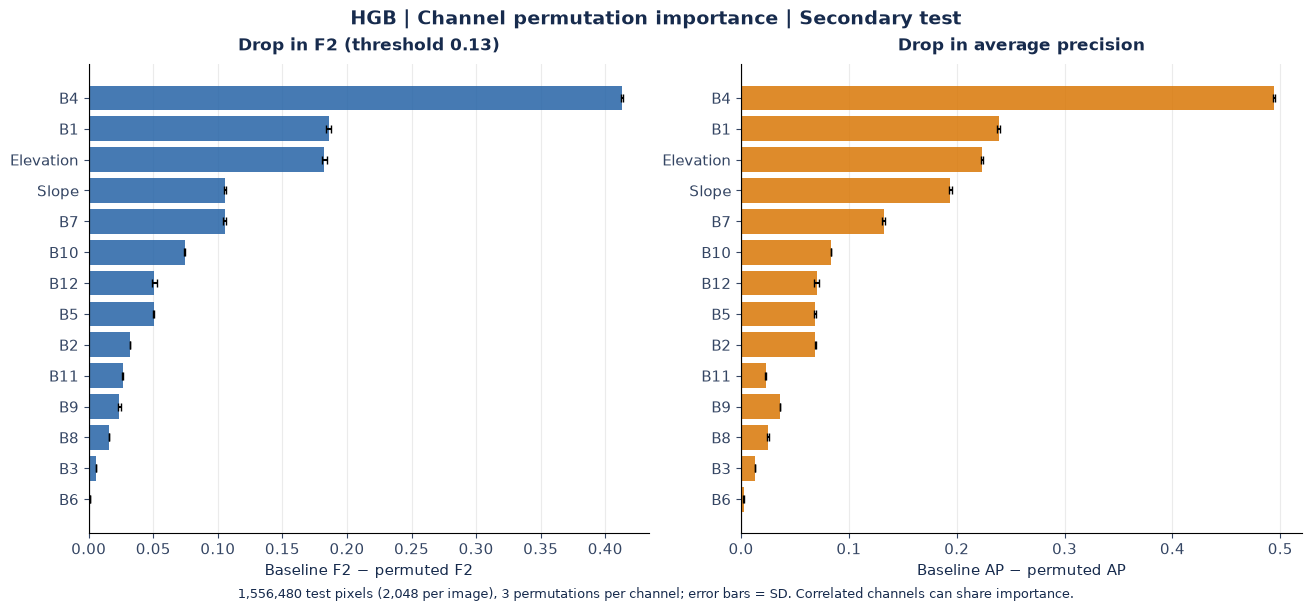


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\hist_gradient_boosting\checkpoints\nested_search_ac6da39f5e01056e4253\final_model\8dddd78f56454fa62513\permutation_importance\f7e1bf69fddea27b87c9
Diagnostic only — the model and threshold were not changed.


In [29]:
# HGB — Step 14: channel permutation importance on the secondary test.
# Locked final model and locked threshold 0.13.
# No training, tuning, calibration, or threshold changes. Diagnostic only.

import os
import time
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from threadpoolctl import threadpool_limits

HGB_PI_PIXELS_PER_IMAGE = 2048   # uniform random pixels per test image (of 16,384)
HGB_PI_REPEATS = 3               # independent permutations per channel
HGB_PI_SEED = 43

# ------------------------------------------------------------
# 1. Locked model and consistency checks
# ------------------------------------------------------------
if "hgb_final_model" not in globals():
    hgb_final_model = joblib.load(hgb_final_model_file)["model"]

hgb_pi_threshold = float(hgb_final_specification["threshold"])
hgb_pi_test_ids = list(hgb_secondary_test_ids)

assert hgb_pi_threshold == 0.13
assert hgb_final_model.n_features_in_ == len(hgb_feature_names) == 14
assert len(hgb_pi_test_ids) == len(set(hgb_pi_test_ids)) == 760
assert set(hgb_pi_test_ids).isdisjoint(hgb_development_id_set)

hgb_pi_specification = {
    "version": "hgb_channel_permutation_importance_v1",
    "locked_model": hgb_final_specification,
    "test_ids": hgb_pi_test_ids,
    "pixels_per_image": HGB_PI_PIXELS_PER_IMAGE,
    "repeats": HGB_PI_REPEATS,
    "seed": HGB_PI_SEED,
    "features": hgb_feature_names,
}

hgb_pi_folder = (
    hgb_final_model_directory / "permutation_importance"
    / hgb_signature(hgb_pi_specification)
)
hgb_pi_folder.mkdir(parents=True, exist_ok=True)

hgb_pi_sample_file = hgb_pi_folder / "sample.npz"
hgb_pi_results_file = hgb_pi_folder / "results.joblib"

# ------------------------------------------------------------
# 2. Build (or restore) a fixed pixel sample from all test images
# ------------------------------------------------------------
if hgb_pi_sample_file.is_file():
    with np.load(hgb_pi_sample_file) as data:
        hgb_pi_X = np.array(data["X"])
        hgb_pi_y = np.array(data["y"])
    print("Saved test-pixel sample restored.")

else:
    rng = np.random.default_rng(HGB_PI_SEED)
    X_parts, y_parts = [], []

    print("Sampling pixels from 760 test images...", flush=True)
    for index, image_id in enumerate(hgb_pi_test_ids, start=1):
        image_X, image_y = hgb_load_source_pair(image_id)
        rows = rng.choice(
            image_X.shape[0], size=HGB_PI_PIXELS_PER_IMAGE, replace=False
        )
        X_parts.append(image_X[rows])
        y_parts.append(image_y[rows])

        if index % 100 == 0 or index == 760:
            print(f"  Loaded {index}/760 images", flush=True)

    hgb_pi_X = np.concatenate(X_parts).astype(np.float32)
    hgb_pi_y = np.concatenate(y_parts).astype(np.uint8)
    del X_parts, y_parts

    temporary = hgb_pi_folder / "sample_tmp.npz"
    np.savez(temporary, X=hgb_pi_X, y=hgb_pi_y)
    os.replace(temporary, hgb_pi_sample_file)

assert hgb_pi_X.shape == (760 * HGB_PI_PIXELS_PER_IMAGE, 14)
assert np.isfinite(hgb_pi_X).all()

hgb_pi_positive = hgb_pi_y == 1
print(
    f"Evaluation pixels: {len(hgb_pi_y):,} | "
    f"landslide pixels: {int(hgb_pi_positive.sum()):,} "
    f"({hgb_pi_positive.mean() * 100:.2f}%)"
)


def hgb_pi_evaluate(X_eval):
    """F2 at the locked threshold and average precision."""
    with threadpool_limits(limits=HGB_THREADS):
        probability = hgb_final_model.predict_proba(X_eval)[:, 1]

    predicted = probability >= hgb_pi_threshold
    tp = np.count_nonzero(predicted & hgb_pi_positive)
    fp = np.count_nonzero(predicted & ~hgb_pi_positive)
    fn = np.count_nonzero(~predicted & hgb_pi_positive)

    return {
        "F2": float(hgb_ratio(5 * tp, 5 * tp + 4 * fn + fp)),
        "AP": float(average_precision_score(hgb_pi_y, probability)),
    }


# ------------------------------------------------------------
# 3. Baseline and channel permutations (resumable)
# ------------------------------------------------------------
if hgb_pi_results_file.is_file():
    hgb_pi_results = joblib.load(hgb_pi_results_file)
    assert hgb_pi_results["specification"] == hgb_pi_specification
else:
    hgb_pi_results = {
        "specification": hgb_pi_specification,
        "baseline": None,
        "permuted": {},
    }

if hgb_pi_results["baseline"] is None:
    print("Baseline prediction...", flush=True)
    hgb_pi_results["baseline"] = hgb_pi_evaluate(hgb_pi_X)
    hgb_atomic_save(hgb_pi_results, hgb_pi_results_file)

baseline = hgb_pi_results["baseline"]
print(
    f"Baseline on sample | F2 = {baseline['F2']:.4f} "
    f"(full test: {hgb_secondary_result['metrics']['F2']:.4f}) | "
    f"AP = {baseline['AP']:.4f}"
)

started = time.perf_counter()

for column, name in enumerate(hgb_feature_names):
    for repeat in range(HGB_PI_REPEATS):
        key = f"{name}|{repeat}"
        if key in hgb_pi_results["permuted"]:
            continue

        # Seed per channel and repeat, so resuming gives identical permutations.
        rng = np.random.default_rng([HGB_PI_SEED, column, repeat])
        original = hgb_pi_X[:, column].copy()

        hgb_pi_X[:, column] = original[rng.permutation(len(original))]
        try:
            hgb_pi_results["permuted"][key] = hgb_pi_evaluate(hgb_pi_X)
        finally:
            hgb_pi_X[:, column] = original   # always restore the channel

        hgb_atomic_save(hgb_pi_results, hgb_pi_results_file)

        result = hgb_pi_results["permuted"][key]
        print(
            f"{name:>9} | repeat {repeat + 1}/{HGB_PI_REPEATS} | "
            f"F2 = {result['F2']:.4f} | AP = {result['AP']:.4f} | "
            f"{time.perf_counter() - started:.0f} s",
            flush=True
        )

# ------------------------------------------------------------
# 4. Summary table
# ------------------------------------------------------------
rows = []
for name in hgb_feature_names:
    runs = [
        hgb_pi_results["permuted"][f"{name}|{r}"]
        for r in range(HGB_PI_REPEATS)
    ]
    f2_drop = np.array([baseline["F2"] - run["F2"] for run in runs])
    ap_drop = np.array([baseline["AP"] - run["AP"] for run in runs])

    rows.append({
        "Channel": name,
        "F2_drop_mean": f2_drop.mean(),
        "F2_drop_sd": f2_drop.std(ddof=1) if len(f2_drop) > 1 else 0.0,
        "AP_drop_mean": ap_drop.mean(),
        "AP_drop_sd": ap_drop.std(ddof=1) if len(ap_drop) > 1 else 0.0,
    })

hgb_pi_table = (
    pd.DataFrame(rows)
    .sort_values("F2_drop_mean", ascending=False)
    .reset_index(drop=True)
)
hgb_pi_table.to_csv(hgb_pi_folder / "channel_importance.csv", index=False)

print("\nCHANNEL PERMUTATION IMPORTANCE (drop from baseline; larger = more important)")
print(hgb_pi_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------
# 5. Figure
# ------------------------------------------------------------
with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
    order = hgb_pi_table.iloc[::-1]   # most important at the top

    for ax, metric, color, title in (
        (axes[0], "F2", "#2563A6", "Drop in F2 (threshold 0.13)"),
        (axes[1], "AP", "#D97706", "Drop in average precision"),
    ):
        ax.barh(
            order["Channel"], order[f"{metric}_drop_mean"],
            xerr=order[f"{metric}_drop_sd"],
            color=color, alpha=0.85, capsize=3
        )
        ax.axvline(0, color="#333333", linewidth=0.8)
        ax.set_xlabel(f"Baseline {metric} − permuted {metric}")
        ax.set_title(title, pad=10)
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)

    fig.suptitle(
        "HGB | Channel permutation importance | Secondary test",
        fontsize=14, fontweight="bold"
    )
    fig.supxlabel(
        f"{len(hgb_pi_y):,} test pixels ({HGB_PI_PIXELS_PER_IMAGE:,} per image), "
        f"{HGB_PI_REPEATS} permutations per channel; error bars = SD. "
        "Correlated channels can share importance.",
        fontsize=9
    )

    for extension in ("png", "pdf"):
        fig.savefig(
            hgb_pi_folder / f"channel_permutation_importance.{extension}",
            dpi=300, bbox_inches="tight", facecolor="white"
        )
    plt.show()

print("\nSaved:", hgb_pi_folder)
print("Diagnostic only — the model and threshold were not changed.")

Result: Shuffling single channels on 1,556,480 test pixels (3 permutations each) shows that the model relies most on B4. Permuting it lowers F2 by about 0.41 (from about 0.77 to about 0.36) and average precision by about 0.49. The next most important channels are B1 (F2 drop about 0.19), Elevation (about 0.18), Slope and B7 (about 0.10 each), so the two terrain features clearly add information beyond the spectral bands. B10, B12, B5, and B2 have moderate effects (F2 drops of about 0.03–0.08). B11, B9, B8, and especially B3 and B6 have almost no individual effect.

The ranking is nearly identical for F2 and average precision, and the error bars are very small, so the result is stable and not caused by random permutation noise.

Low importance does not necessarily mean a channel is useless. Neighbouring spectral bands are strongly correlated (for example B3 with B2/B4, and B6 with B5/B7), so when one is shuffled the model can rely on a correlated band instead. B3 and B6 are therefore better described as redundant given the other bands, not irrelevant. If the channels follow standard Sentinel-2 numbering, the dominance of B4 (red) is plausible, since fresh landslide scars expose bright bare soil and rock that contrast with vegetation in the red band.

In [31]:
# HGB — Step 17: export all HGB results in one standard format for the classifier comparison.
# Reads saved results only. No training, prediction, or threshold change.

import json
import numpy as np
import pandas as pd

hgb_export_folder = (
    hgb_project_path / "artifacts" / "classifier_comparison" / "hist_gradient_boosting"
)
hgb_export_folder.mkdir(parents=True, exist_ok=True)

metric_names = [
    "F2", "Precision", "Recall", "Specificity", "IoU",
    "ROC_AUC", "Average_precision", "Brier_score", "Log_loss",
]

# 1. Outer folds and fold mean ± SD.
hgb_export_folds = (
    hgb_outer_metrics_table[["Outer_fold", "Threshold"] + metric_names]
    .sort_values("Outer_fold")
    .reset_index(drop=True)
)
hgb_export_folds.insert(0, "Model", "HGB")
hgb_export_folds["Fit_seconds"] = [
    float(result["fit_seconds"])
    for result in sorted(hgb_outer_results, key=lambda r: int(r["outer_fold"]))
]

# 2. Per-image tables (needed for paired comparisons between classifiers).
hgb_export_outer_per_image = hgb_per_image_metrics(hgb_pooled_outer_summary["per_image"])
hgb_export_outer_per_image.insert(0, "Model", "HGB")
hgb_export_test_per_image = hgb_test_per_image.copy()
hgb_export_test_per_image.insert(0, "Model", "HGB")

assert len(hgb_export_outer_per_image) == 3039
assert set(hgb_export_outer_per_image["image_id"]) == hgb_development_id_set
assert len(hgb_export_test_per_image) == 760
assert set(hgb_export_test_per_image["image_id"]) == hgb_secondary_test_id_set

# 3. One summary row.
final_parameters = hgb_final_specification["parameters"]
final_fit_seconds_saved = float(joblib.load(hgb_final_model_file)["fit_seconds"])
outer_low, outer_high = hgb_pooled_outer_summary["F2_bootstrap_95_interval"]
test_low, test_high = hgb_secondary_result["F2_bootstrap_95_interval"]

summary_row = {
    "Model": "HGB",
    "Candidates_searched": len(hgb_candidate_parameters),
    "Base_model_fits": 114,
    "Selected_max_leaf_nodes": final_parameters["max_leaf_nodes"],
    "Selected_min_samples_leaf": final_parameters["min_samples_leaf"],
    "Selected_l2_regularization": final_parameters["l2_regularization"],
    "Learning_rate": final_parameters["learning_rate"],
    "Max_iter": final_parameters["max_iter"],
    "Threshold": float(hgb_final_specification["threshold"]),
    "Calibration": hgb_final_specification["calibration"],
    "Training_images": 3039,
    "Training_pixels": hgb_final_specification["training_pixels"],
    "Final_fit_seconds": final_fit_seconds_saved,
}

for name in metric_names:
    summary_row[f"Outer_pooled_{name}"] = float(hgb_pooled_outer_summary["metrics"][name])
for name in metric_names:
    values = hgb_export_folds[name].to_numpy(dtype=float)
    summary_row[f"Outer_fold_mean_{name}"] = float(values.mean())
    summary_row[f"Outer_fold_sd_{name}"] = float(values.std(ddof=1))
summary_row["Outer_F2_CI_low"] = float(outer_low)
summary_row["Outer_F2_CI_high"] = float(outer_high)

for name in metric_names:
    summary_row[f"Test_{name}"] = float(hgb_secondary_result["metrics"][name])
summary_row["Test_F2_CI_low"] = float(test_low)
summary_row["Test_F2_CI_high"] = float(test_high)

for name in ("TN", "FP", "FN", "TP"):
    summary_row[f"Outer_{name}"] = int(hgb_pooled_outer_summary["counts"][name])
    summary_row[f"Test_{name}"] = int(hgb_secondary_result["counts"][name])

hgb_export_summary = pd.DataFrame([summary_row])

# 4. Candidate search and channel importance.
hgb_export_candidates = hgb_final_selection["candidate_summary"].copy()
hgb_export_candidates.insert(0, "Model", "HGB")

hgb_export_importance = hgb_pi_table.copy()
hgb_export_importance.insert(0, "Model", "HGB")

# 5. Save CSV tables, one bundle, and a short manifest.
hgb_export_tables = {
    "hgb_summary": hgb_export_summary,
    "hgb_outer_folds": hgb_export_folds,
    "hgb_outer_per_image": hgb_export_outer_per_image,
    "hgb_test_per_image": hgb_export_test_per_image,
    "hgb_candidates": hgb_export_candidates,
    "hgb_channel_importance": hgb_export_importance,
}

for name, table in hgb_export_tables.items():
    table.to_csv(hgb_export_folder / f"{name}.csv", index=False)

hgb_atomic_save(
    {
        "tables": hgb_export_tables,
        "outer_bootstrap_F2": np.asarray(hgb_pooled_outer_summary["bootstrap_F2"]),
        "test_bootstrap_F2": np.asarray(hgb_secondary_result["bootstrap_F2"]),
        "outer_scores_path": hgb_pooled_outer_summary["scores_path"],
        "outer_labels_path": hgb_pooled_outer_summary["labels_path"],
        "outer_ordered_image_ids": list(hgb_pooled_outer_summary["ordered_image_ids"]),
        "test_scores_path": hgb_secondary_result["scores_path"],
        "test_labels_path": hgb_secondary_result["labels_path"],
        "test_ordered_image_ids": list(hgb_secondary_result["ordered_image_ids"]),
        "final_model_path": str(hgb_final_model_file),
        "locked_specification": hgb_final_specification,
    },
    hgb_export_folder / "hgb_comparison_bundle.joblib",
)

manifest = {
    "model": "HGB",
    "threshold": float(hgb_final_specification["threshold"]),
    "outer_split_source": str(hgb_state_file),
    "final_inner_split_source": str(hgb_split_file),
    "outer_scores_path": hgb_pooled_outer_summary["scores_path"],
    "test_scores_path": hgb_secondary_result["scores_path"],
    "final_model_path": str(hgb_final_model_file),
    "files": sorted(f"{name}.csv" for name in hgb_export_tables) + ["hgb_comparison_bundle.joblib"],
}
with open(hgb_export_folder / "manifest.json", "w", encoding="utf-8") as handle:
    json.dump(manifest, handle, indent=2)

print("HGB COMPARISON EXPORT")
print(
    f"Outer pooled F2 {summary_row['Outer_pooled_F2']:.4f} "
    f"[{outer_low:.4f}, {outer_high:.4f}] | "
    f"fold mean ± SD {summary_row['Outer_fold_mean_F2']:.4f} ± {summary_row['Outer_fold_sd_F2']:.4f}"
)
print(
    f"Test F2 {summary_row['Test_F2']:.4f} [{test_low:.4f}, {test_high:.4f}] | "
    f"Precision {summary_row['Test_Precision']:.4f} | Recall {summary_row['Test_Recall']:.4f}"
)
print("Saved files:")
for name in manifest["files"] + ["manifest.json"]:
    print("  ", hgb_export_folder / name)

HGB COMPARISON EXPORT
Outer pooled F2 0.7739 [0.7652, 0.7826] | fold mean ± SD 0.7737 ± 0.0145
Test F2 0.7663 [0.7471, 0.7845] | Precision 0.5274 | Recall 0.8642
Saved files:
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_gradient_boosting\hgb_candidates.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_gradient_boosting\hgb_channel_importance.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_gradient_boosting\hgb_outer_folds.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_gradient_boosting\hgb_outer_per_image.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_gradient_boosting\hgb_summary.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_gradient_boosting\hgb_test_per_image.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\hist_

## HGB — Interpretation and report summary

### Setup
Histogram gradient boosting (scikit-learn 1.9.0, `random_state = 43`) was trained on the 14 input channels (Sentinel-2 B1–B12, slope, elevation) using the saved pixel samples (1,024 pixels per image; 3,111,936 pixels from 3,039 development images). The sampled landslide fraction (2.36%) equals the fraction in the full images, so predicted probabilities are not distorted by sampling. Fixed settings: log-loss, learning rate 0.1, 150 iterations, no early stopping, no class weights, no additional calibration. Six candidates (max_leaf_nodes 15/31/63 × two regularization levels) and the decision threshold were selected by maximum pooled F2 (β = 2) in a 5 × 3 nested cross-validation with whole-image splits; 114 base-model fits in total. All validation and evaluation used every pixel of the assigned images.

### Model selection
Candidate 6 (max_leaf_nodes = 63, min_samples_leaf = 100, l2_regularization = 1.0) with threshold 0.13 was selected in all five outer folds and in the final development selection (pooled inner F2 = 0.7743). The selection is therefore very stable, but the margin is small: all six candidates reached F2 between 0.764 and 0.774. The final model was trained once on all development images (62.6 s) and locked before the secondary test.

### Results

| Metric | Outer evaluation (3,039 images) | Secondary test (760 images) |
|---|---|---|
| F2 (threshold 0.13) | 0.7739 [0.7652, 0.7826] | 0.7663 [0.7471, 0.7845] |
| Fold mean ± SD (F2) | 0.7737 ± 0.0145 | — |
| Precision | 0.5375 | 0.5274 |
| Recall | 0.8694 | 0.8642 |
| Specificity | 0.9819 | 0.9831 |
| IoU | 0.4974 | 0.4870 |
| ROC-AUC | 0.9905 | 0.9907 |
| Average precision | 0.7892 | 0.7736 |
| Brier score | 0.0096 | 0.0090 |
| Log loss | 0.0331 | 0.0311 |

Brackets: 95% whole-image bootstrap intervals (2,000 resamples; fitted model fixed).

### Interpretation
- **Detection vs. false alarms.** HGB detects about 86–87% of landslide pixels while rejecting about 98% of non-landslide pixels. Its main weakness is false positives: on the test set, 205,505 false-positive pixels against 229,339 true positives give a precision of about 53%, so roughly one in two predicted landslide pixels is incorrect. This trade-off is intended by the F2 objective, which weights recall more heavily than precision.
- **Stability.** F2 varies only moderately across outer folds (0.7552–0.7958), and the test F2 lies within the development bootstrap interval, so performance transfers to held-out images without a meaningful drop.
- **Ranking and calibration.** Ranking quality is very high (ROC-AUC ≈ 0.991; AP ≈ 0.77–0.79, far above the ≈ 2% landslide prevalence). Overall calibration is good (ECE = 0.0018), but this is dominated by the many non-landslide pixels with scores near zero. Mid-range scores are slightly underestimated (≈ 0.1–0.35) or overestimated (≈ 0.4–0.9; MCE = 0.0865), so they should not be read as exact probabilities.
- **Threshold.** On the test set, F2 has a broad, flat maximum around thresholds 0.10–0.15, so the locked threshold of 0.13 is close to optimal even though it was chosen on development data only. Higher thresholds would increase precision and IoU (IoU peaks at ≈ 0.54 near 0.3) at the cost of recall.
- **Per-image behaviour.** Of the 760 test images, 446 contain landslides and 314 do not. Mean per-image F2 on positive images is 0.654, lower than the pooled F2 because every image counts equally. Performance depends strongly on landslide size: images with more than ≈ 5% landslide coverage mostly reach F2 of 0.7–0.95, whereas very small landslides (a few to a few dozen pixels) are often missed. On images without landslides, false alarms are usually small (median 5 pixels), with a few images showing several hundred to ≈ 1,400 false-positive pixels.
- **Channel importance.** Permutation importance on 1,556,480 test pixels (3 repeats) shows that HGB relies most on B4 (F2 drop 0.413), followed by B1 (0.186), elevation (0.182), slope (0.106), and B7 (0.105). B10, B12, B5, and B2 have moderate effects (0.03–0.07), while B11, B9, B8, B3, and B6 have little individual effect (< 0.03). The dominance of B4 (red) is physically plausible, because fresh landslide scars expose bright bare soil and rock. The high importance of B1 and B10, which are 60 m atmospheric bands, likely reflects scene-level differences between study areas rather than landslide-specific spectral properties. Low importance of B3 and B6 indicates redundancy with correlated neighbouring bands, not irrelevance.

### Limitations
1. The six-candidate grid was deliberately compact; the selected configuration lies at its boundary, `min_samples_leaf` and `l2_regularization` were varied together, and learning rate and iteration count were fixed. Slightly better settings may exist, although all candidates differed by less than 0.01 F2.
2. The secondary-test images are a random image-level split from the same study areas as the development images. The results therefore describe transfer to new images from the same regions, not to new regions.
3. Bootstrap intervals keep the fitted model fixed and treat images as independent; retraining uncertainty and spatial dependence between neighbouring images are not included.
4. The model is pixel-based and uses no spatial context, which contributes to scattered false positives and missed very small landslides.

### Notes for the classifier comparison
- All HGB results are exported in `artifacts/classifier_comparison/hist_gradient_boosting/` (summary, outer folds, per-image tables, candidates, channel importance, score paths).
- Outer folds come from the saved project state (`landslide_handoff_…/project_state.joblib`). Before comparing HGB with RF or LR, confirm that all classifiers used the same outer folds and the same 760 test images.
- Differences between classifiers should be tested with a paired whole-image bootstrap (the same resampled images for every model), using the exported per-image counts. Unpaired intervals alone cannot show whether small differences, such as HGB 0.7739 vs. RF 0.7761 outer F2, are meaningful.